In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import os
import seaborn as sns
from scipy.stats import trim_mean

from sklearn.mixture import GaussianMixture
import numpy as np


In [ ]:
adata = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned.h5ad", backed="r")

In [ ]:
adata = adata[adata.obs["experiment"] == "deepdive"].to_memory().copy()

In [ ]:
adata = adata[adata.obs["CAGLENGTH"].notna()].copy()

In [ ]:
adata.obs["DONOR"].value_counts()

DONOR
S06758    5269
S12365    3294
S04577    2894
S05202    2549
S07681    1549
S02205    1241
S09619    1033
S04002     691
S05368     680
Name: count, dtype: int64

In [ ]:
zone_6_indices = adata.obs[~adata.obs["mapping_coupling_for_zoning"].isna()].index
zone_4_indices = adata.obs[~adata.obs["mapping_coupling_for_zoning_4_zones"].isna()].index

adata.obs["mapping_coupling_for_zoning_mixed"] = pd.Series(index=adata.obs.index, dtype=object)
adata.obs["zone_mixed"] = pd.Series(index=adata.obs.index, dtype=object)


adata.obs.loc[zone_6_indices, "mapping_coupling_for_zoning_mixed"] = adata.obs.loc[zone_6_indices, "mapping_coupling_for_zoning"].astype(str)
adata.obs.loc[zone_4_indices, "mapping_coupling_for_zoning_mixed"] = adata.obs.loc[zone_4_indices, "mapping_coupling_for_zoning_4_zones"].astype(str)
adata.obs.loc[zone_6_indices, "zone_mixed"] = adata.obs.loc[zone_6_indices, "zone"].astype(str)
adata.obs.loc[zone_4_indices, "zone_mixed"] = adata.obs.loc[zone_4_indices, "zone_4"].astype(str)

adata.obs["mapping_coupling_for_zoning_mixed"] = adata.obs["mapping_coupling_for_zoning_mixed"].str.replace(" 4 zones", "")

adata = adata[~adata.obs["zone_mixed"].isna()].copy()
adata = adata[adata.obs["zone_mixed"] != "nan"].copy()


display(adata.obs["mapping_coupling_for_zoning_mixed"].value_counts())
display(adata.obs["zone_mixed"].value_counts())

ct_to_check = adata.obs["mapping_coupling_for_zoning_mixed"].value_counts().index[:6]
ct_to_check

mapping_coupling_for_zoning_mixed
STR D1 Matrix MSN              7692
Astrocyte                      4892
STR D2 Matrix MSN              3270
STRd D1 Striosome MSN          1753
STRd D2 Striosome MSN           774
STR D1D2 Hybrid MSN             569
STRv D1 NUDAP MSN               169
STRd D2 StrioMat Hybrid MSN      81
Name: count, dtype: int64

zone_mixed
3    6423
1    5868
2    4881
4    1079
5     638
6     311
Name: count, dtype: int64

Index(['STR D1 Matrix MSN', 'Astrocyte', 'STR D2 Matrix MSN',
       'STRd D1 Striosome MSN', 'STRd D2 Striosome MSN',
       'STR D1D2 Hybrid MSN'],
      dtype='object', name='mapping_coupling_for_zoning_mixed')

/tmp/ipykernel_192204/1691782272.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["mapping_coupling_for_zoning_mixed", "DONOR", "zone_mixed"])
/tmp/ipykernel_192204/1691782272.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts.groupby(["mapping_coupling_for_zoning_mixed", "DONOR"])["n_cells"]


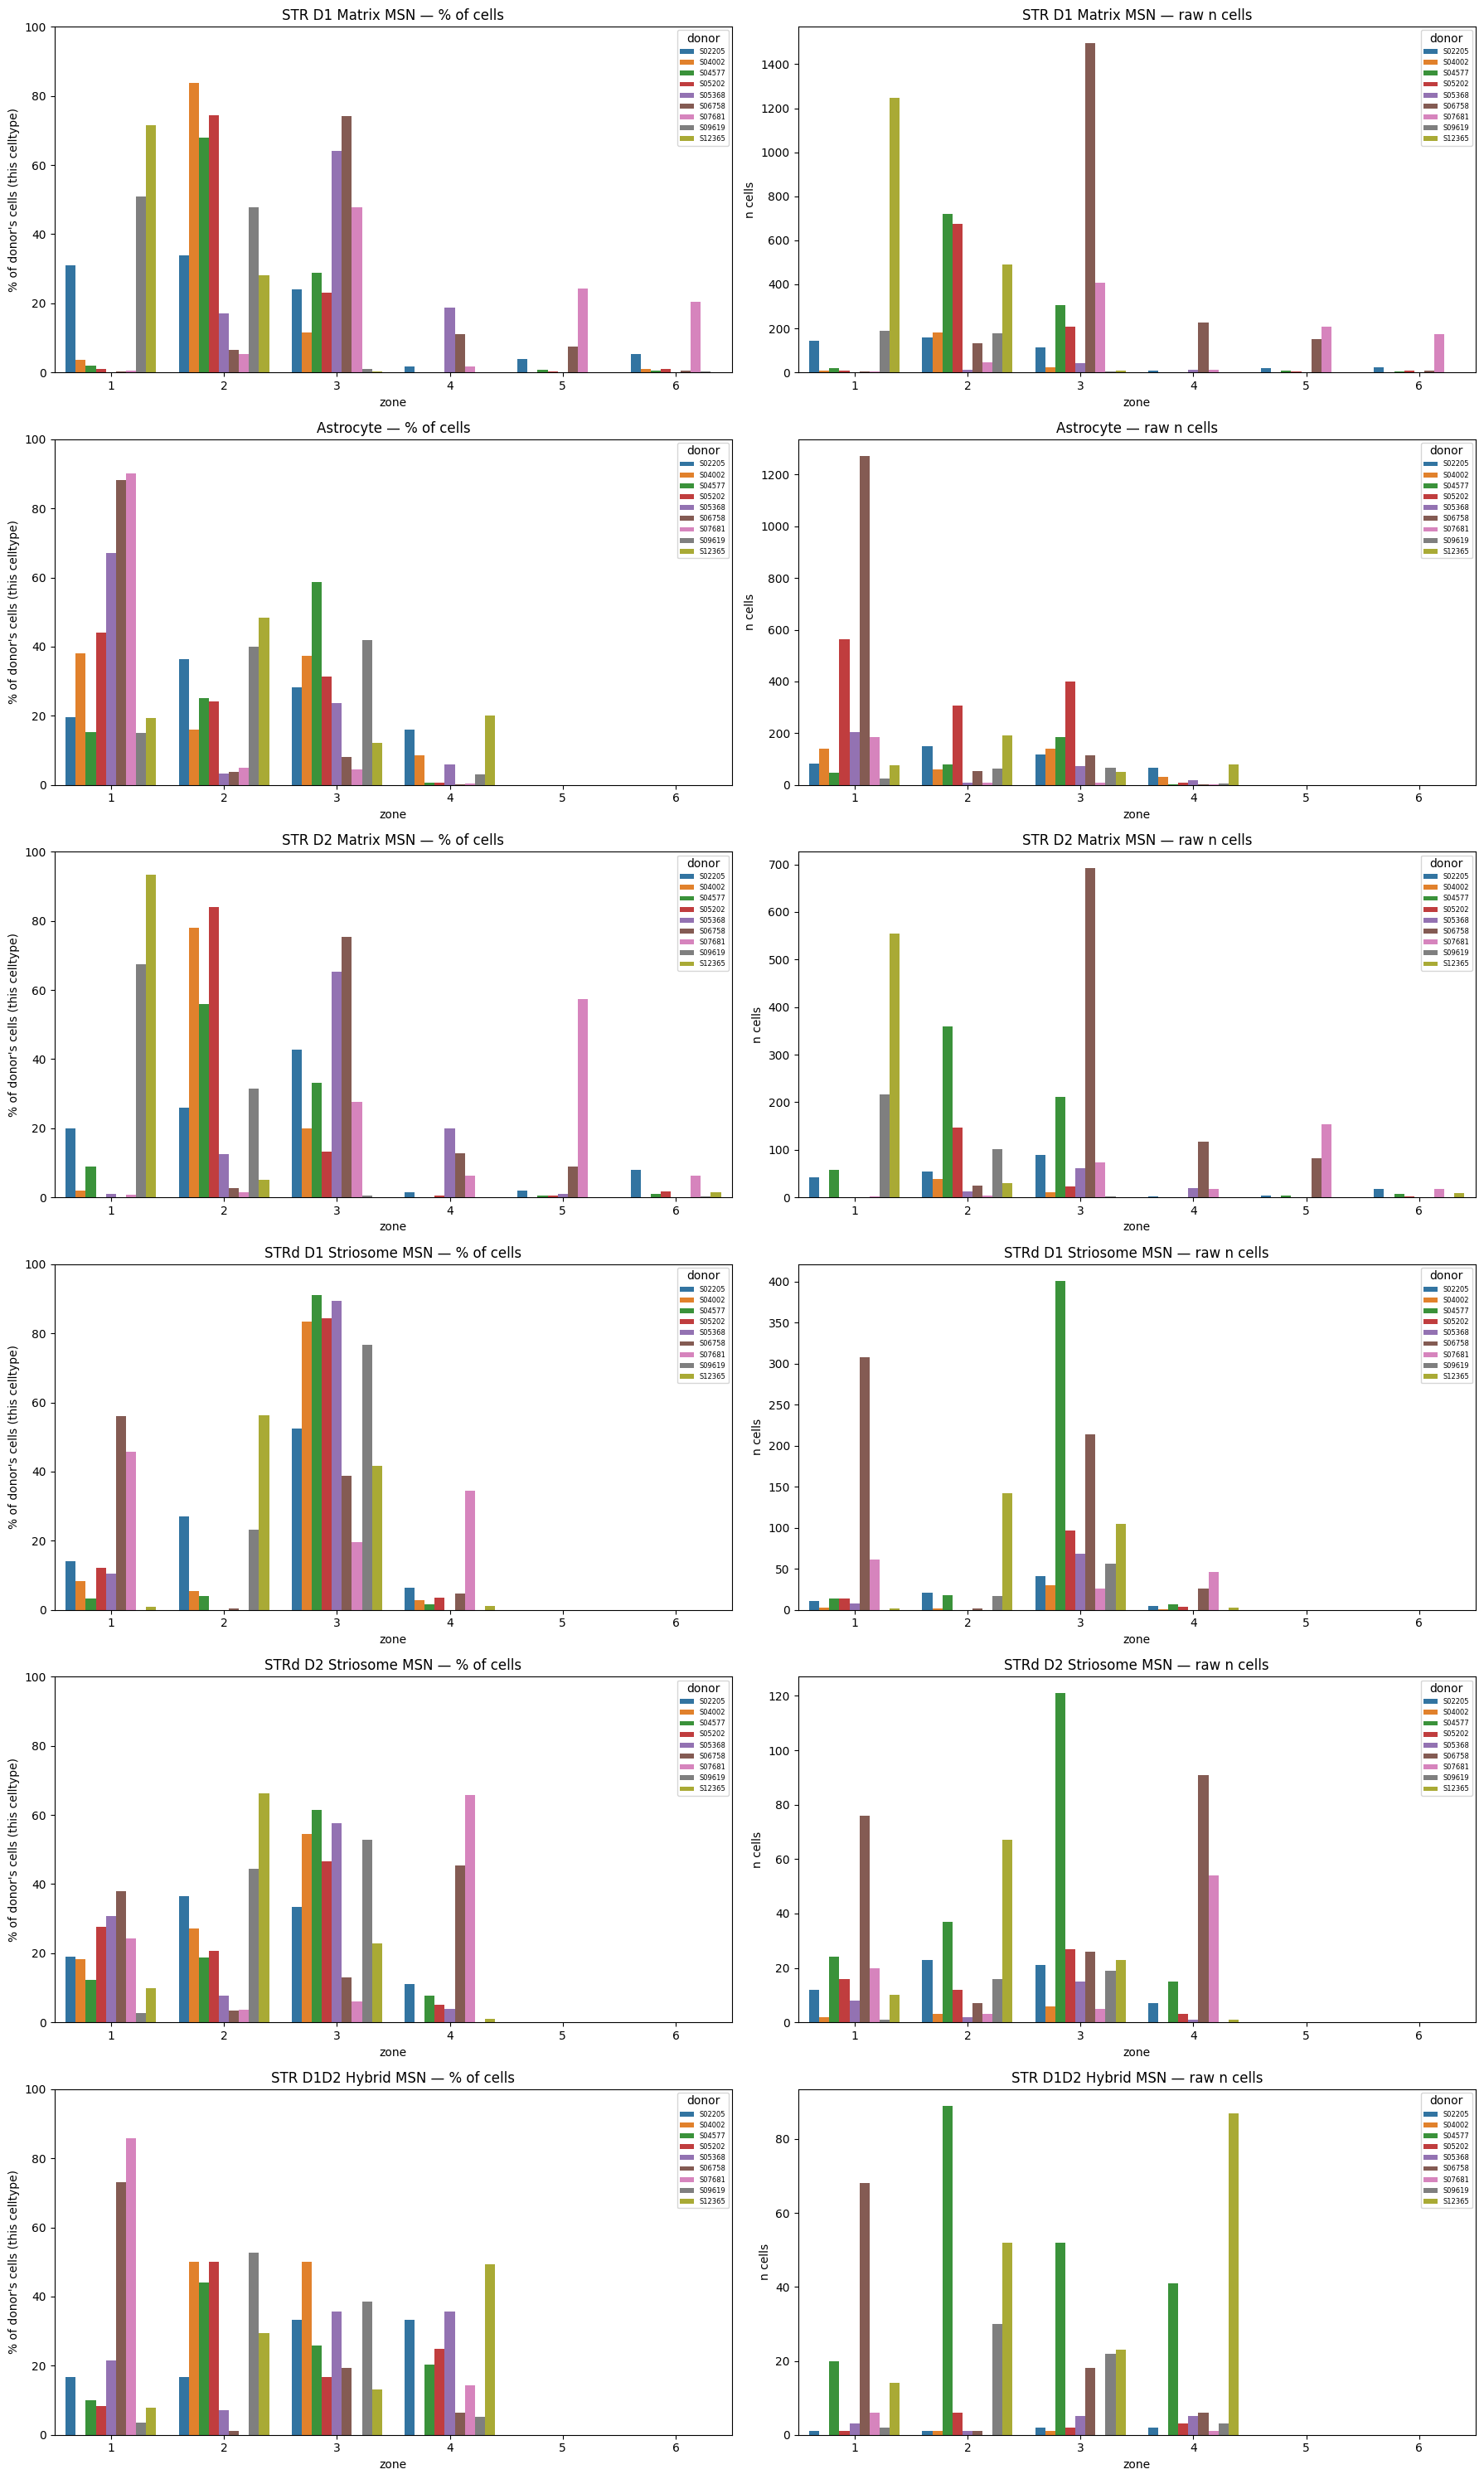

In [12]:
counts = (
    adata.obs
    .groupby(["mapping_coupling_for_zoning_mixed", "DONOR", "zone_mixed"])
    .size()
    .reset_index(name="n_cells")
)

counts["pct_cells"] = (
    counts.groupby(["mapping_coupling_for_zoning_mixed", "DONOR"])["n_cells"]
    .transform(lambda x: 100 * x / x.sum())
)   # normalize within each (celltype, donor): zones sum to 100% per donor

all_zones = sorted(adata.obs["zone_mixed"].unique())
n_ct = len(ct_to_check)

fig, axes = plt.subplots(n_ct, 2, figsize=(18, 5 * n_ct), squeeze=False)   # col 0 = %, col 1 = raw n_cells

for i, ct in enumerate(ct_to_check):
    sub = counts[counts["mapping_coupling_for_zoning_mixed"] == ct]

    ax = axes[i, 0]
    sns.barplot(data=sub, x="zone_mixed", y="pct_cells", hue="DONOR", order=all_zones, ax=ax)
    ax.set_title(f"{ct} — % of cells")
    ax.set_ylim(0, 100)
    ax.set_xlabel("zone")
    ax.set_ylabel("% of donor's cells (this celltype)")
    ax.legend(fontsize=6, title="donor")

    ax = axes[i, 1]
    sns.barplot(data=sub, x="zone_mixed", y="n_cells", hue="DONOR", order=all_zones, ax=ax)
    ax.set_title(f"{ct} — raw n cells")
    ax.set_xlabel("zone")
    ax.set_ylabel("n cells")
    ax.legend(fontsize=6, title="donor")

plt.tight_layout()
plt.show()


In [14]:
df = pd.DataFrame(index = adata.obs["DONOR"].unique())
df

""
S02205
S04002
S04577
S05202
S05368
S06758
S07681
S09619
S12365


In [26]:
def find_bimodal_means(x, min_samples=20, outlier_pct=99, fit_max=None):
    x = np.asarray(x).flatten()
    if fit_max is not None:
        x_fit = x[x <= fit_max]                 # manual override: fit only below this value
    else:
        cutoff = np.percentile(x, outlier_pct)
        x_fit = x[x <= cutoff]                  # default: automatic percentile-based trim
    if len(x_fit) < min_samples or np.unique(x_fit).size < 2:
        return None, None, None
    gmm = GaussianMixture(n_components=2, random_state=0).fit(x_fit.reshape(-1, 1))
    order = np.argsort(gmm.means_.flatten())
    means = gmm.means_.flatten()[order]
    stds = np.sqrt(gmm.covariances_.flatten())[order]
    weights = gmm.weights_[order]
    return means, stds, weights


In [2]:
METHOD = "bigaussian"   # choose one of: "median", "mean", "bigaussian", "instability_index"


S02205


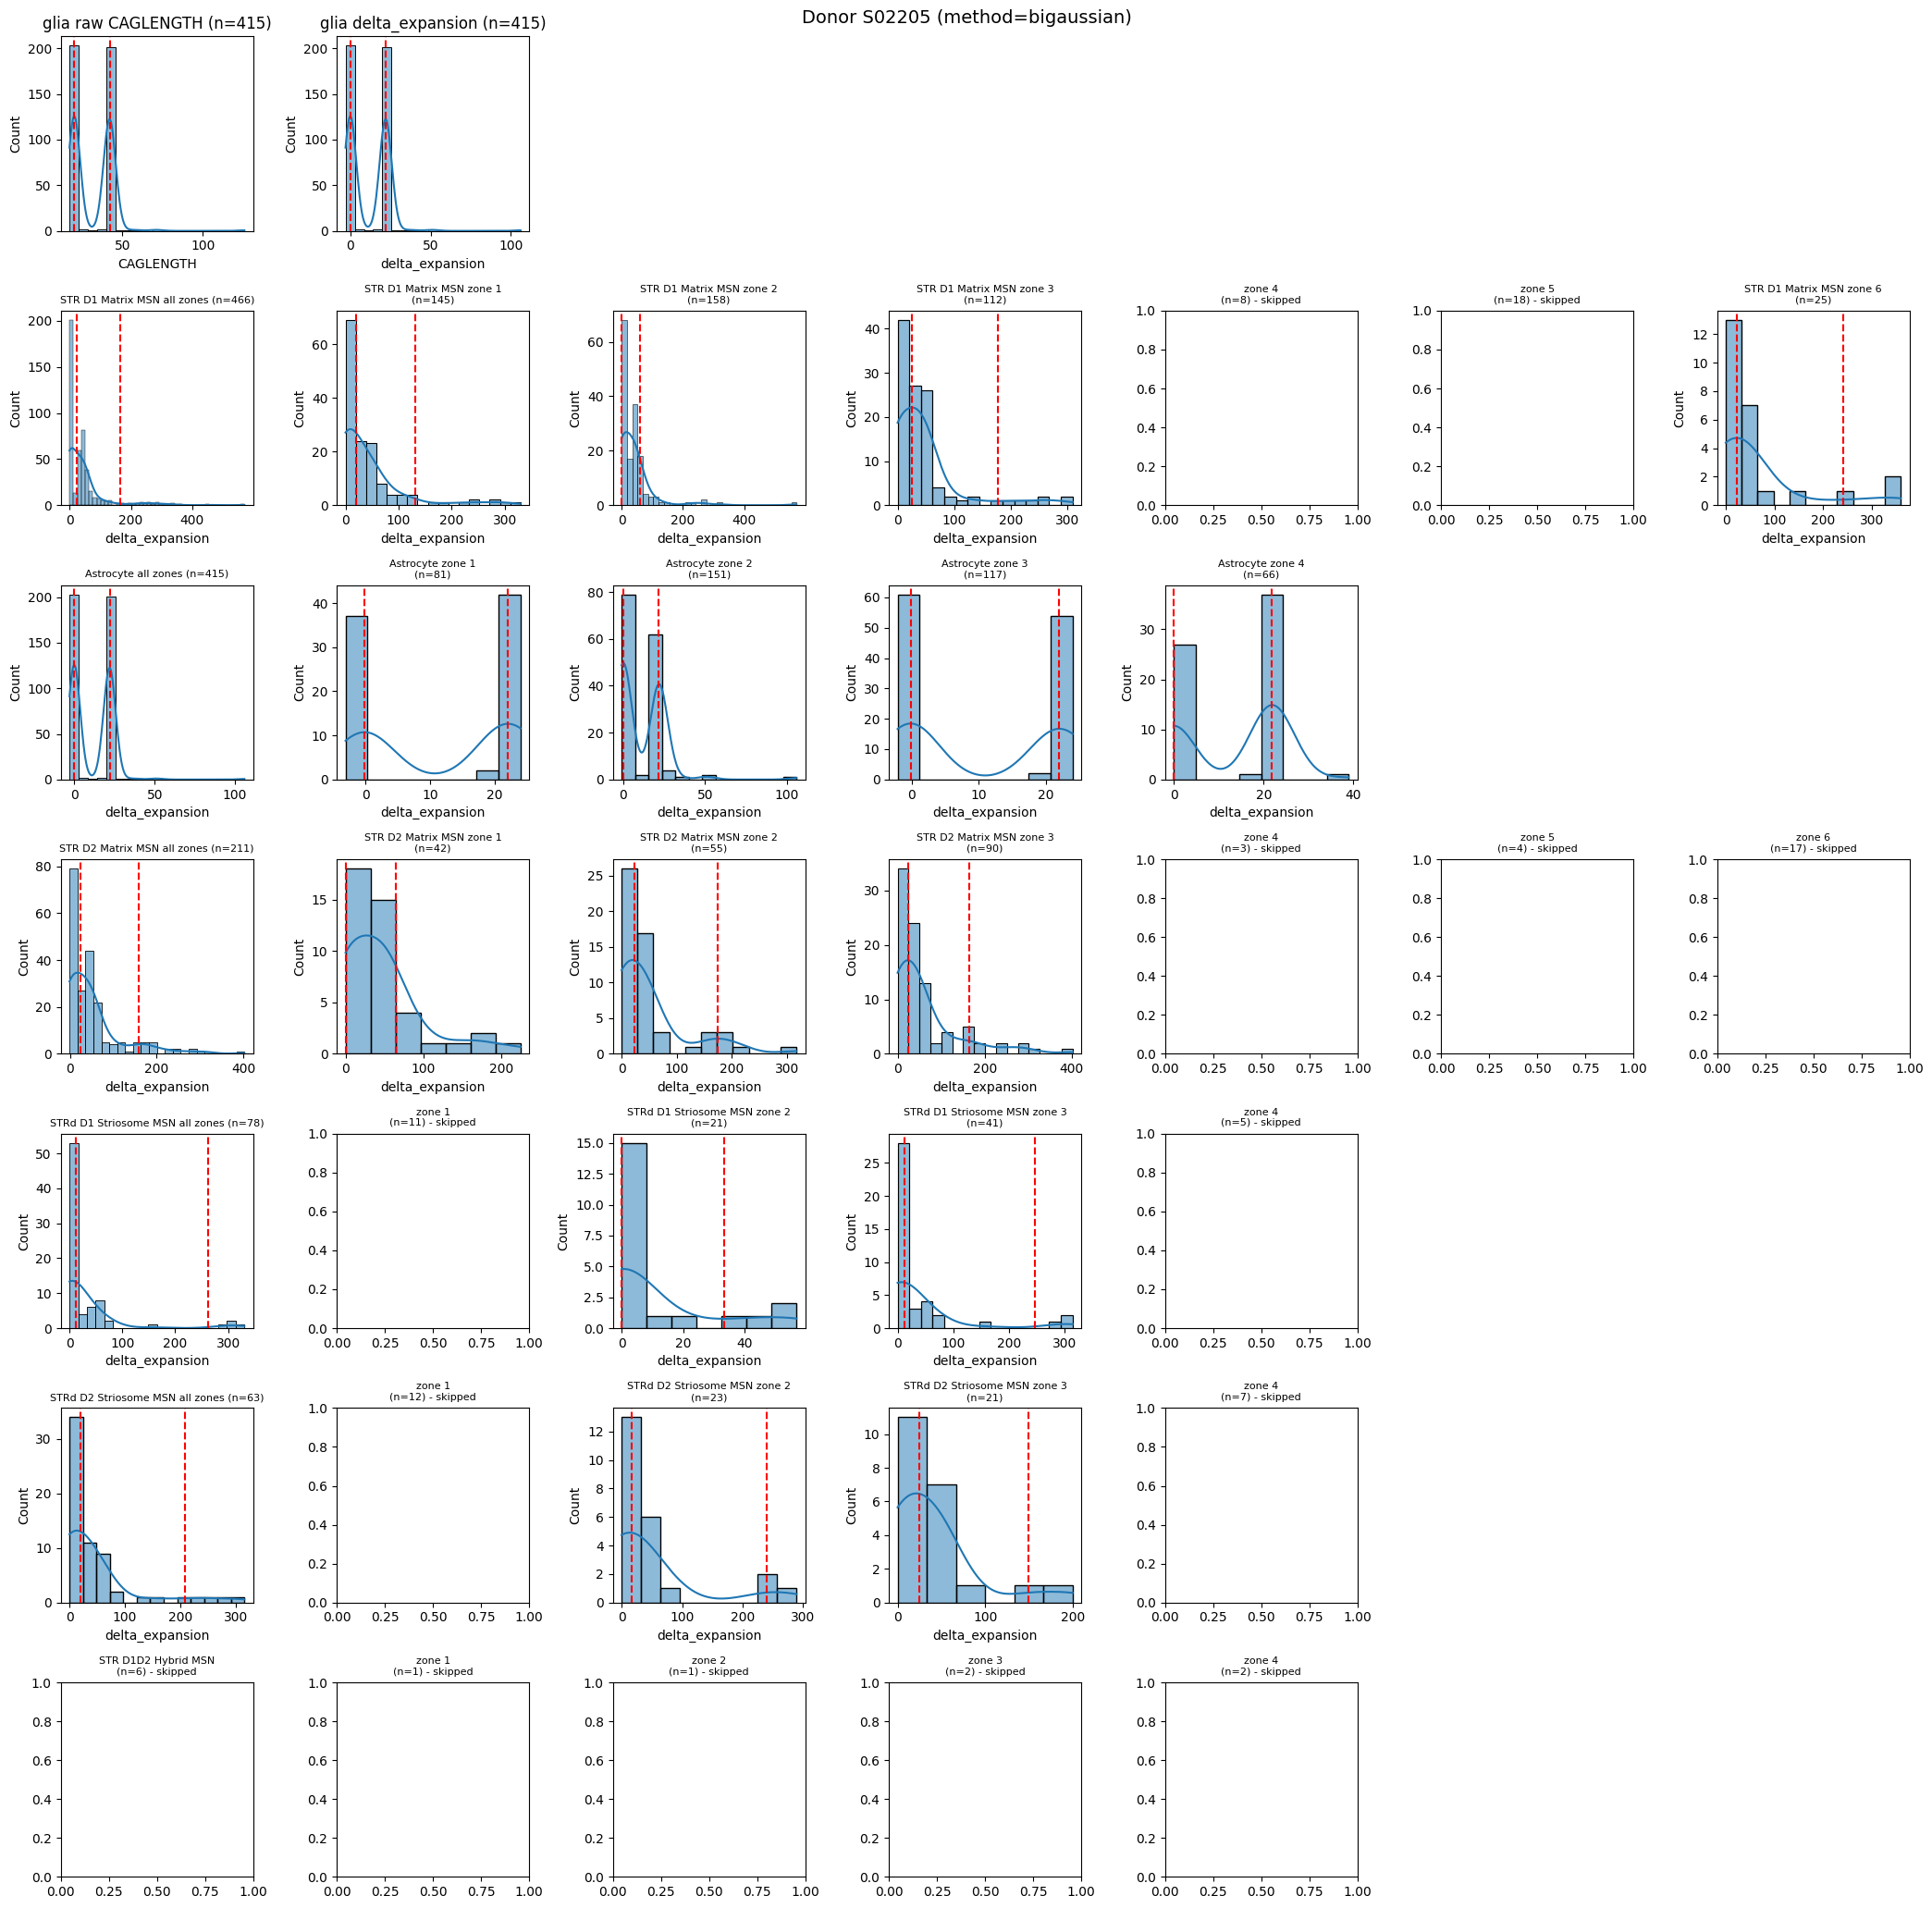

S04002


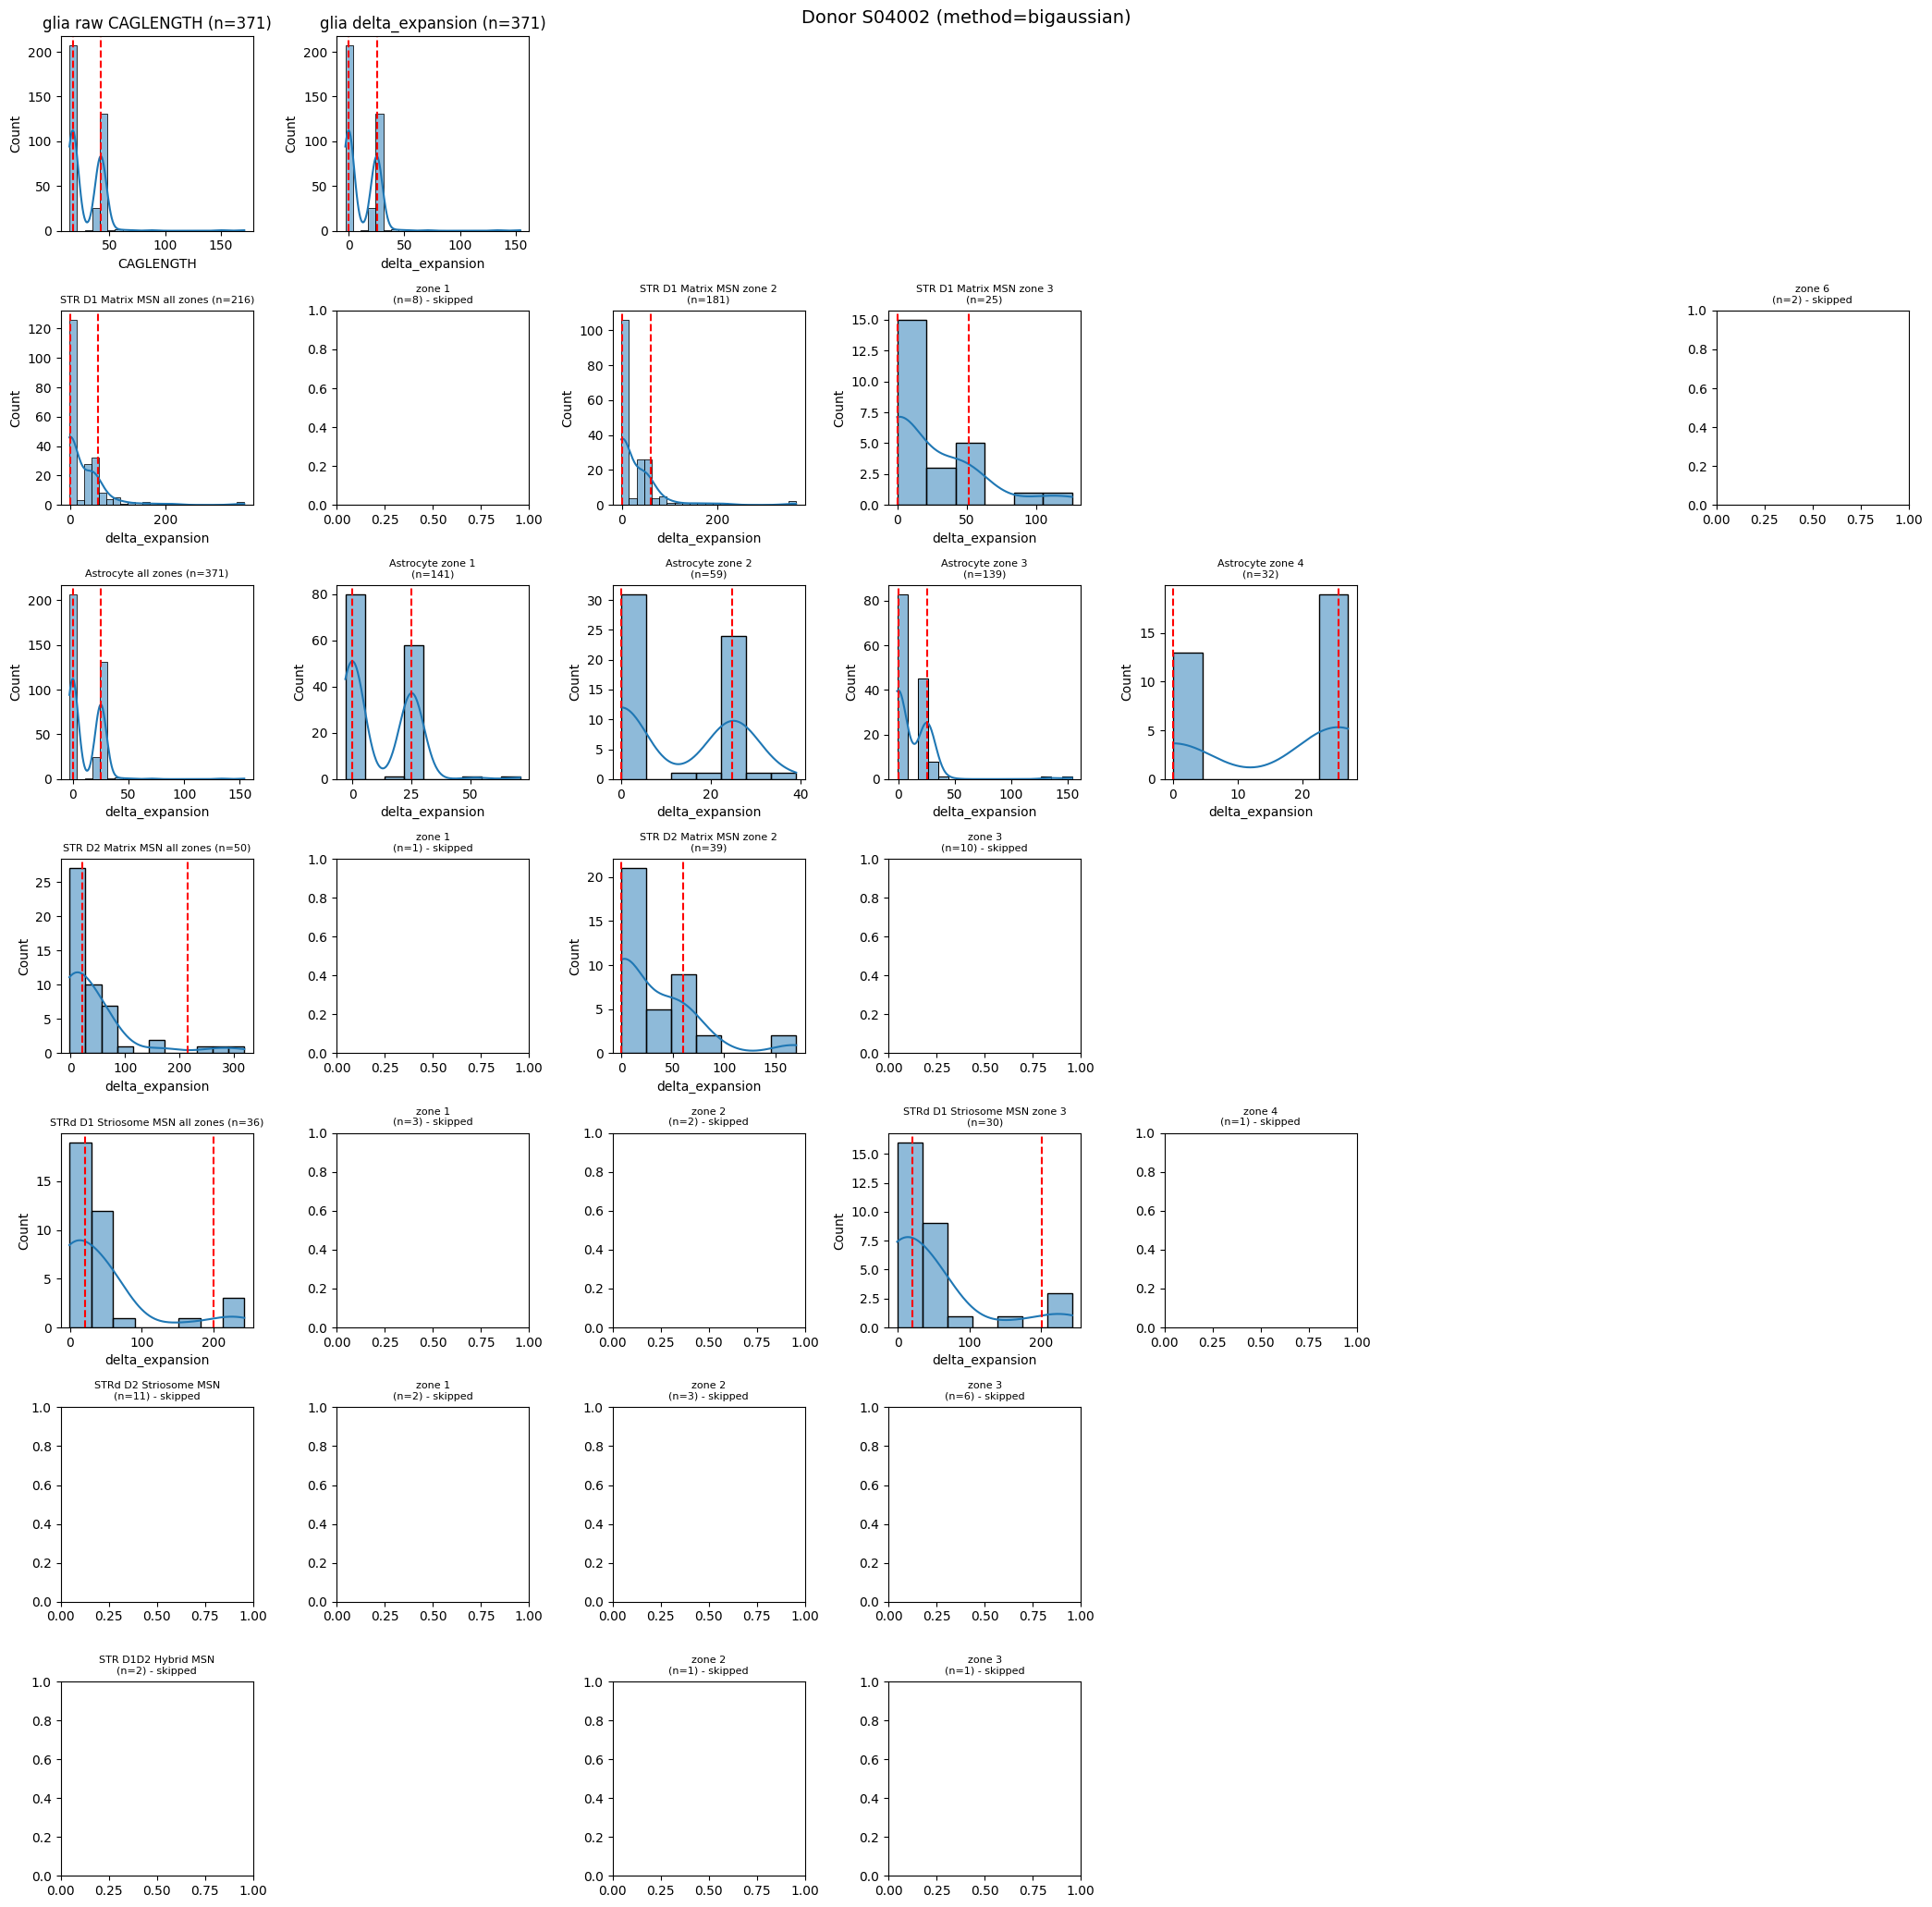

S04577


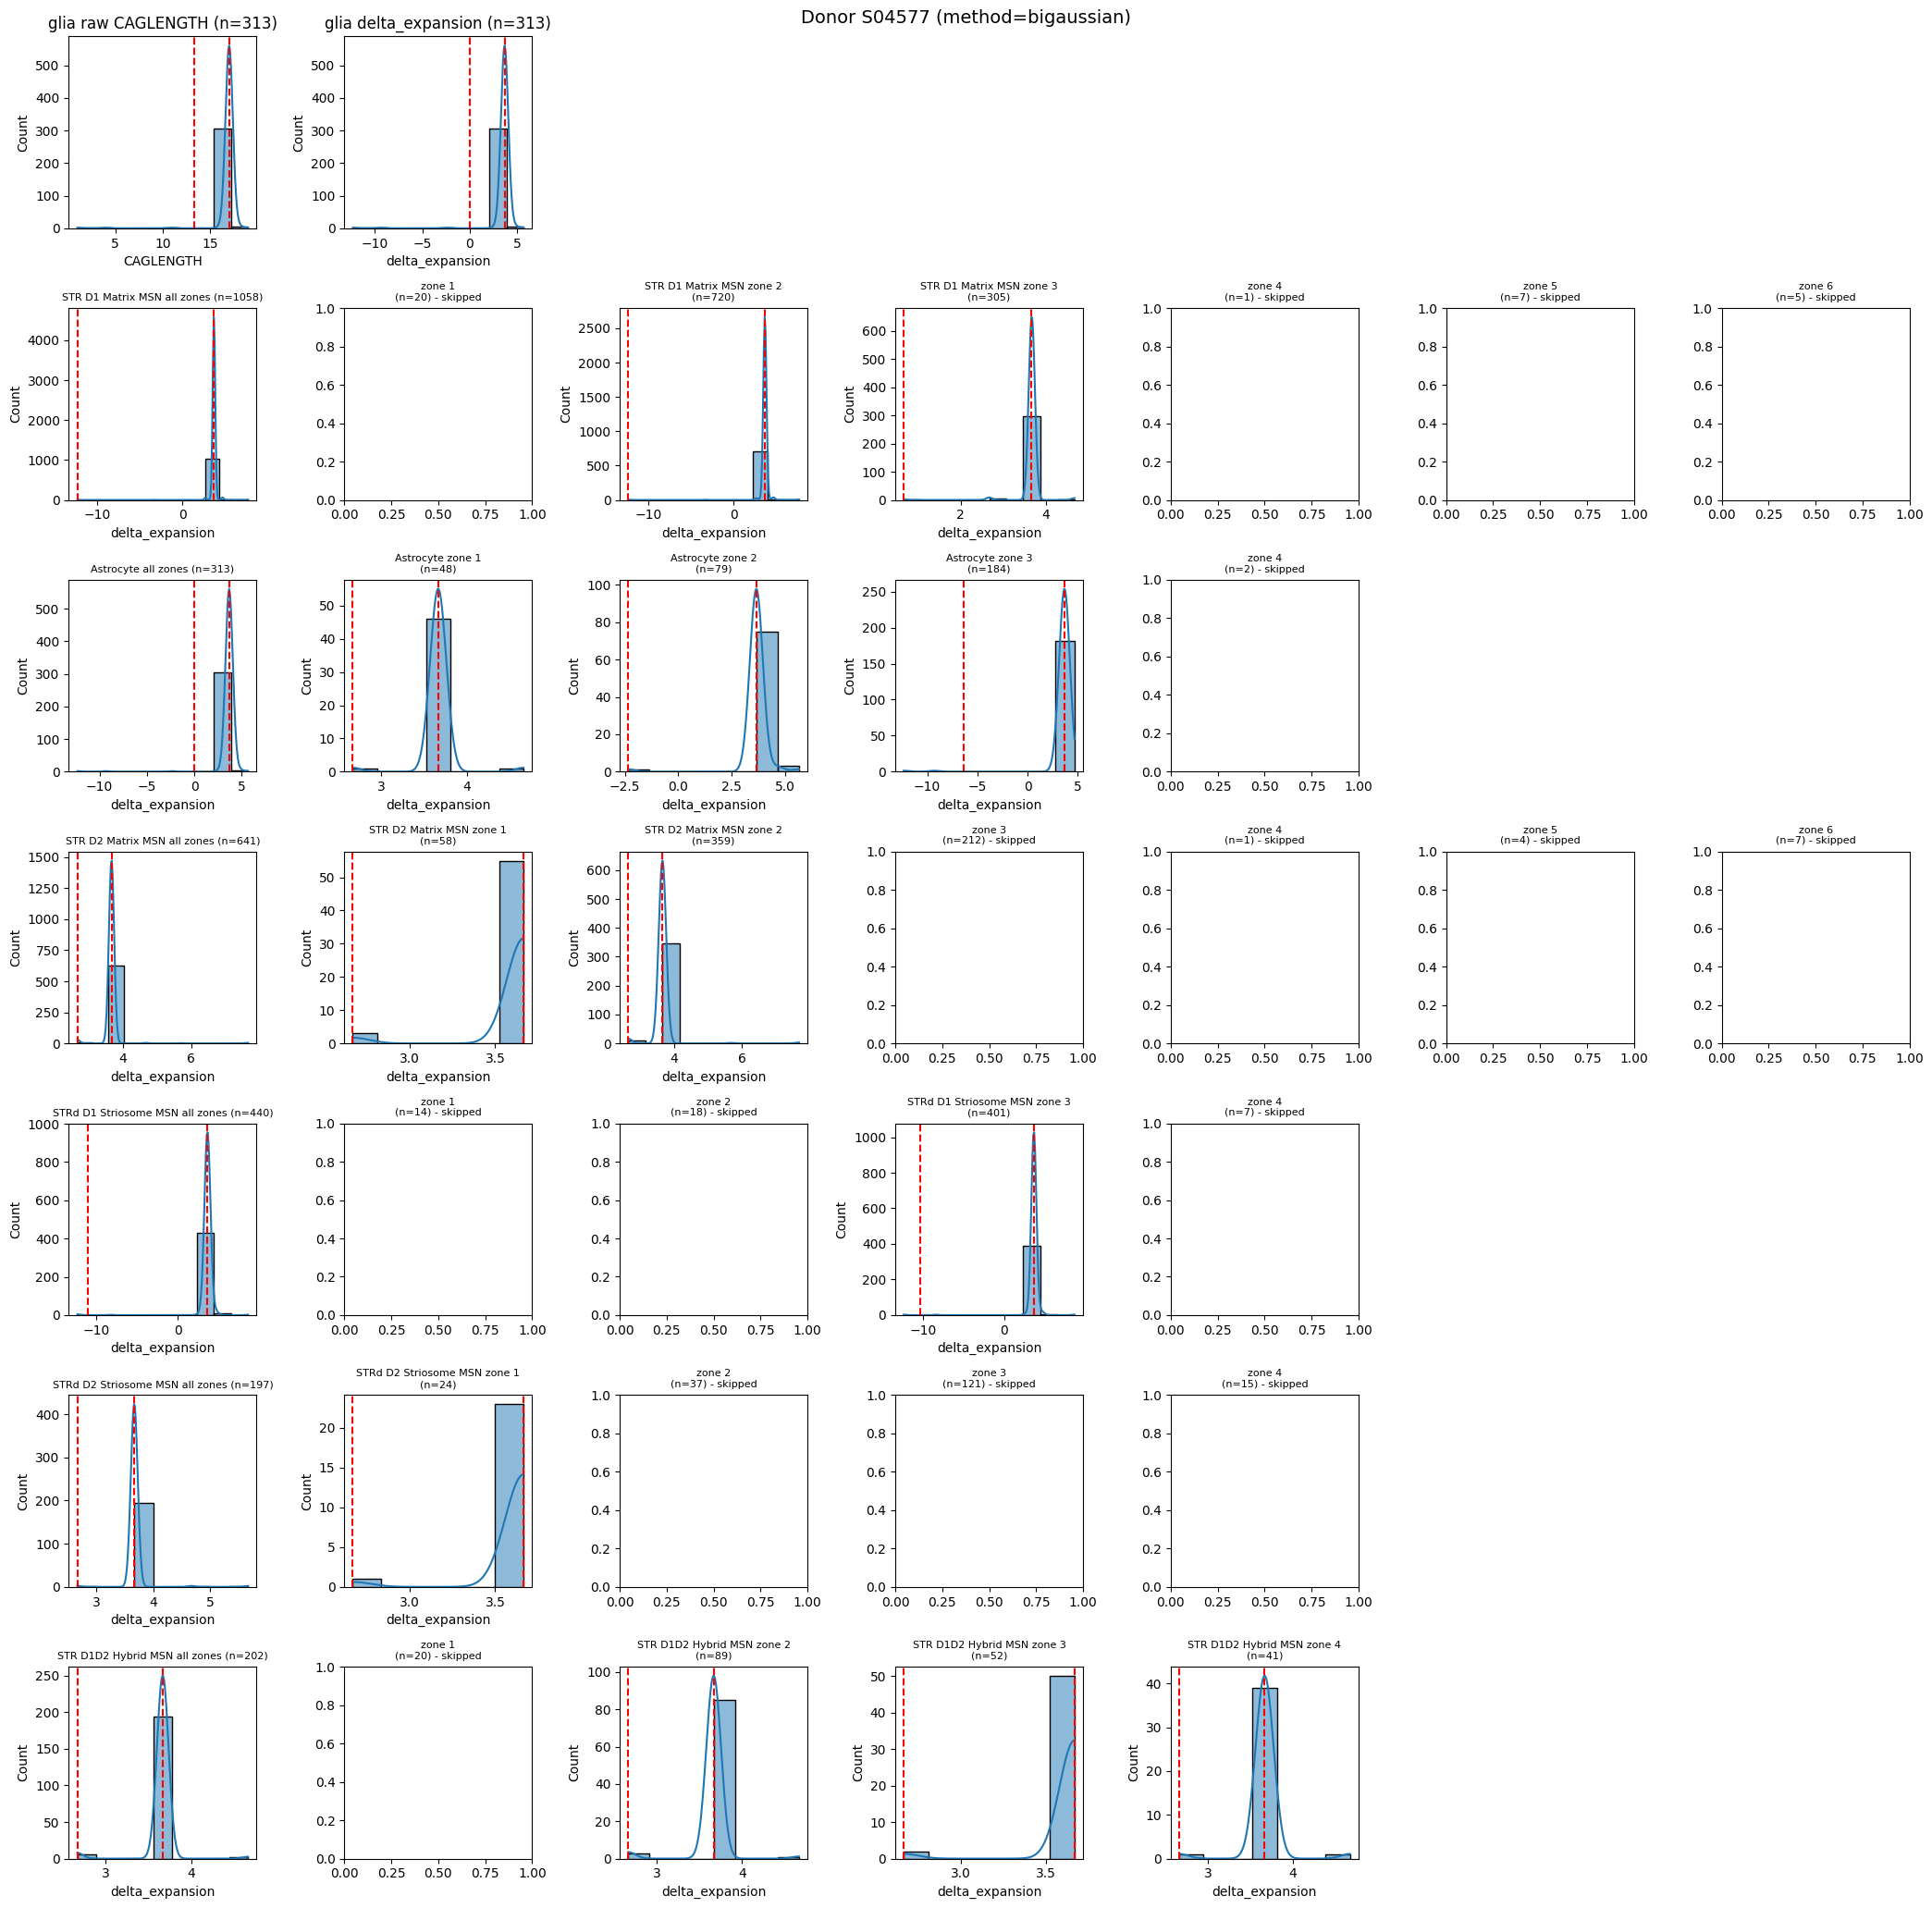

S05202


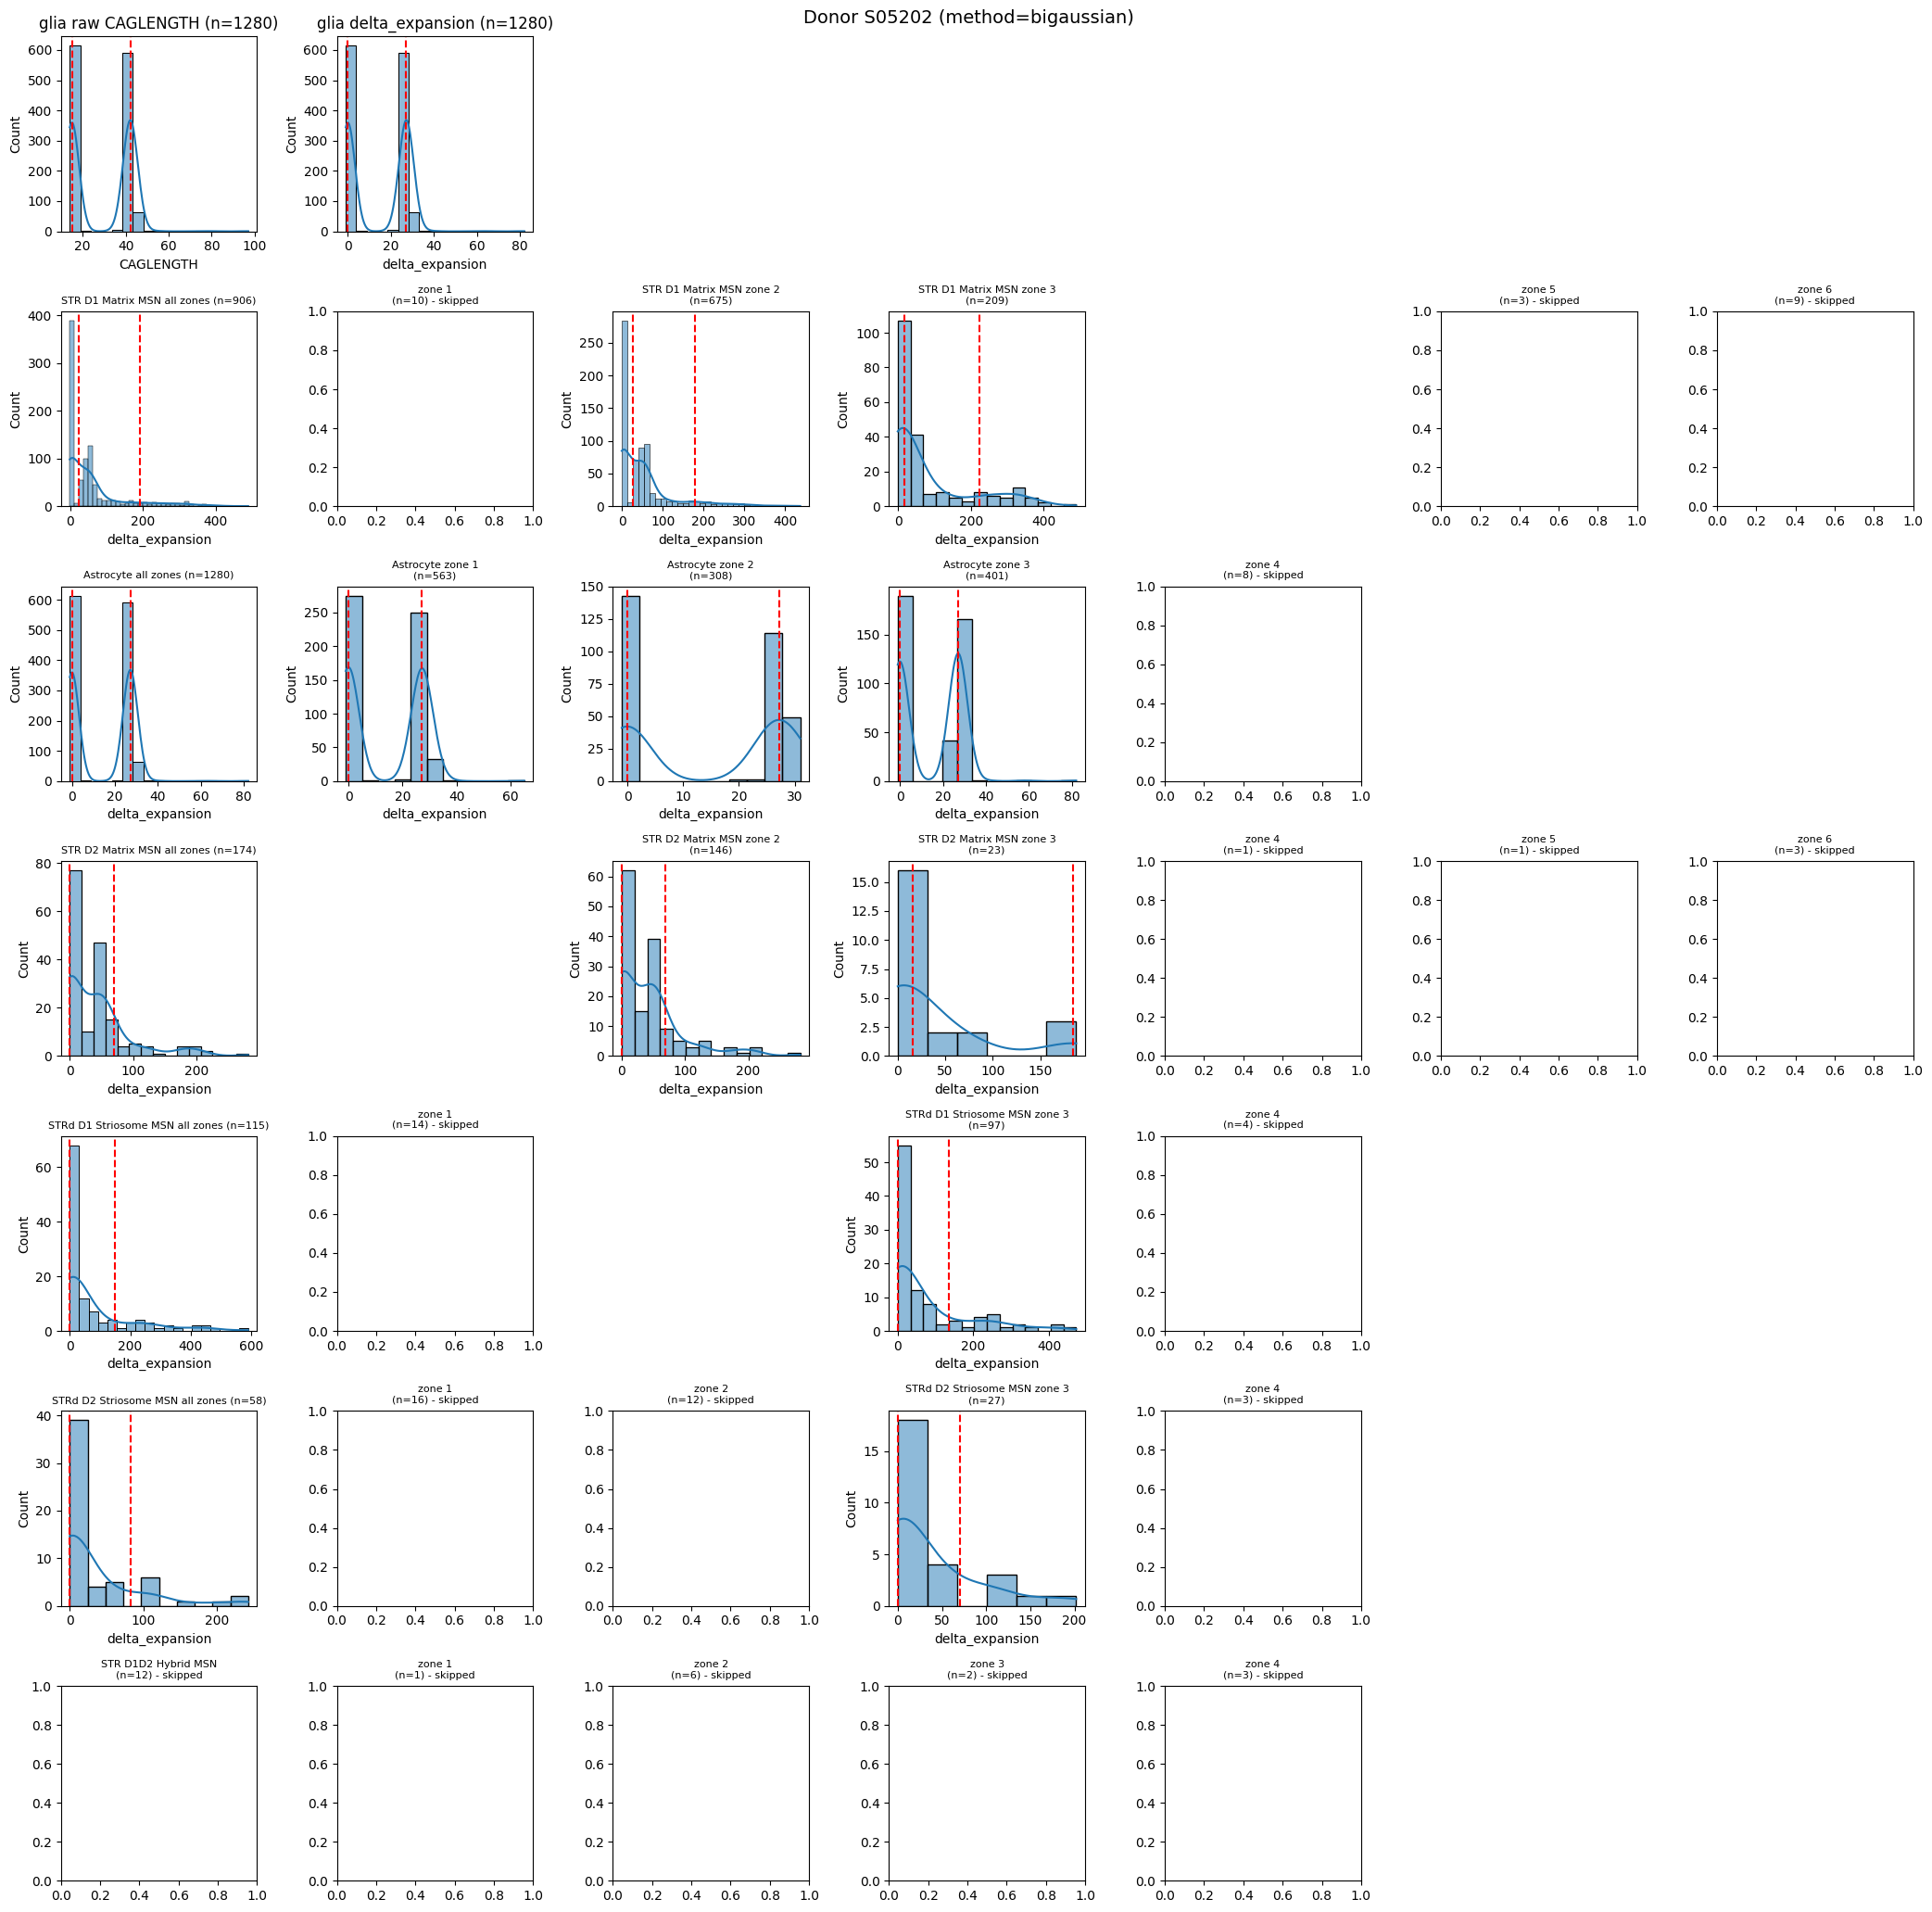

S05368


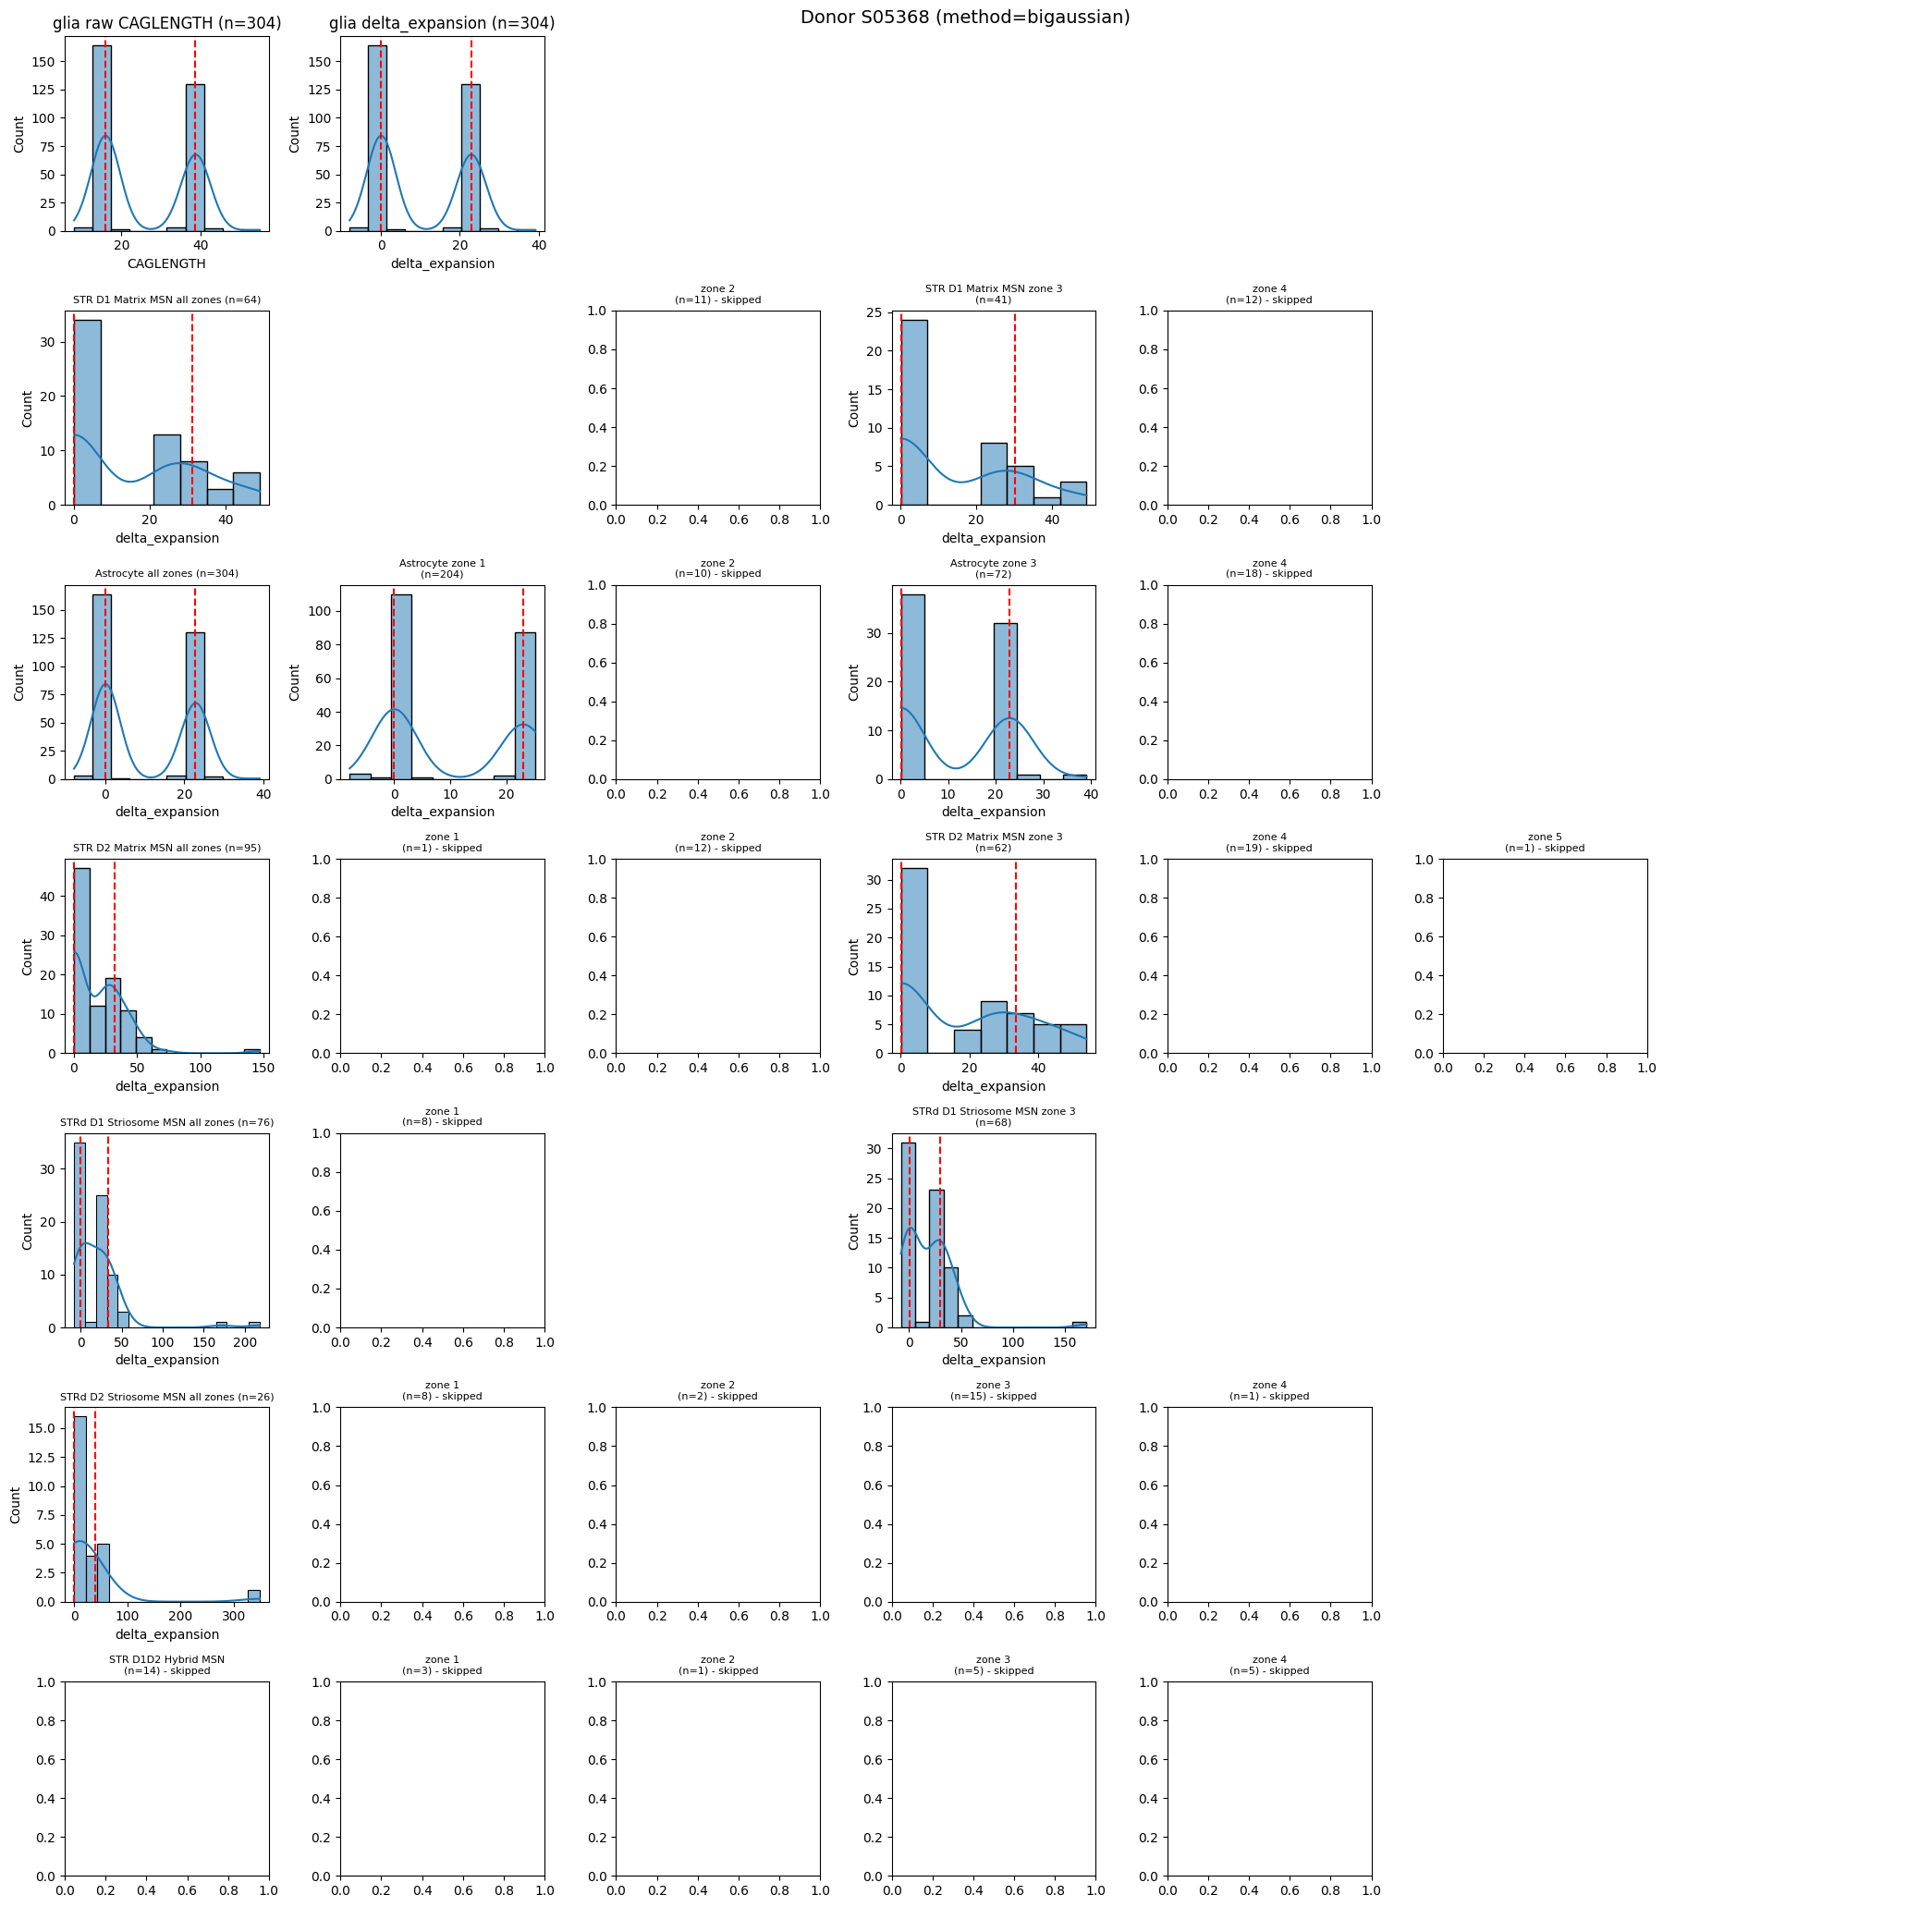

S06758


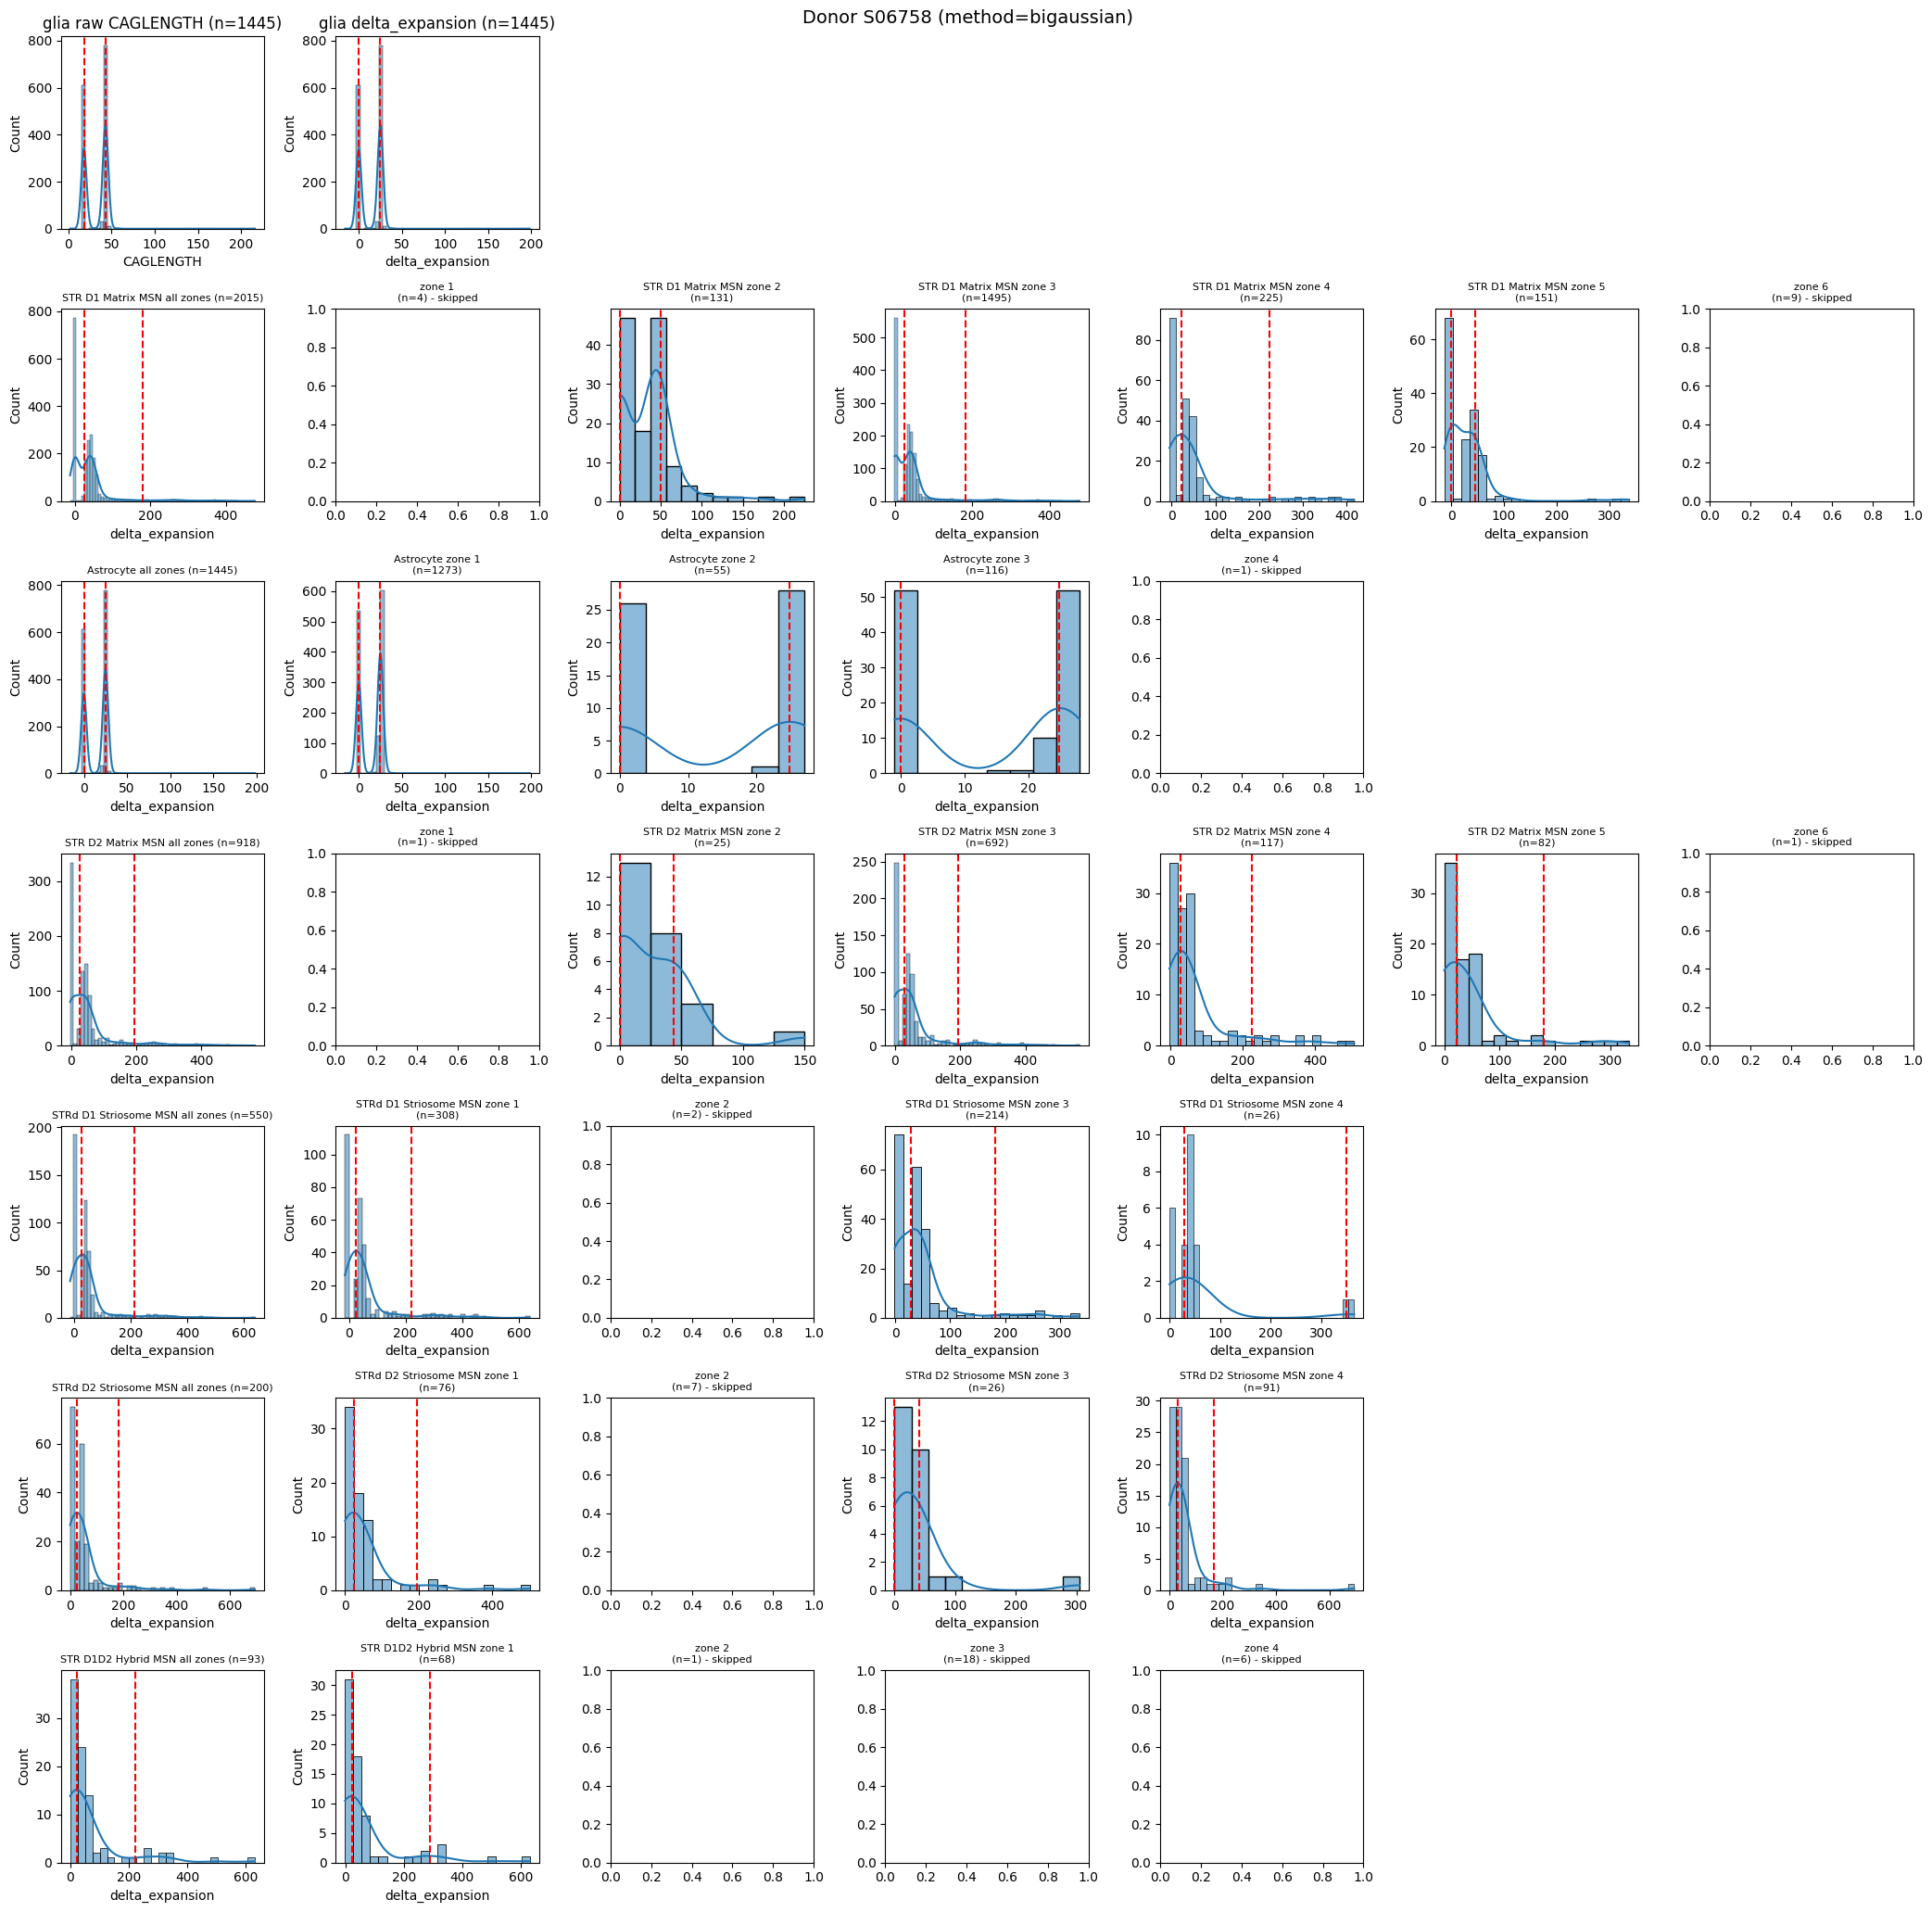

S07681


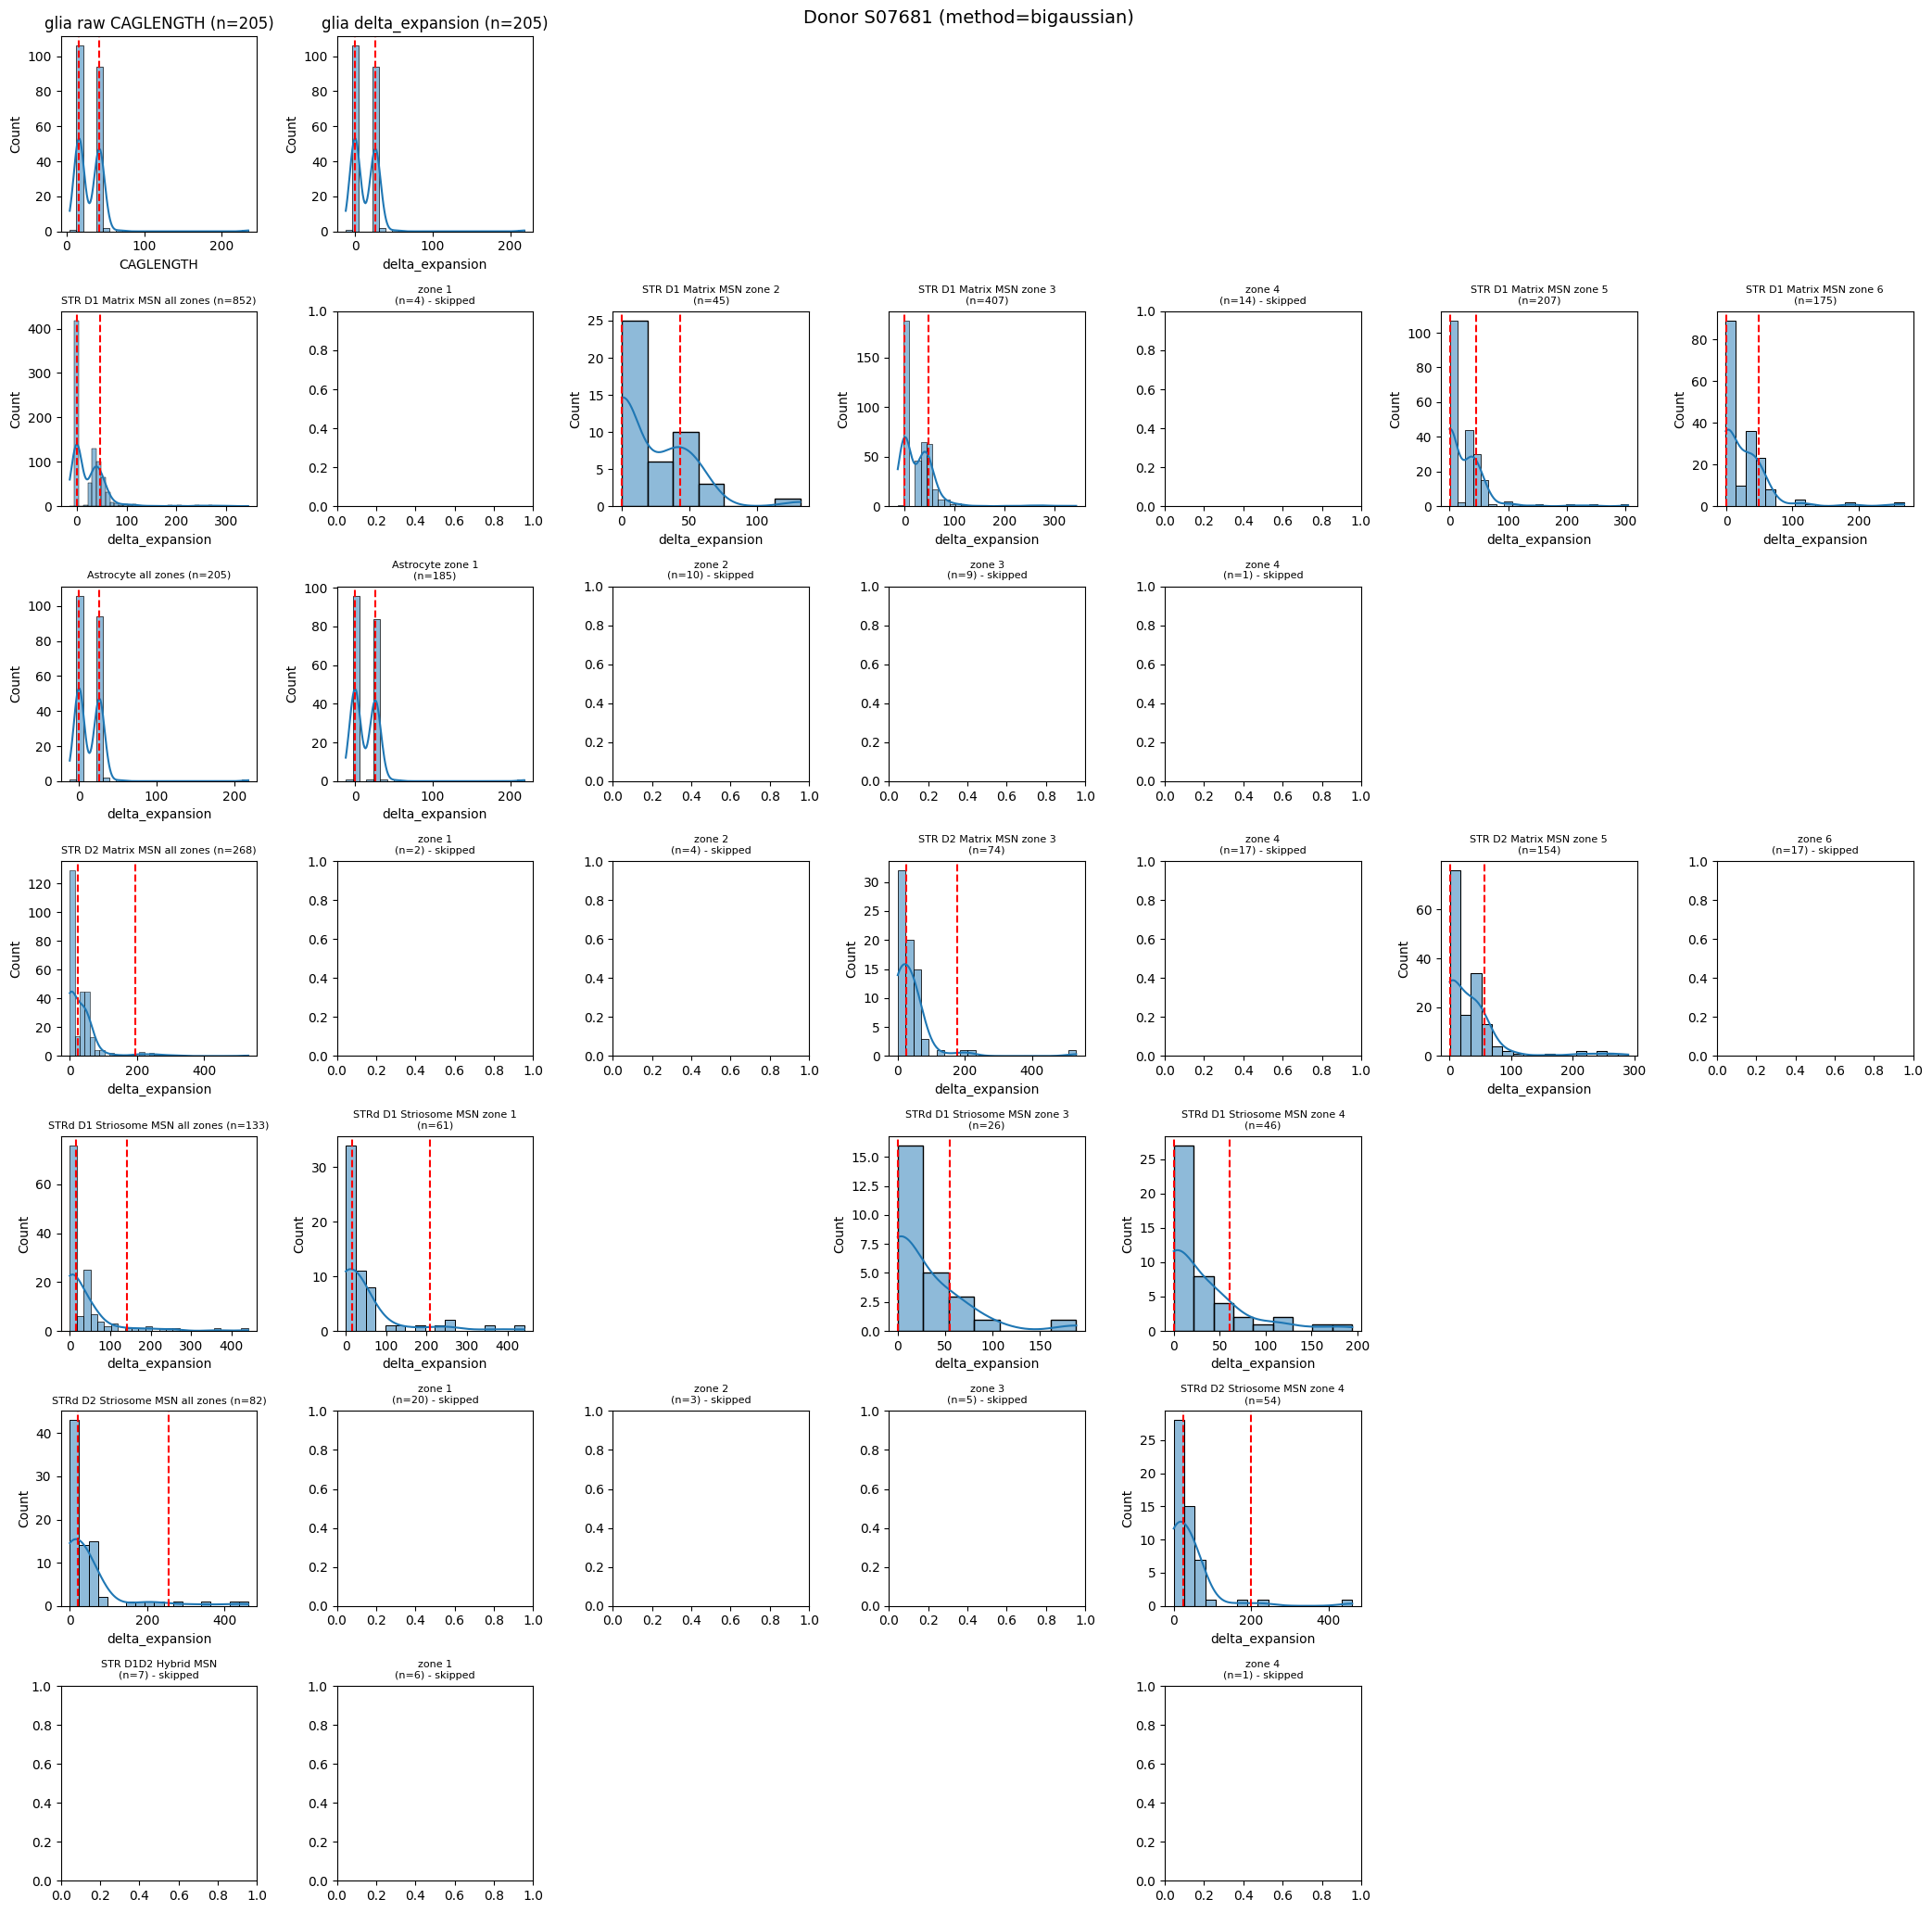

S09619


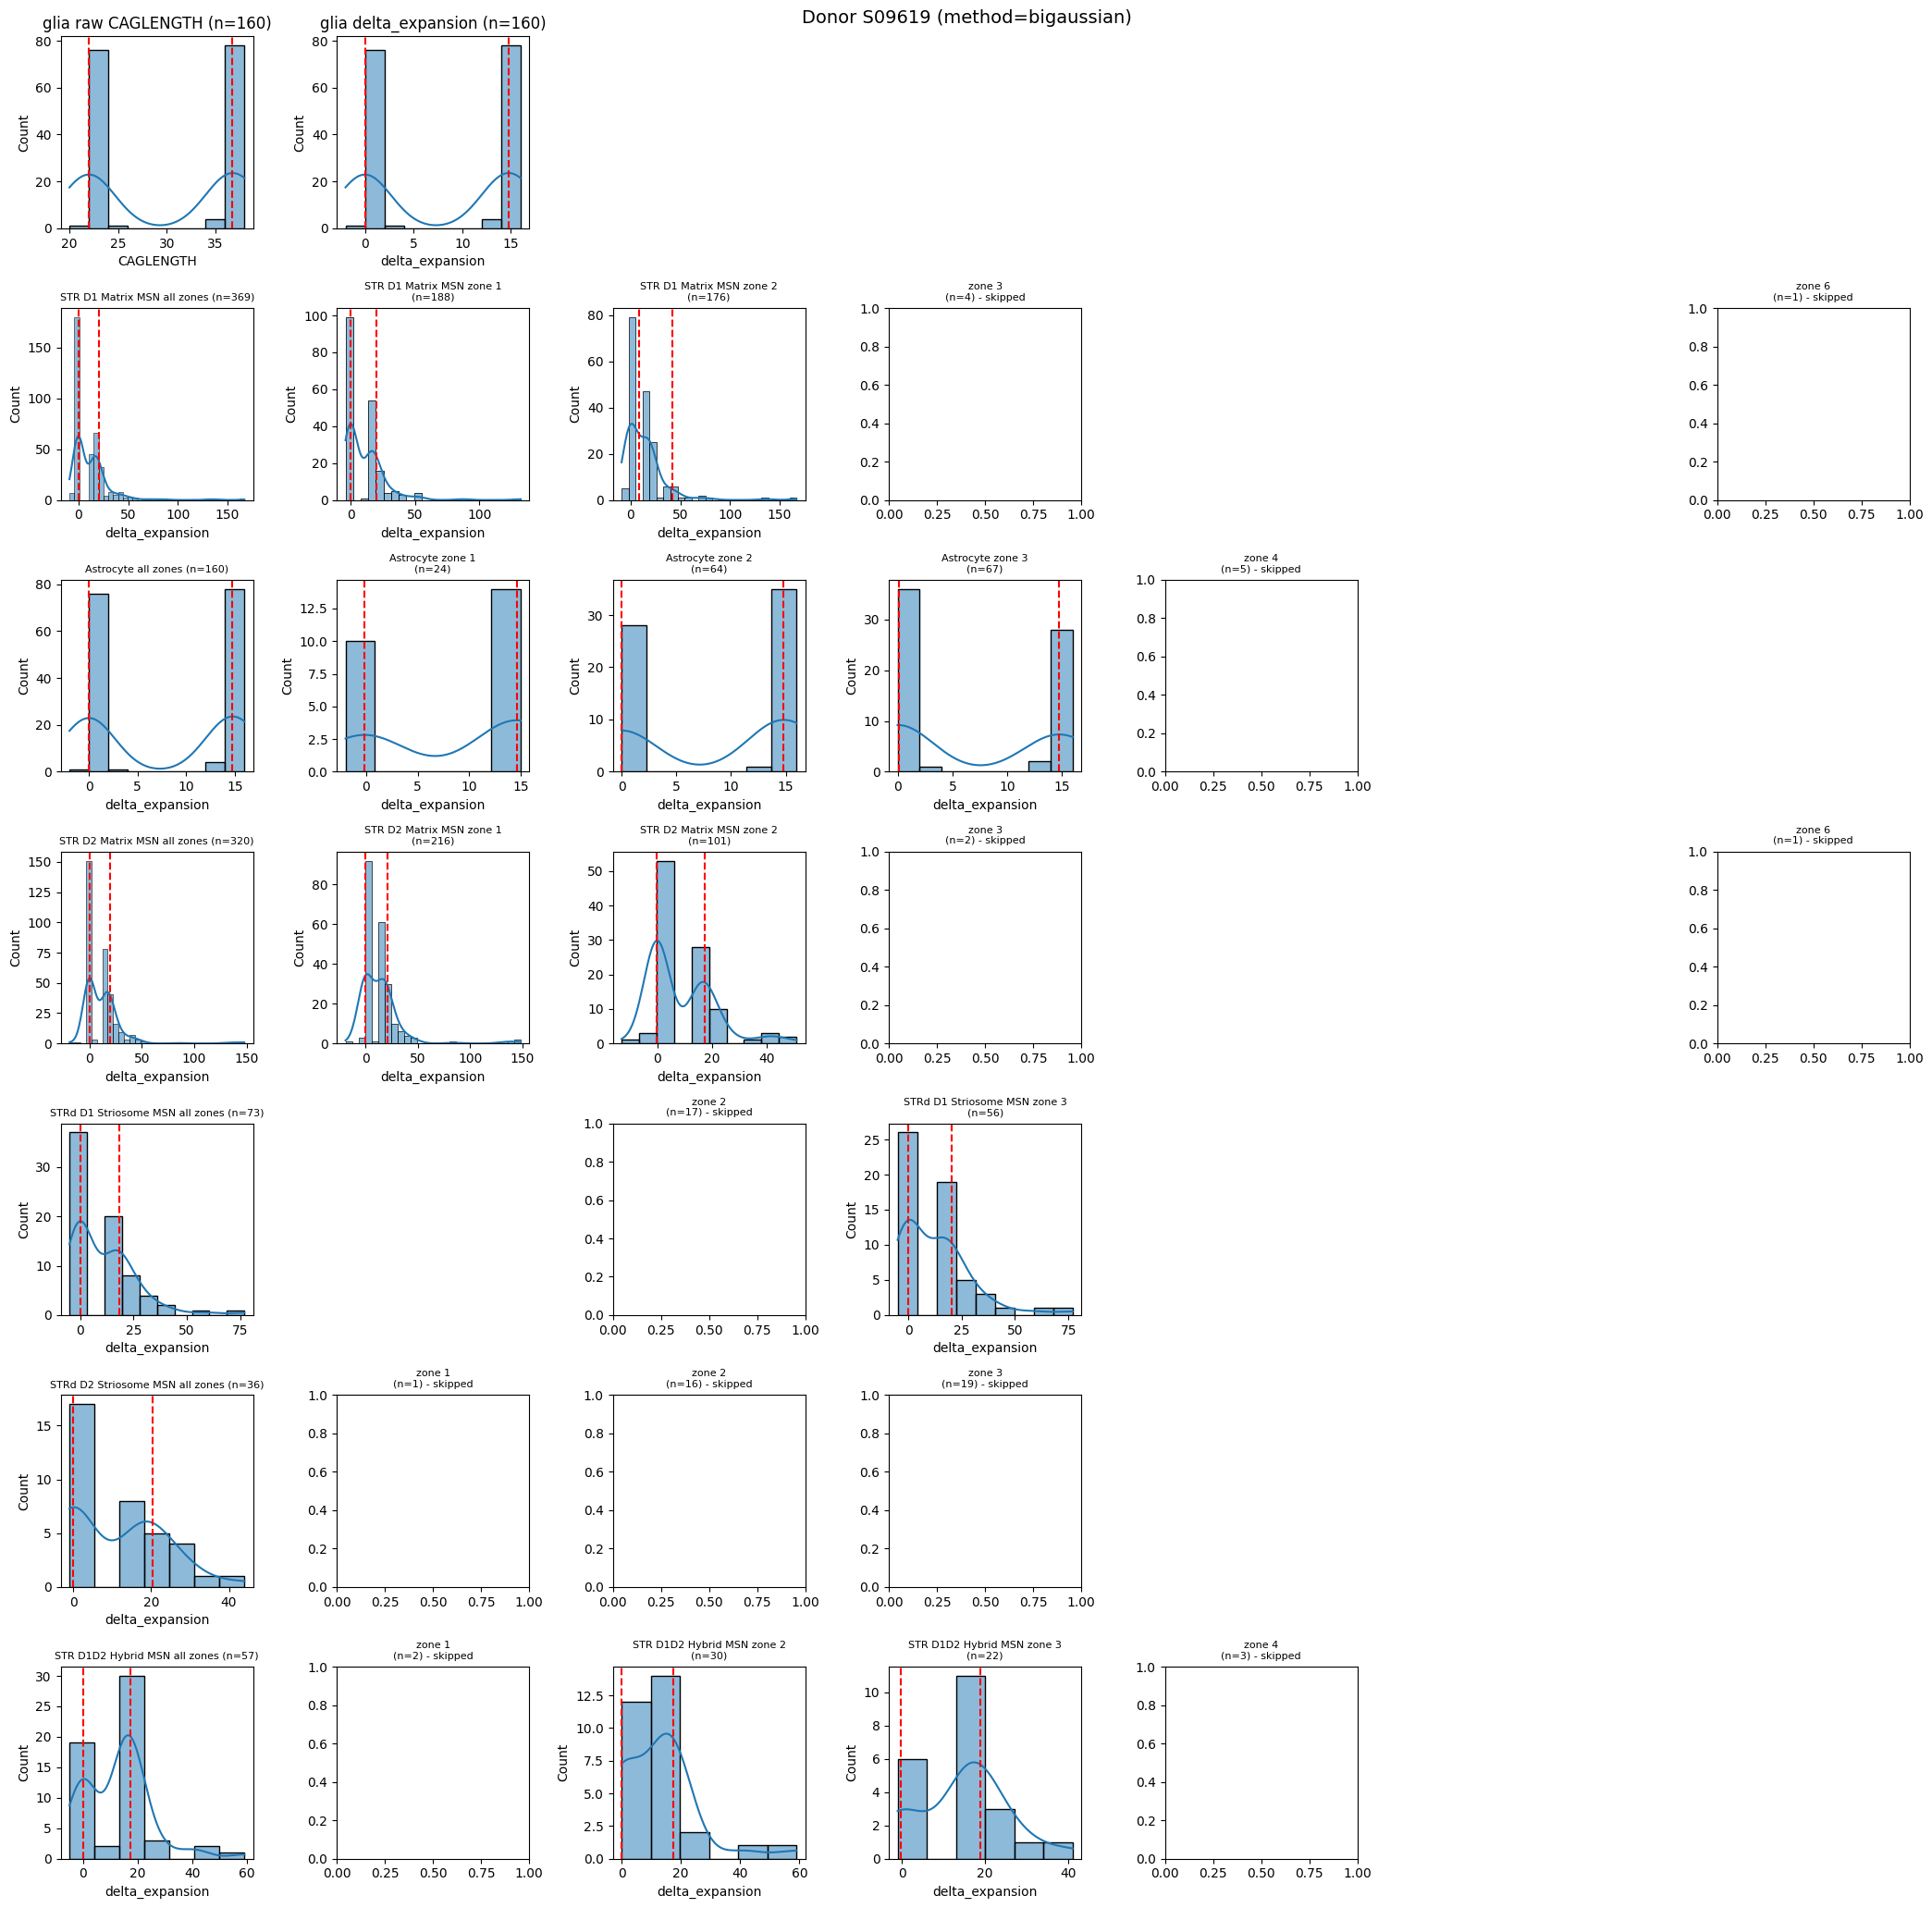

S12365


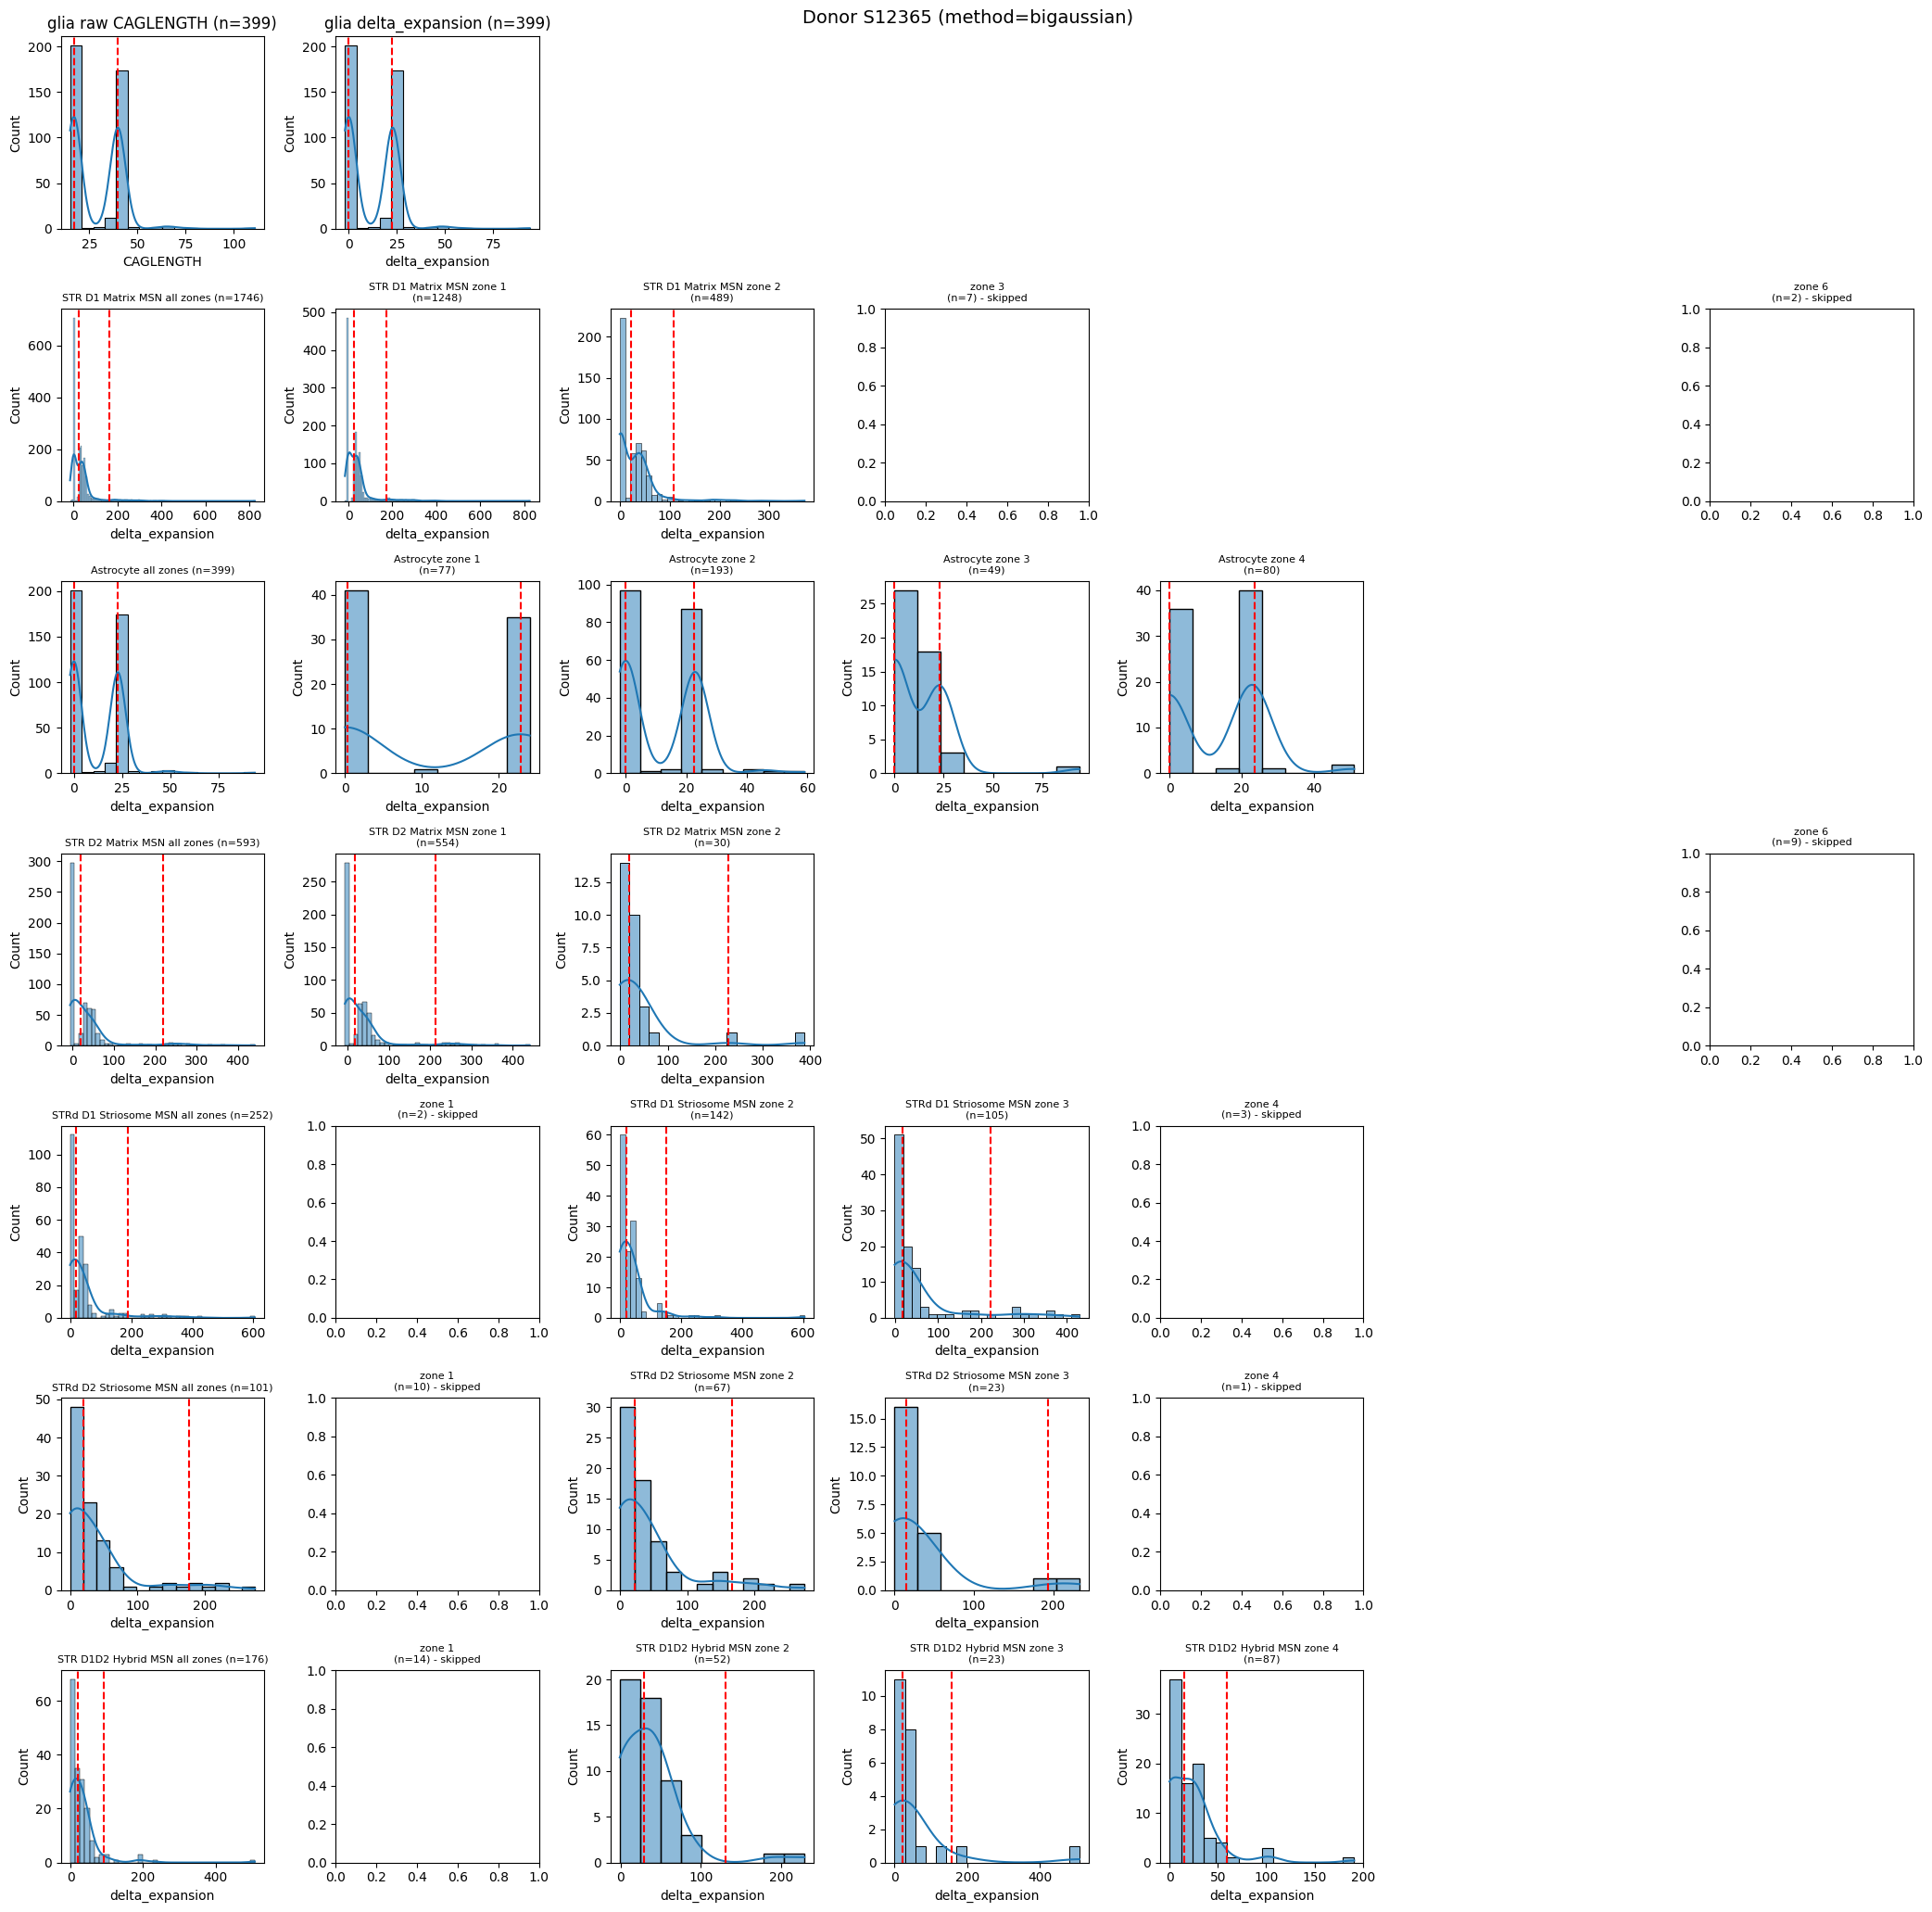

,WT_mean_RL,STR D1 Matrix MSN_bigaussian_delta_expansion,STR D1 Matrix MSN_1_bigaussian_delta_expansion,STR D1 Matrix MSN_2_bigaussian_delta_expansion,STR D1 Matrix MSN_3_bigaussian_delta_expansion,STR D1 Matrix MSN_5_bigaussian_delta_expansion,STR D1 Matrix MSN_6_bigaussian_delta_expansion,Astrocyte_bigaussian_delta_expansion,Astrocyte_1_bigaussian_delta_expansion,Astrocyte_2_bigaussian_delta_expansion,...,STR D1D2 Hybrid MSN_1_mode_raw,STR D1D2 Hybrid MSN_1_mode_shrunk,STR D1D2 Hybrid MSN_3_mode_raw,STR D1D2 Hybrid MSN_3_mode_shrunk,STR D1D2 Hybrid MSN_2_mode_raw,STR D1D2 Hybrid MSN_2_mode_shrunk,STRd D1 Striosome MSN_2_mode_raw,STRd D1 Striosome MSN_2_mode_shrunk,STR D1D2 Hybrid MSN_4_mode_raw,STR D1D2 Hybrid MSN_4_mode_shrunk
S02205,20.072815,165.594622,132.268642,59.983437,177.264275,37.302185,240.797348,21.946792,21.995367,21.283343,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
S04002,16.975847,59.057871,51.524153,61.212879,51.579629,NaN,NaN,25.361640,25.075001,24.801931,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
S04577,13.333830,3.659529,NaN,3.660584,3.652881,NaN,NaN,3.666170,3.666170,3.692144,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
S05202,15.004878,192.938327,136.995122,179.799046,224.260825,NaN,143.560673,27.162295,27.189468,27.165854,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
S05368,15.904762,31.198684,NaN,34.928571,30.095237,NaN,NaN,22.847118,22.913420,21.952381,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
S06758,17.990244,180.824268,NaN,49.741336,181.659571,46.214087,55.509756,24.984021,25.000074,24.795470,...,49.330826,49.330826,56.076646,49.589657,NaN,NaN,NaN,NaN,NaN,NaN
S07681,15.859813,47.787084,NaN,43.087552,46.861299,44.820436,49.604763,26.245450,26.337861,26.140187,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
S09619,22.012821,20.484128,19.739524,42.522800,NaN,NaN,NaN,14.767667,14.630037,14.820513,...,NaN,NaN,16.967113,16.525851,16.010591,16.252143,NaN,NaN,NaN,NaN
S12365,17.000000,162.948922,170.770050,108.151207,30.000000,NaN,NaN,22.675127,22.800000,22.562500,...,NaN,NaN,41.217391,33.766450,41.384615,35.182934,39.695652,39.695652,26.973244,28.787831


In [27]:
METHOD = "bigaussian"   # choose one of: "median", "mean", "bigaussian", "instability_index"

def summarize_expansion(x, method=METHOD, min_samples=20, noise_threshold=5, trim_frac=0.1, outlier_pct=99, fit_max=None):
    x = np.asarray(x)

    if method == "bigaussian":
        means, stds, weights = find_bimodal_means(x, min_samples=min_samples, outlier_pct=outlier_pct, fit_max=fit_max)
        if means is None:
            return None, None
        return means[1], list(means)

    if method == "instability_index":
        if len(x) < min_samples:
            return None, None
        x_thresh = np.where(np.abs(x) <= noise_threshold, 0, x)
        value = trim_mean(x_thresh, trim_frac)
        return value, [value]

    x_pos = x[x > 0]
    if len(x_pos) < min_samples:
        return None, None
    if method == "median":
        value = np.median(x_pos)
    elif method == "mean":
        value = np.mean(x_pos)
    else:
        raise ValueError(f"unknown method: {method}")
    return value, [value]




all_zones = sorted(adata.obs["zone_mixed"].unique())
n_celltypes = len(ct_to_check)
n_rows = 1 + n_celltypes
n_cols = 1 + len(all_zones)

for donor in adata.obs["DONOR"].unique():
    print(donor)

    tmp = adata[(adata.obs["DONOR"] == donor) &
                (adata.obs["Subclass_name"].isin(["Astrocyte", "Oligodendrocyte", "Microglia", "OPC"]))
                ].copy()

    x = tmp.obs["CAGLENGTH"].dropna().values.reshape(-1, 1)
    means, stds, weights = find_bimodal_means(x)   # donor-level WT baseline: always the bimodal fit, independent of METHOD
    if means is None:
        print(f"  skipping donor {donor}: not enough data to fit bimodal model")
        continue

    WT_mean_repeat_lenght_per_sample = means[0]
    df.loc[donor, "WT_mean_RL"] = WT_mean_repeat_lenght_per_sample

    tmp.obs["delta_expansion"] = tmp.obs["CAGLENGTH"] - WT_mean_repeat_lenght_per_sample

    donor_mask = adata.obs["DONOR"] == donor
    adata.obs.loc[donor_mask, "delta_expansion"] = (
        adata.obs.loc[donor_mask, "CAGLENGTH"] - WT_mean_repeat_lenght_per_sample
    )

    x_glia_delta = tmp.obs["delta_expansion"].dropna().values.reshape(-1, 1)
    means_glia_delta, _, _ = find_bimodal_means(x_glia_delta)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))
    fig.suptitle(f"Donor {donor} (method={METHOD})", fontsize=14)

    for ax in axes.flat:
        ax.axis("off")

    # --- row 0: general glia, unchanged (still bimodal fit -> defines the WT baseline) ---
    ax = axes[0, 0]
    ax.axis("on")
    sns.histplot(tmp.obs["CAGLENGTH"], kde=True, ax=ax)#, stat="probability",)
    for m in means:
        ax.axvline(m, color="red", linestyle="--")
    ax.set_title(f"glia raw CAGLENGTH (n={tmp.n_obs})")

    ax = axes[0, 1]
    ax.axis("on")
    sns.histplot(tmp.obs["delta_expansion"], kde=True, ax=ax)#, stat="probability",
    if means_glia_delta is not None:
        for m in means_glia_delta:
            ax.axvline(m, color="red", linestyle="--")
    ax.set_title(f"glia delta_expansion (n={tmp.n_obs})")

    # --- rows 1..n_celltypes: summary stat picked by METHOD ---
    for row, ct_for_zoning in enumerate(ct_to_check, start=1):
        tmp_sub = adata[(adata.obs["DONOR"] == donor) &
                        (adata.obs["mapping_coupling_for_zoning_mixed"] == ct_for_zoning)].copy()

        x = tmp_sub.obs["delta_expansion"].dropna().values
        value_ct, lines_ct = summarize_expansion(x, method=METHOD)

        ax = axes[row, 0]
        ax.axis("on")
        if value_ct is None:
            ax.set_title(f"{ct_for_zoning}\n(n={tmp_sub.n_obs}) - skipped", fontsize=8)
        else:
            df.loc[donor, f"{ct_for_zoning}_{METHOD}_delta_expansion"] = value_ct
            sns.histplot(tmp_sub.obs["delta_expansion"], kde=True, ax=ax)#, stat="probability",
            for l in lines_ct:
                ax.axvline(l, color="red", linestyle="--")
            ax.set_title(f"{ct_for_zoning} all zones (n={tmp_sub.n_obs})", fontsize=8)

        for col, zone in enumerate(all_zones, start=1):
            tmp_zone = tmp_sub[tmp_sub.obs["zone_mixed"] == zone].copy()
            if tmp_zone.n_obs == 0:
                continue

            x_zone = tmp_zone.obs["delta_expansion"].dropna().values
            value_zone, lines_zone = summarize_expansion(x_zone, method=METHOD)

            ax = axes[row, col]
            ax.axis("on")
            if value_zone is None:
                ax.set_title(f"zone {zone}\n(n={tmp_zone.n_obs}) - skipped", fontsize=8)
                continue

            df.loc[donor, f"{ct_for_zoning}_{zone}_{METHOD}_delta_expansion"] = value_zone
            sns.histplot(tmp_zone.obs["delta_expansion"], kde=True, ax=ax)#, stat="probability",
            for l in lines_zone:
                ax.axvline(l, color="red", linestyle="--")
            ax.set_title(f"{ct_for_zoning} zone {zone}\n(n={tmp_zone.n_obs})", fontsize=8)

    plt.tight_layout()
    plt.show()

    #break

df

In [29]:
METHOD="median"

In [30]:
for ct in ct_to_check:
    zone_cols = [c for c in df.columns
                 if c.startswith(f"{ct}_") and c.endswith(f"_{METHOD}_delta_expansion")
                 and c != f"{ct}_{METHOD}_delta_expansion"]

    if len(zone_cols) < 2:
        print(f"skipping {ct}: fewer than 2 zones with data")
        continue

    zone_df = df[zone_cols].copy()
    zone_df.columns = [c.replace(f"{ct}_", "").replace(f"_{METHOD}_delta_expansion", "") for c in zone_cols]

    vmin, vmax = zone_df.min().min(), zone_df.max().max()   # shared range across all zones for this celltype
    pad = 0.05 * (vmax - vmin)
    lims = (vmin - pad, vmax + pad)

    g = sns.pairplot(zone_df)

    for i in range(len(zone_df.columns)):
        for j in range(len(zone_df.columns)):
            ax = g.axes[i, j]
            ax.set_xlim(lims)                    # same x-range everywhere (also applies to the diagonal panels)
            if i != j:
                ax.set_ylim(lims)                 # match y-range too, only off-diagonal (diagonal y-axis is density/count, not comparable)
                ax.set_aspect("equal", adjustable="box")   # equal aspect so y=x reads as a true 45 degrees
                ax.axline((0, 0), slope=1, color="gray", linestyle="--", linewidth=1, zorder=0)

    g.fig.suptitle(f"{ct}: donor-level delta_expansion, {METHOD}, zone vs zone", y=1.02)
    plt.show()


skipping STR D1 Matrix MSN: fewer than 2 zones with data
skipping Astrocyte: fewer than 2 zones with data
skipping STR D2 Matrix MSN: fewer than 2 zones with data
skipping STRd D1 Striosome MSN: fewer than 2 zones with data
skipping STRd D2 Striosome MSN: fewer than 2 zones with data
skipping STR D1D2 Hybrid MSN: fewer than 2 zones with data


In [126]:
import statsmodels.formula.api as smf

CT_OF_INTEREST = "STR D1 Matrix MSN"   # celltype to test zone differences within; rerun per celltype of interest
ZERO_DELTA_TOL = 1                      # same threshold as above: drop non-expanded/WT cells before modeling

model_df = adata.obs[
    (adata.obs["mapping_coupling_for_zoning_mixed"] == CT_OF_INTEREST) &   # restrict to one celltype at a time
    (adata.obs["delta_expansion"] > ZERO_DELTA_TOL)                        # keep only genuinely expanded cells
][["DONOR", "zone_mixed", "delta_expansion"]].dropna().copy()               # drop any remaining NaNs

model_df["log_delta_expansion"] = np.log(model_df["delta_expansion"])       # log-transform: delta_expansion is positive and right-skewed

mixed_model = smf.mixedlm(
    "log_delta_expansion ~ C(zone_mixed)",   # fixed effect: zone (compared against a reference zone, chosen alphabetically/first)
    data=model_df,
    groups=model_df["DONOR"],                # random intercept per donor: controls for donor-level baseline expansion differences
)
mixed_result = mixed_model.fit()
print(mixed_result.summary())                # zone coefficients = log-fold difference in expansion vs. reference zone, p-values test significance


              Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: log_delta_expansion
No. Observations: 4848    Method:             REML               
No. Groups:       9       Scale:              0.3035             
Min. group size:  30      Log-Likelihood:     -4028.8356         
Max. group size:  1242    Converged:          Yes                
Mean group size:  538.7                                          
-----------------------------------------------------------------
                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------
Intercept               3.504    0.318 11.013 0.000  2.880  4.127
C(zone_mixed)[T.2]     -0.086    0.030 -2.839 0.005 -0.145 -0.027
C(zone_mixed)[T.3]     -0.008    0.037 -0.219 0.827 -0.081  0.065
C(zone_mixed)[T.4]      0.108    0.059  1.826 0.068 -0.008  0.225
C(zone_mixed)[T.5]     -0.102    0.055 -1.874 0.061 -0.210  0.005
C(zone_mixed)[T.6]     -

# ---


S02205


/tmp/ipykernel_192204/1757179691.py:86: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[donor, f"{ct}_{zone}_mode_raw"] = zone_mode
/tmp/ipykernel_192204/1757179691.py:87: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[donor, f"{ct}_{zone}_mode_shrunk"] = shrunk_mode
/tmp/ipykernel_192204/1757179691.py:86: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead

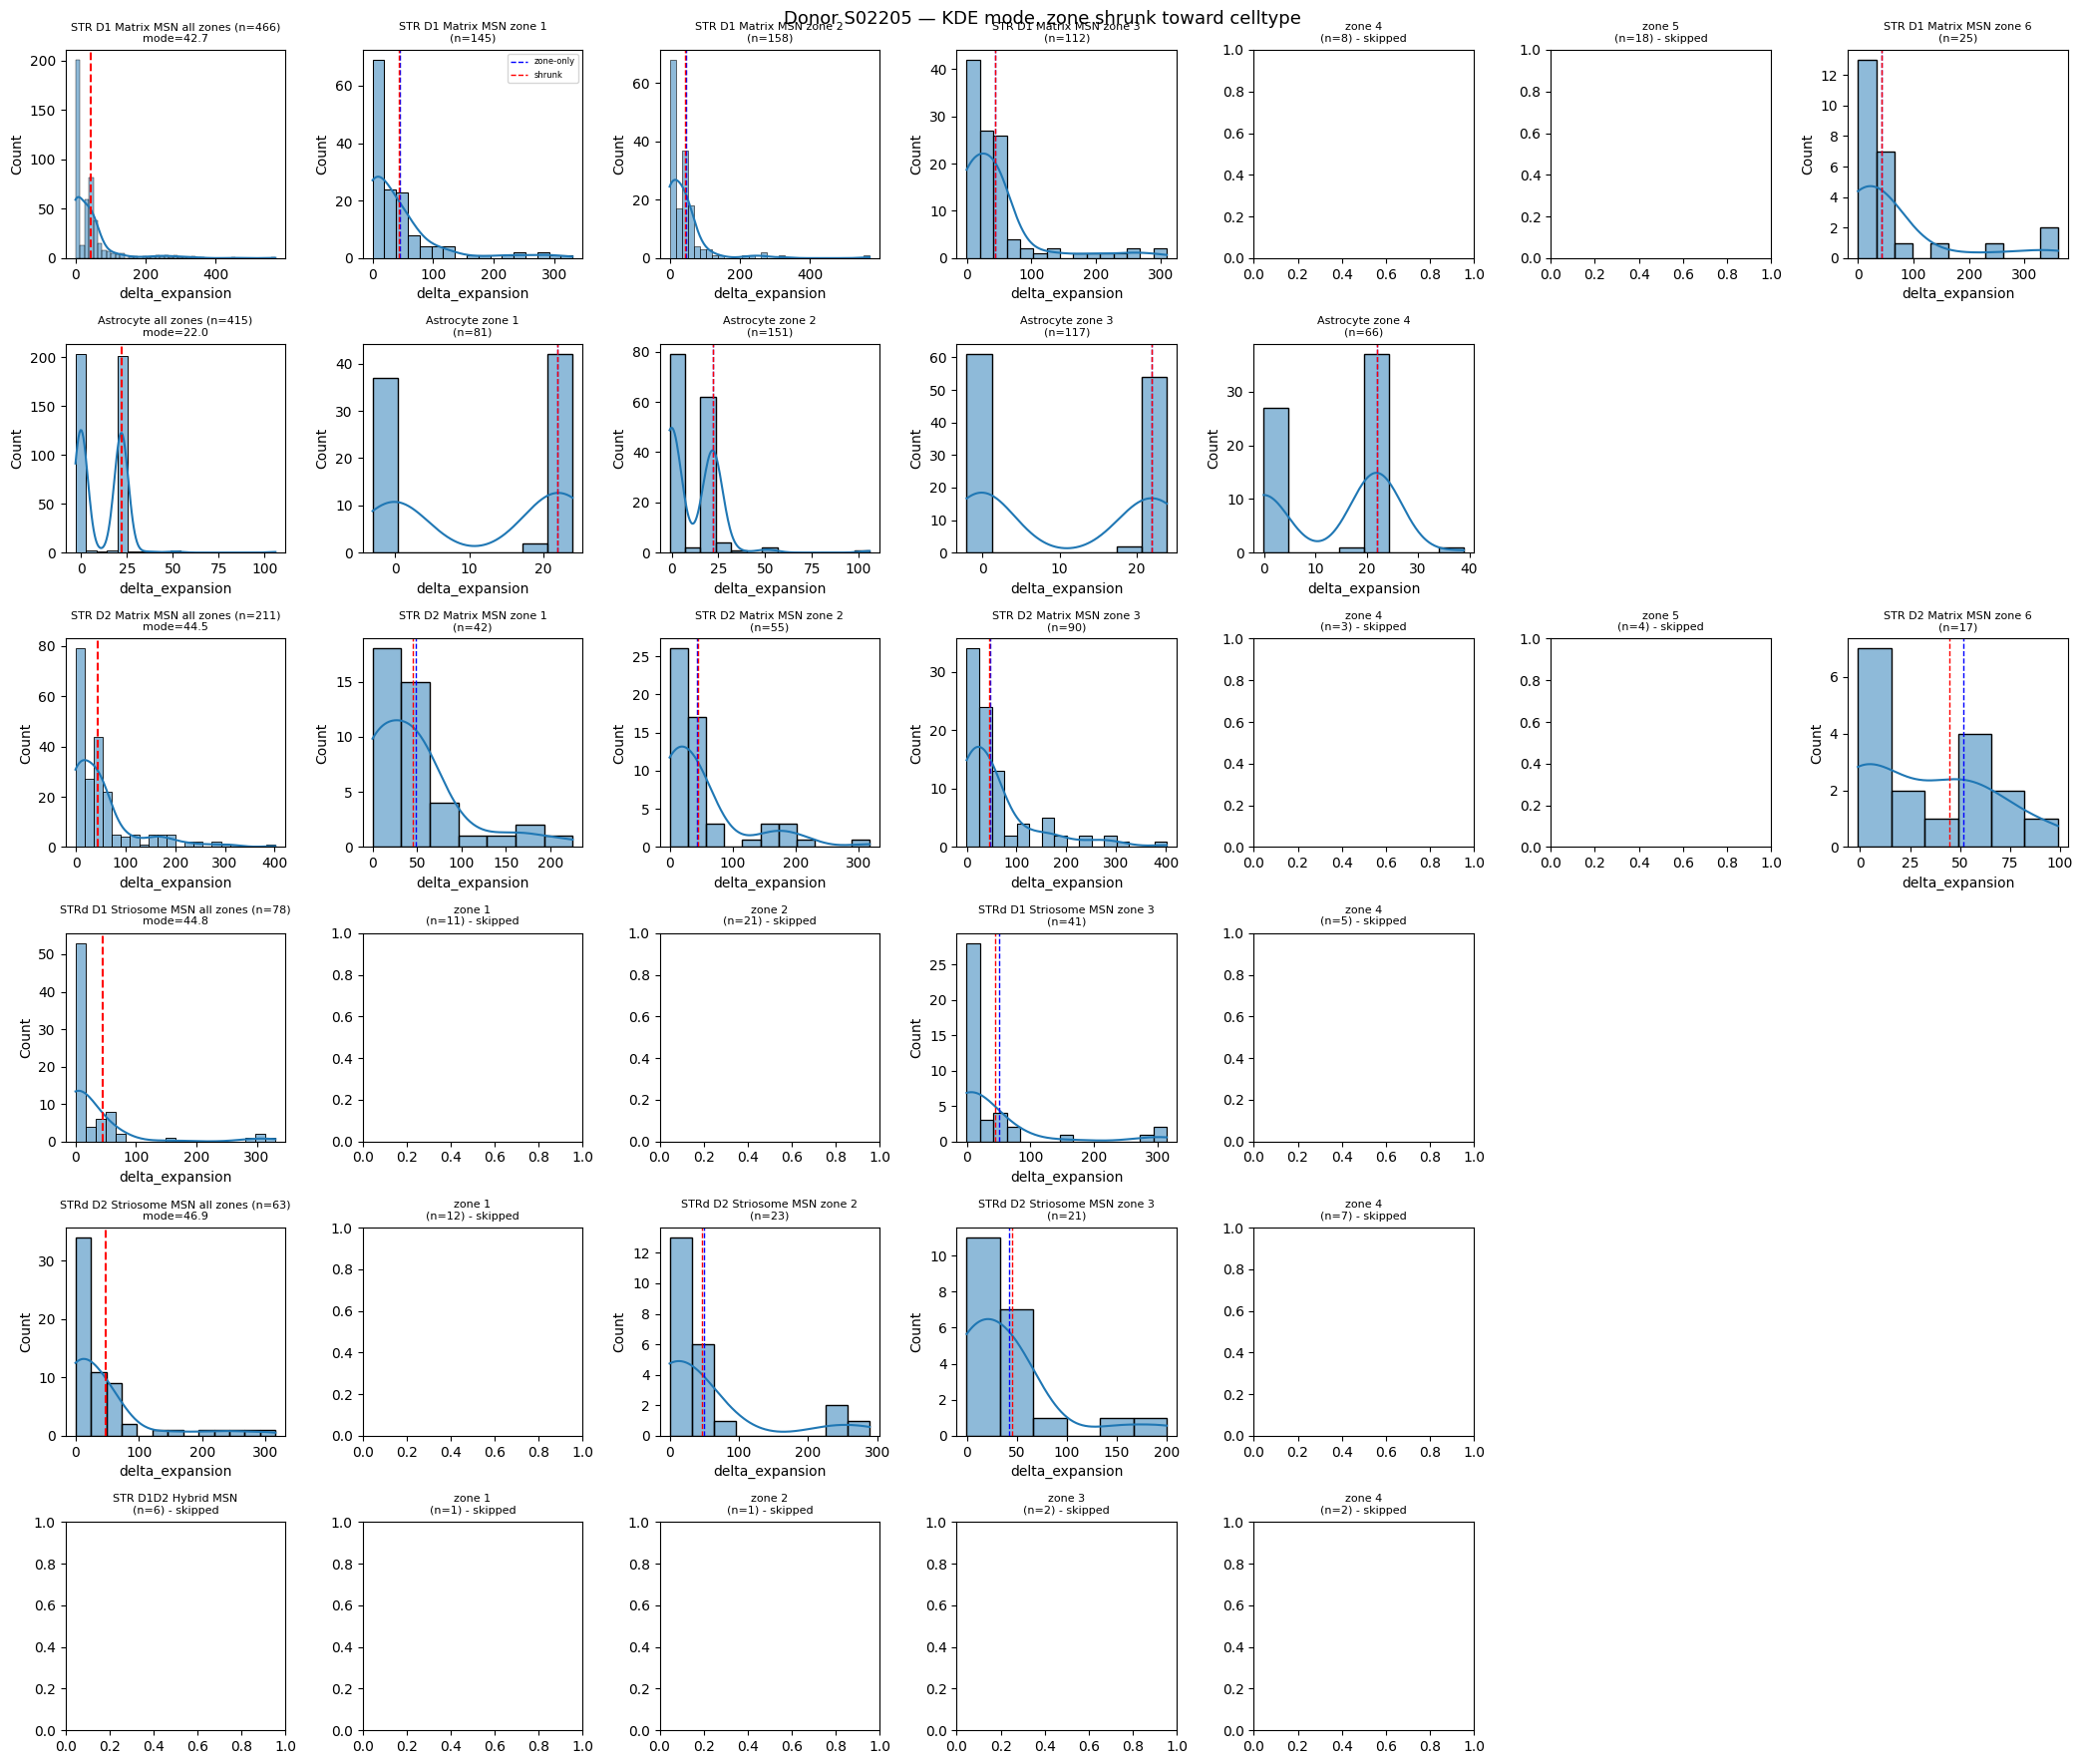

S04002


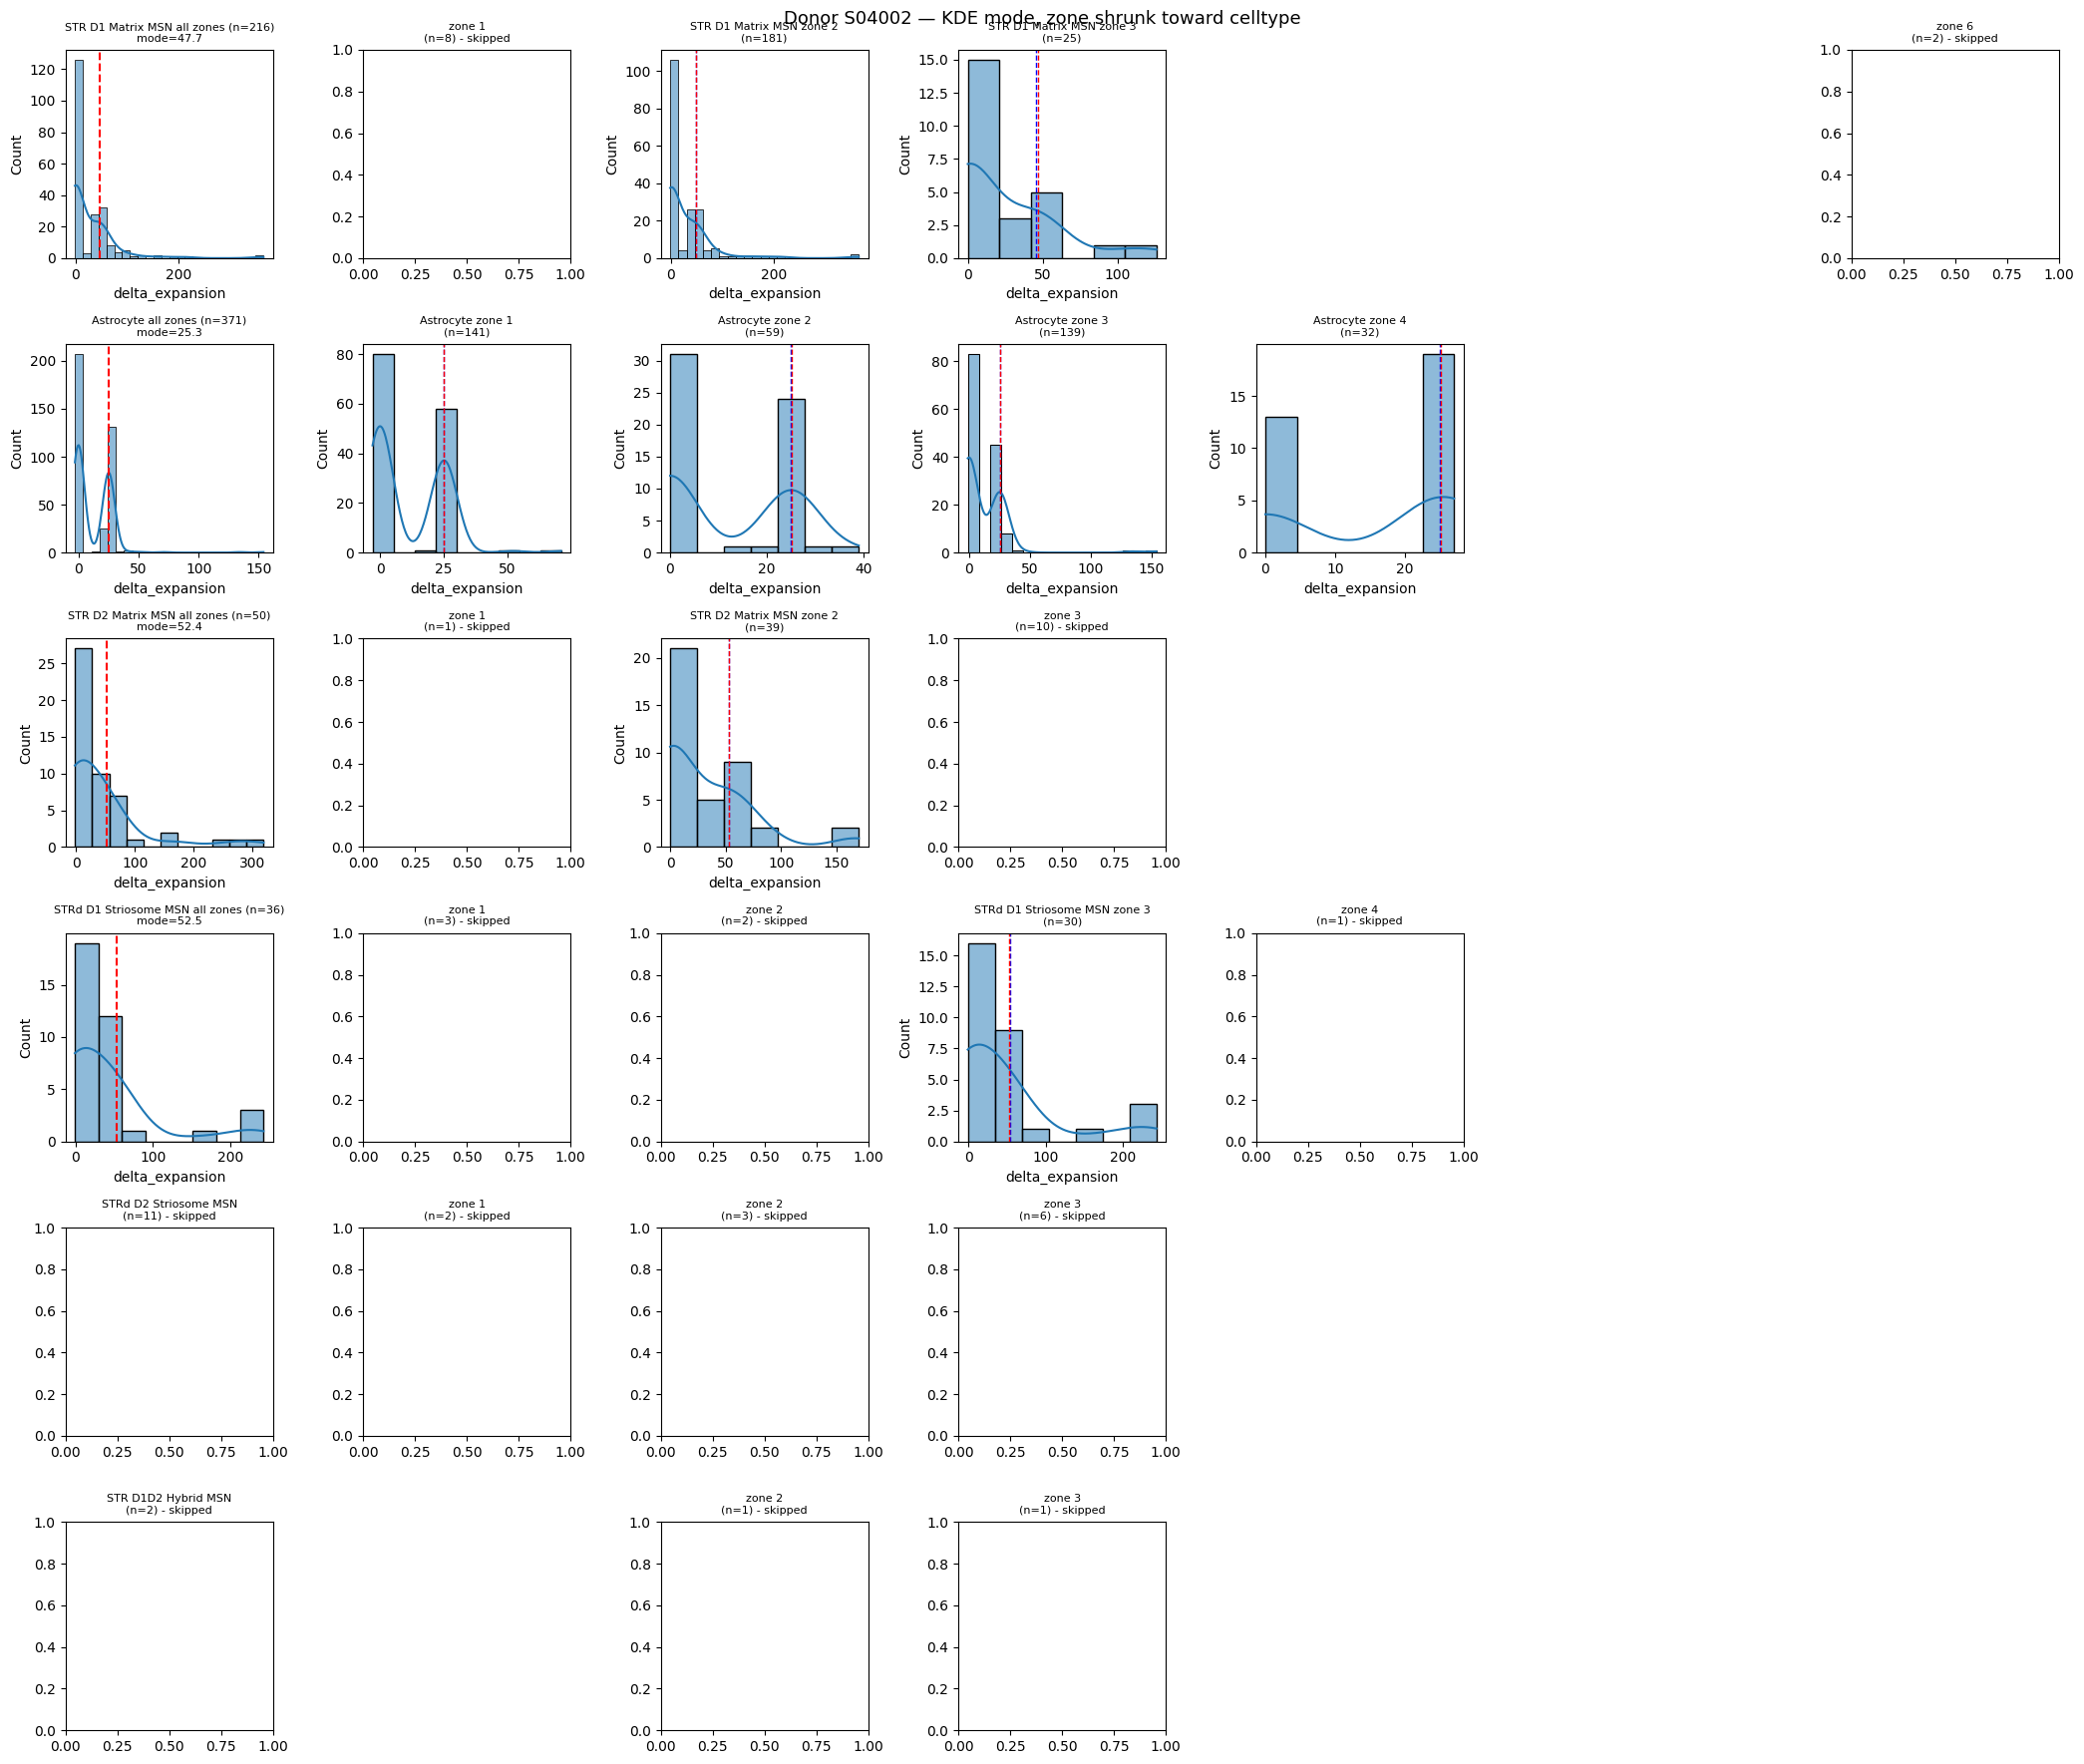

S04577


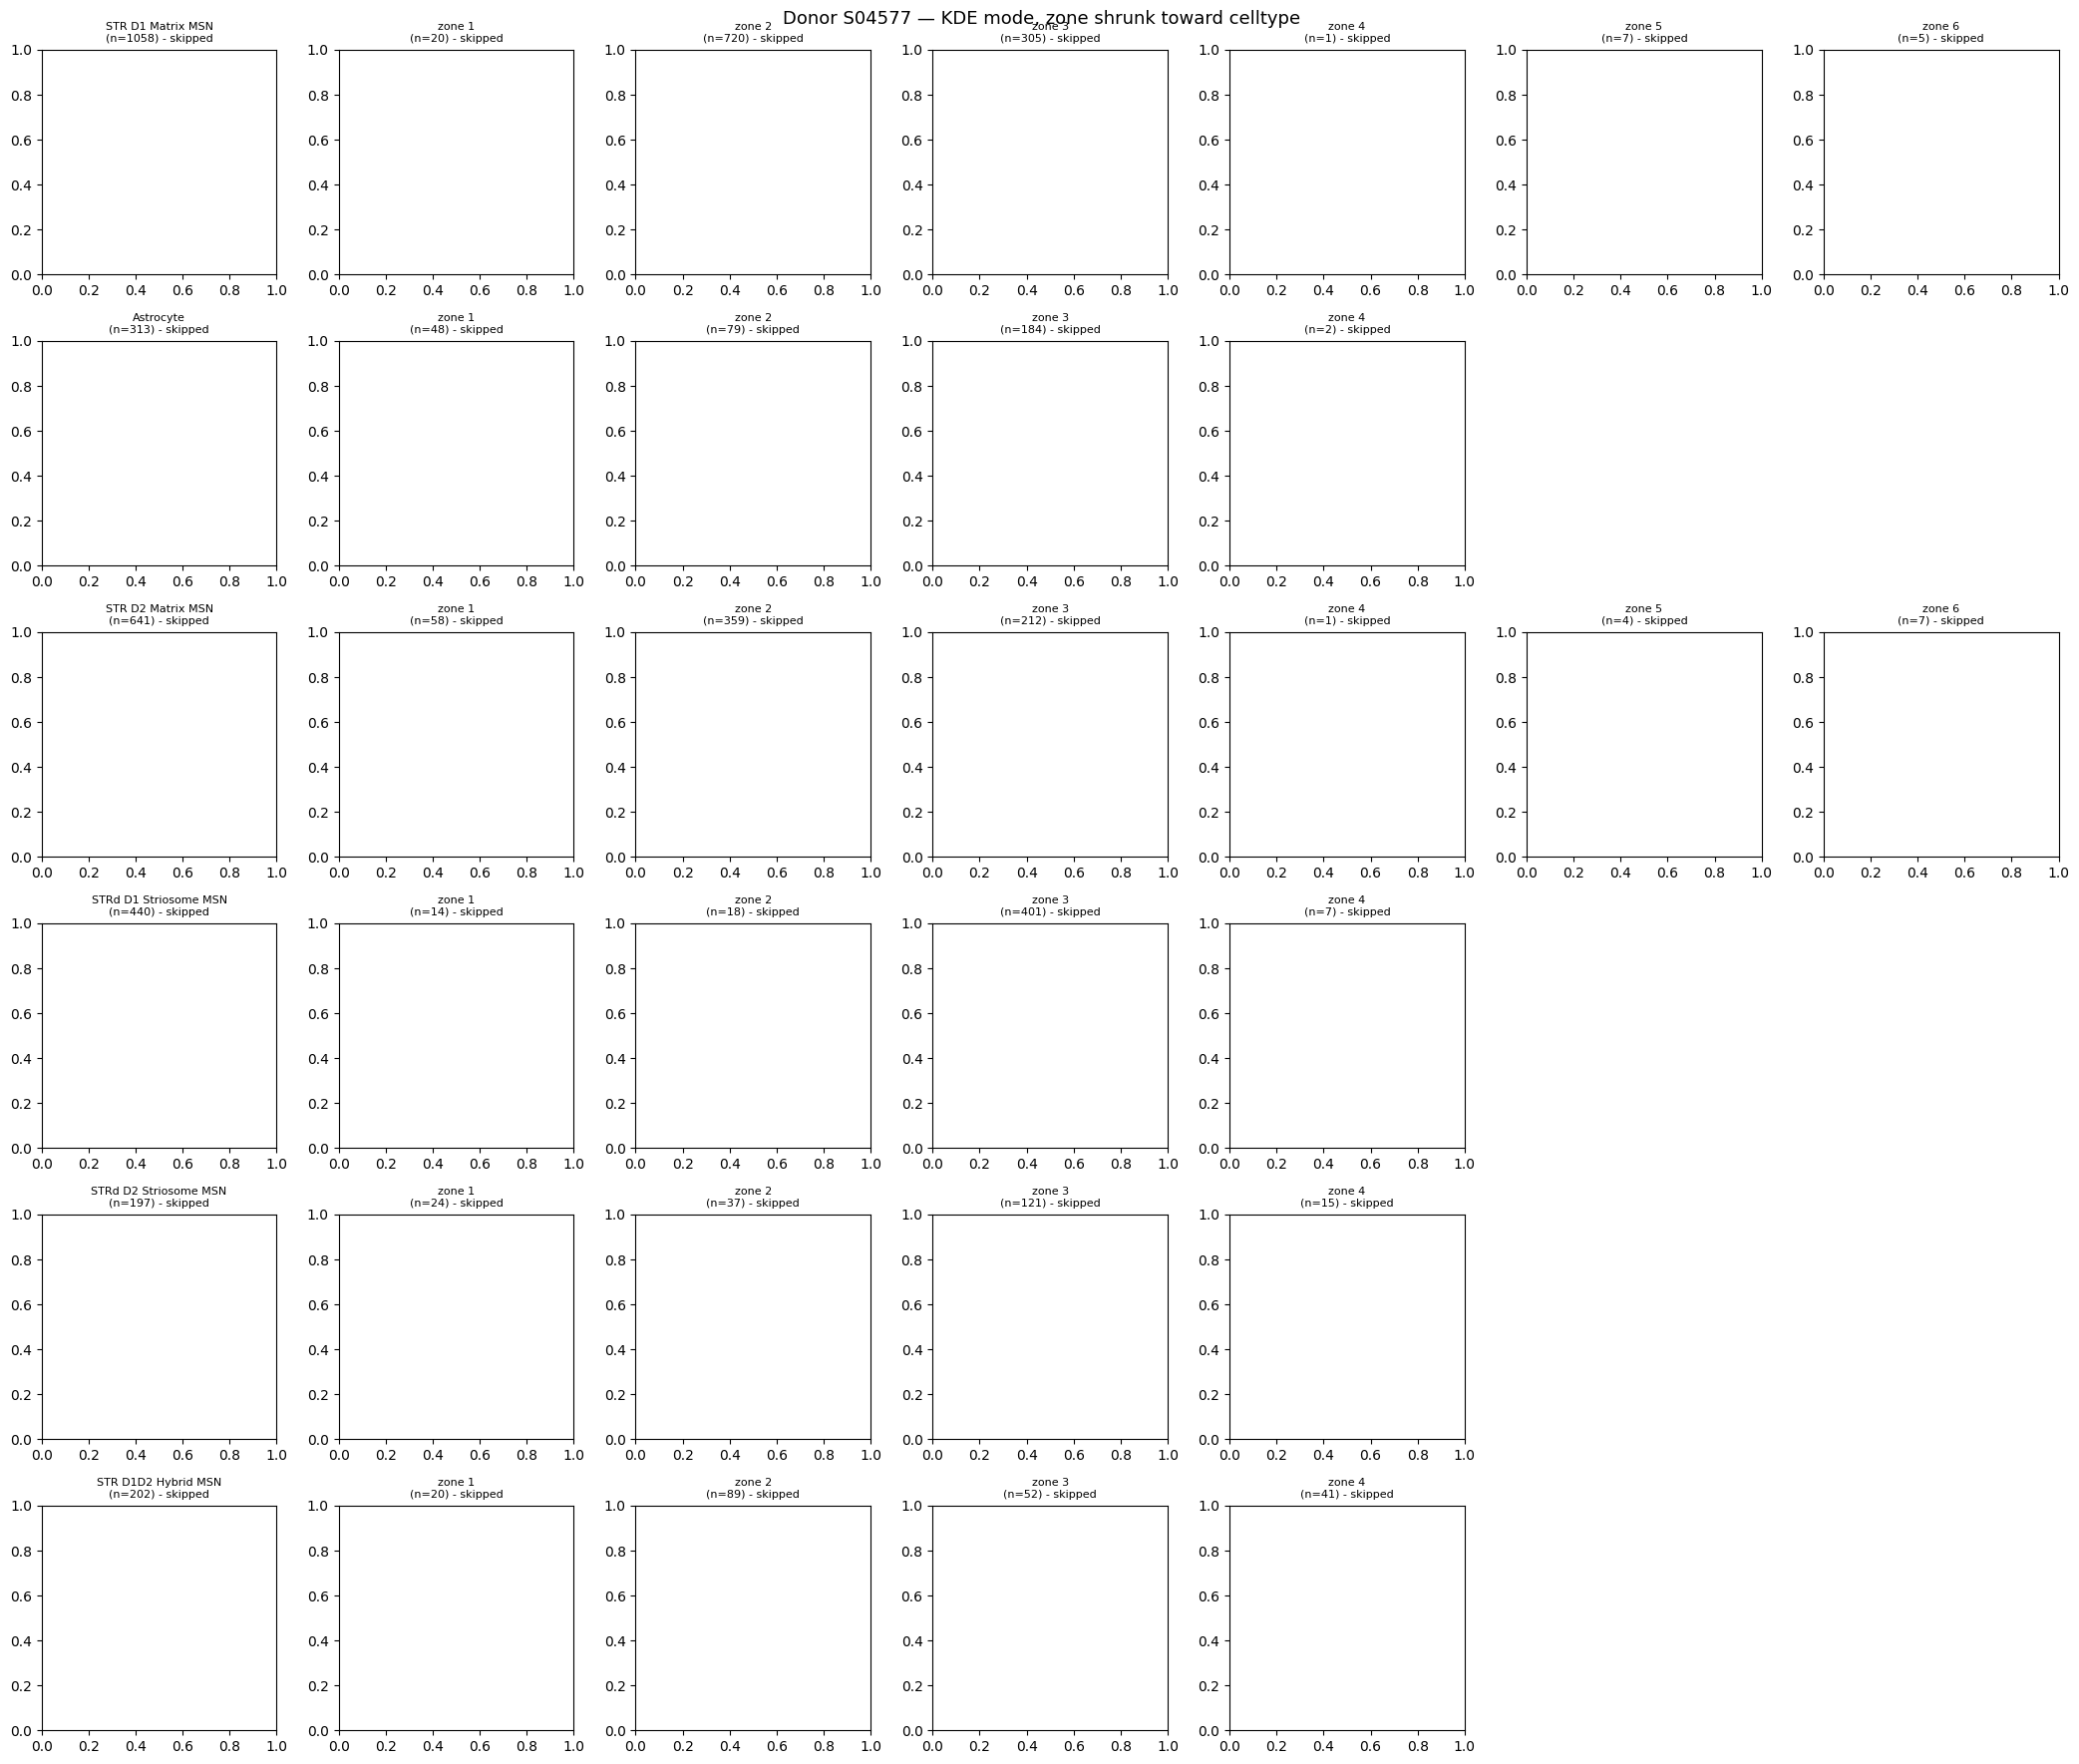

S05202


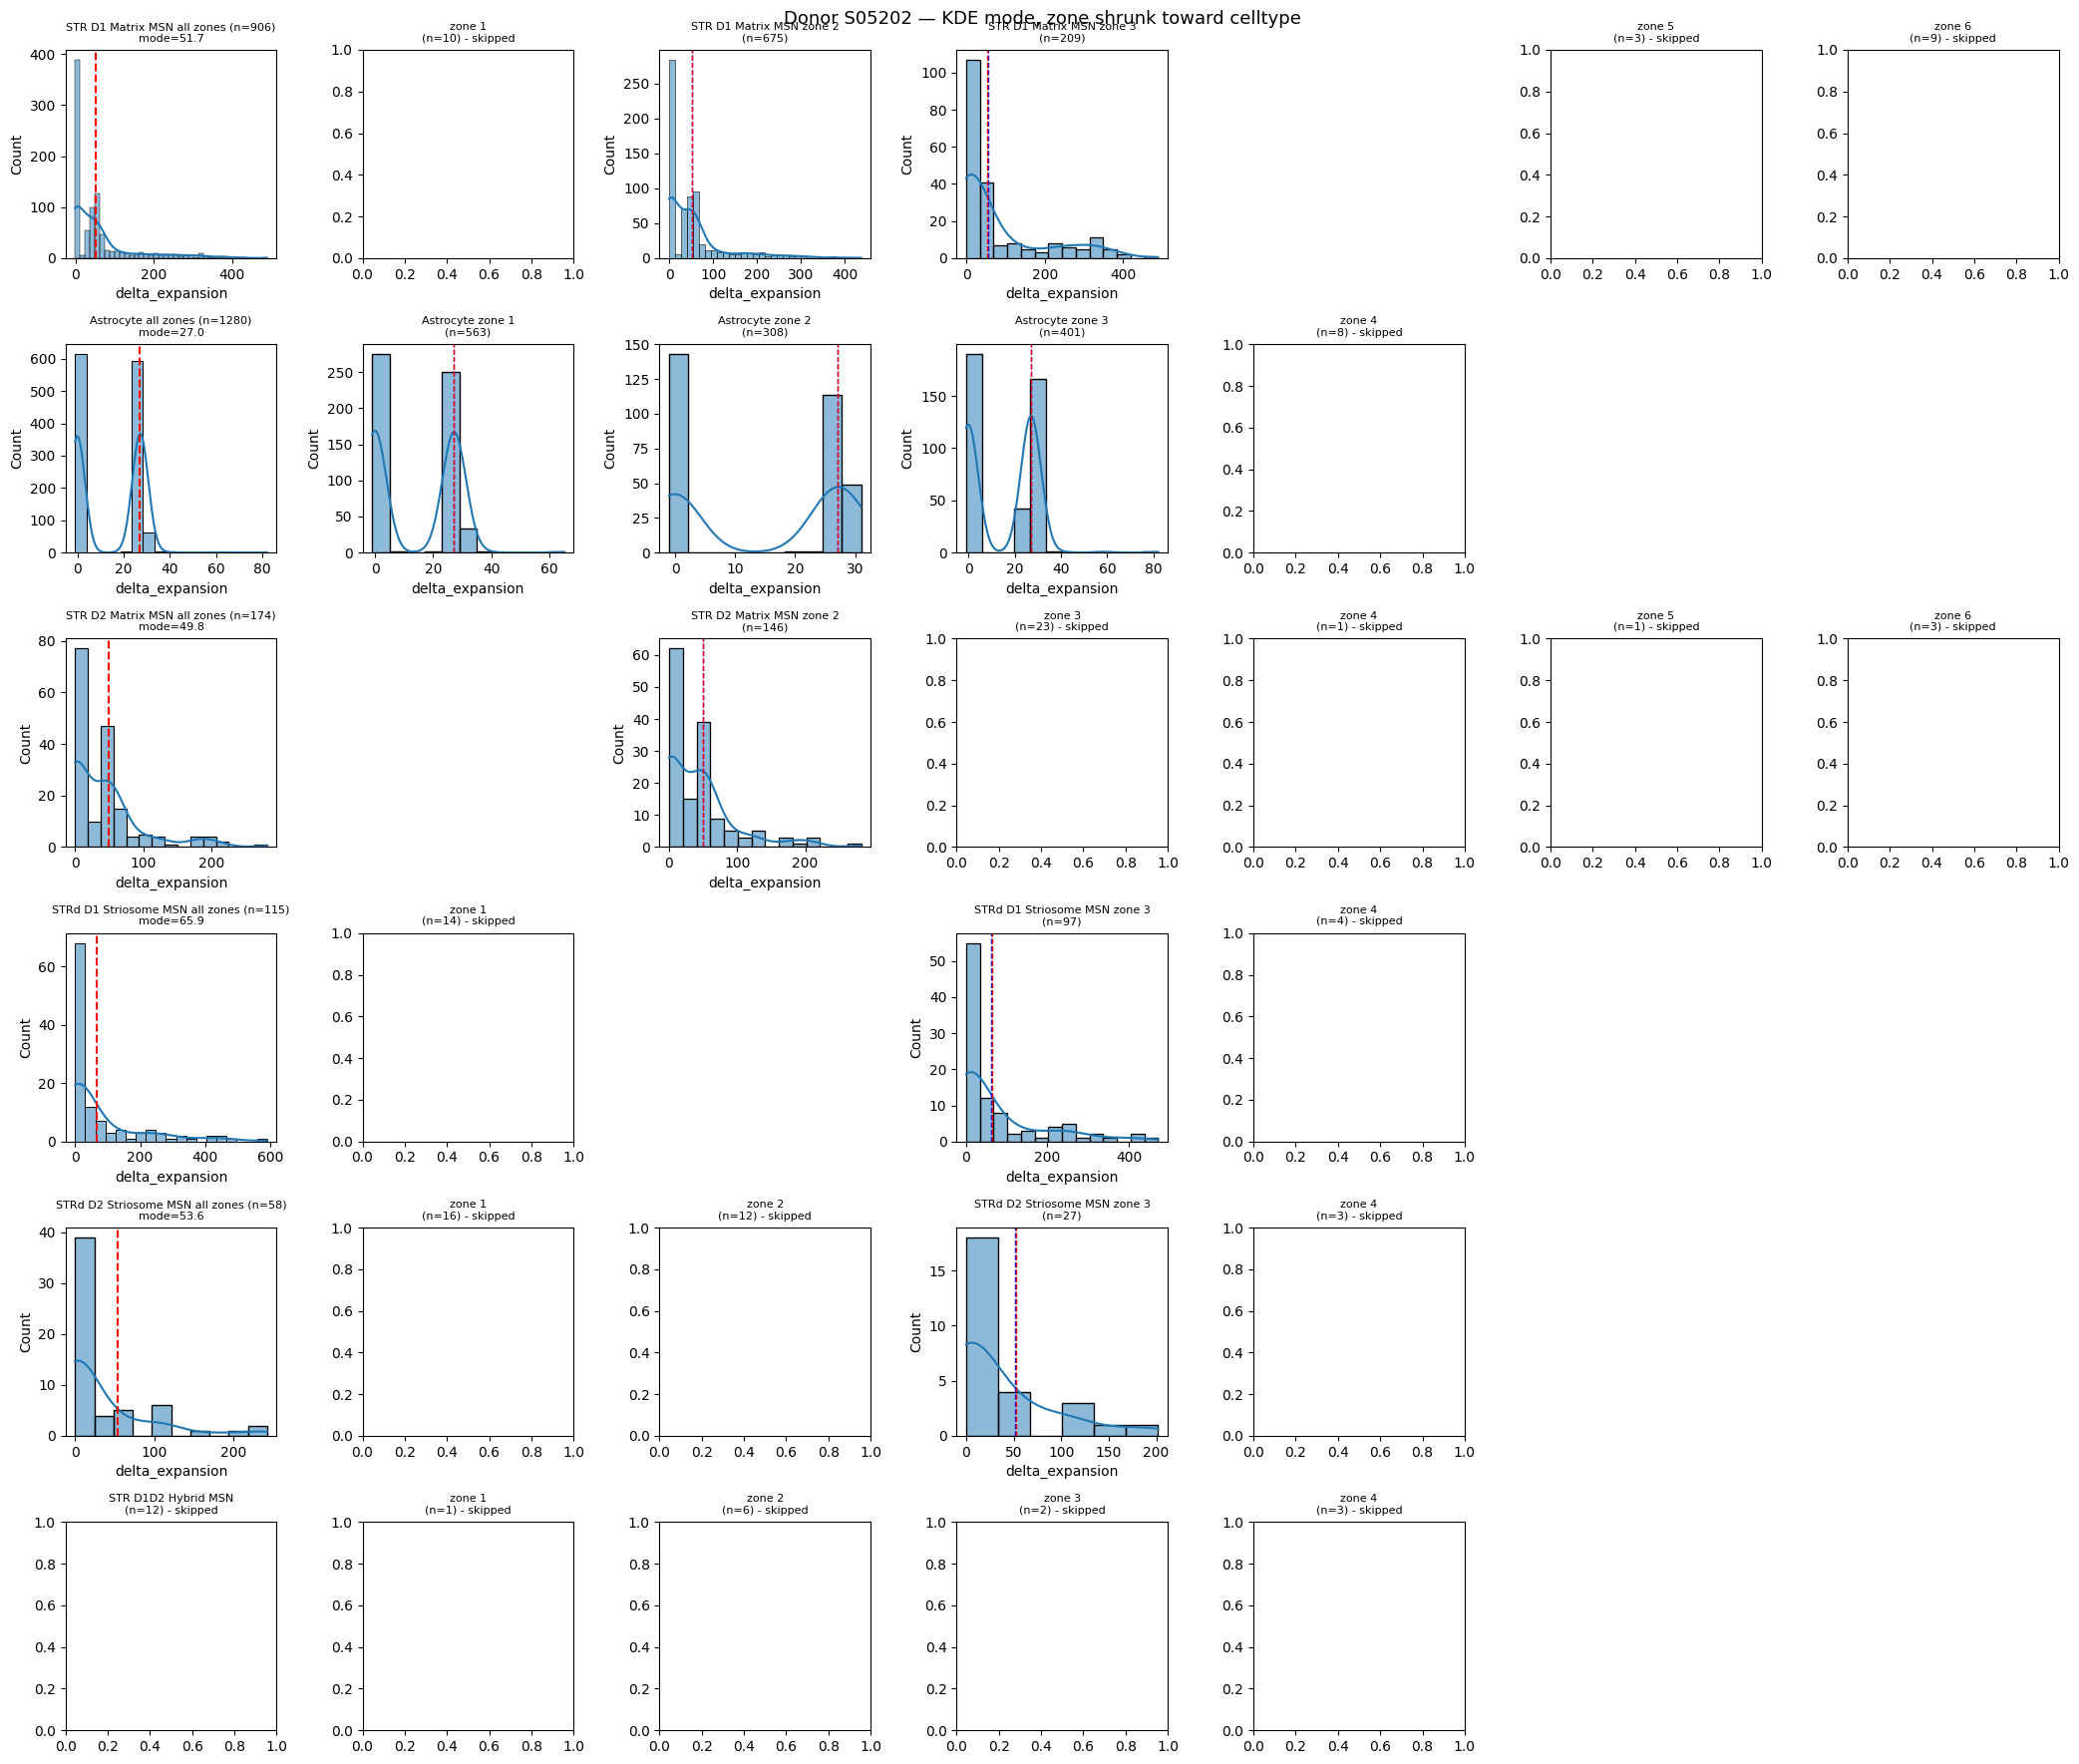

S05368


/tmp/ipykernel_192204/1757179691.py:86: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[donor, f"{ct}_{zone}_mode_raw"] = zone_mode
/tmp/ipykernel_192204/1757179691.py:87: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[donor, f"{ct}_{zone}_mode_shrunk"] = shrunk_mode


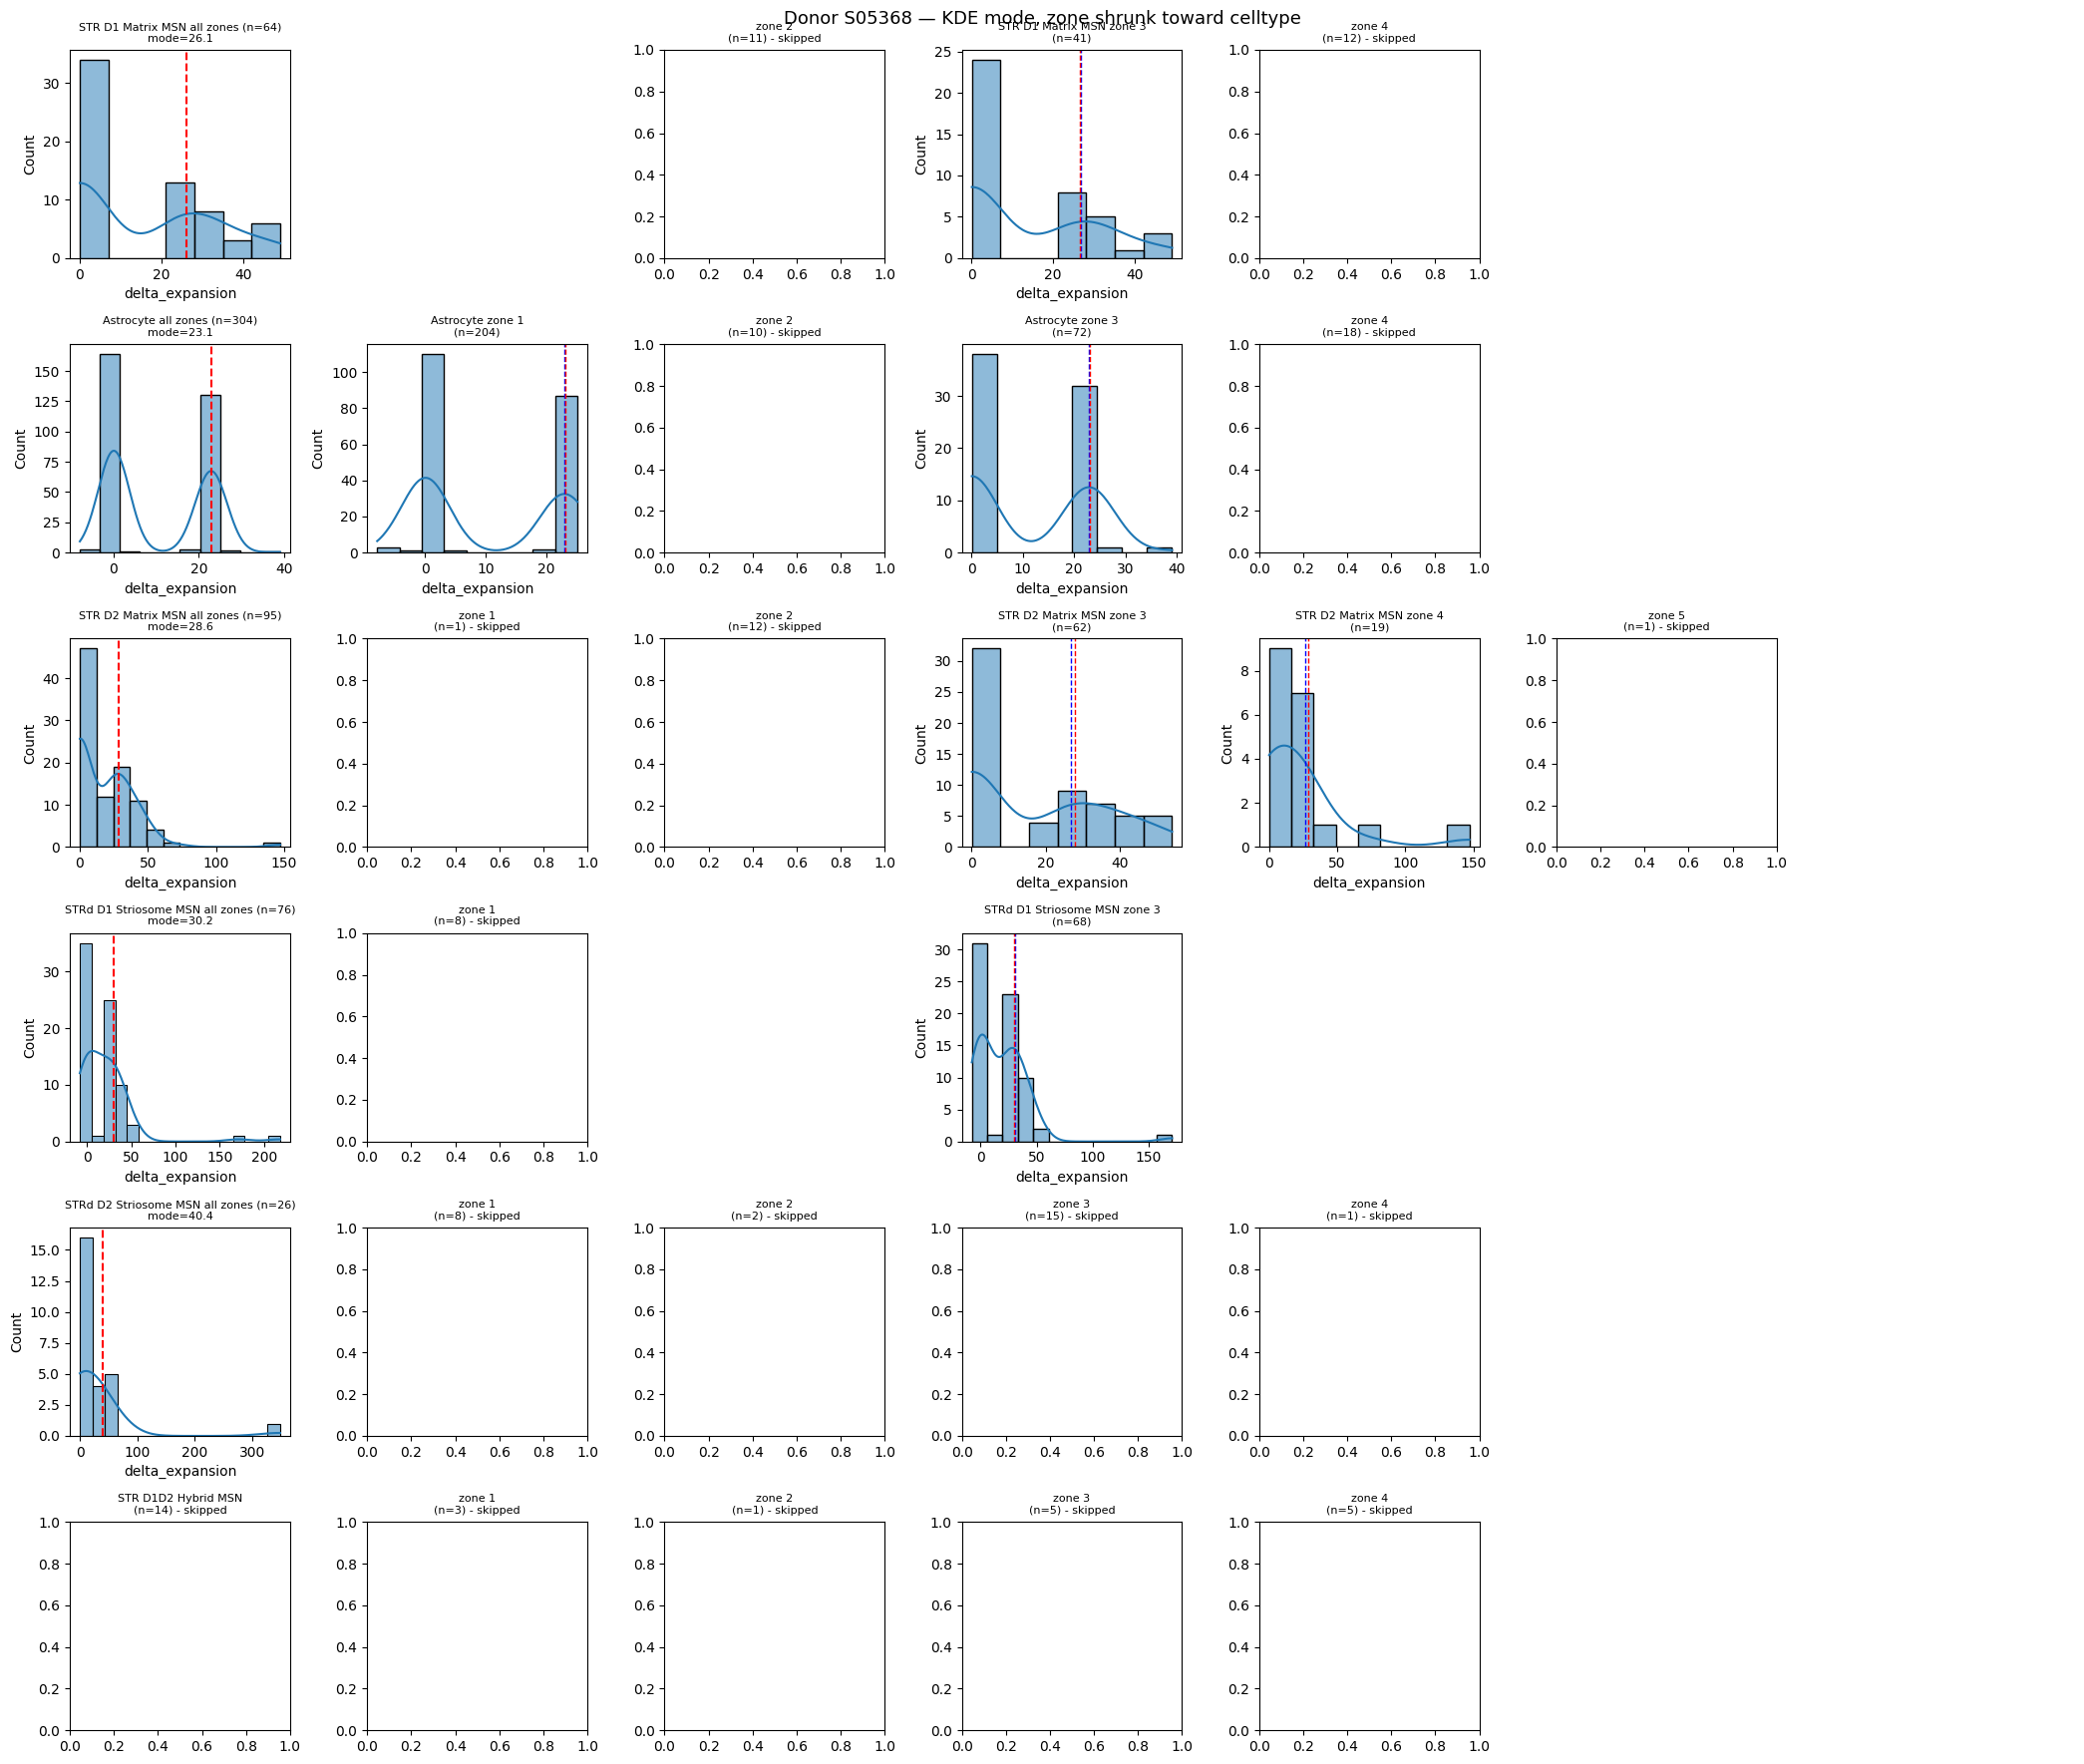

S06758


/tmp/ipykernel_192204/1757179691.py:86: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[donor, f"{ct}_{zone}_mode_raw"] = zone_mode
/tmp/ipykernel_192204/1757179691.py:87: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[donor, f"{ct}_{zone}_mode_shrunk"] = shrunk_mode
/tmp/ipykernel_192204/1757179691.py:86: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead

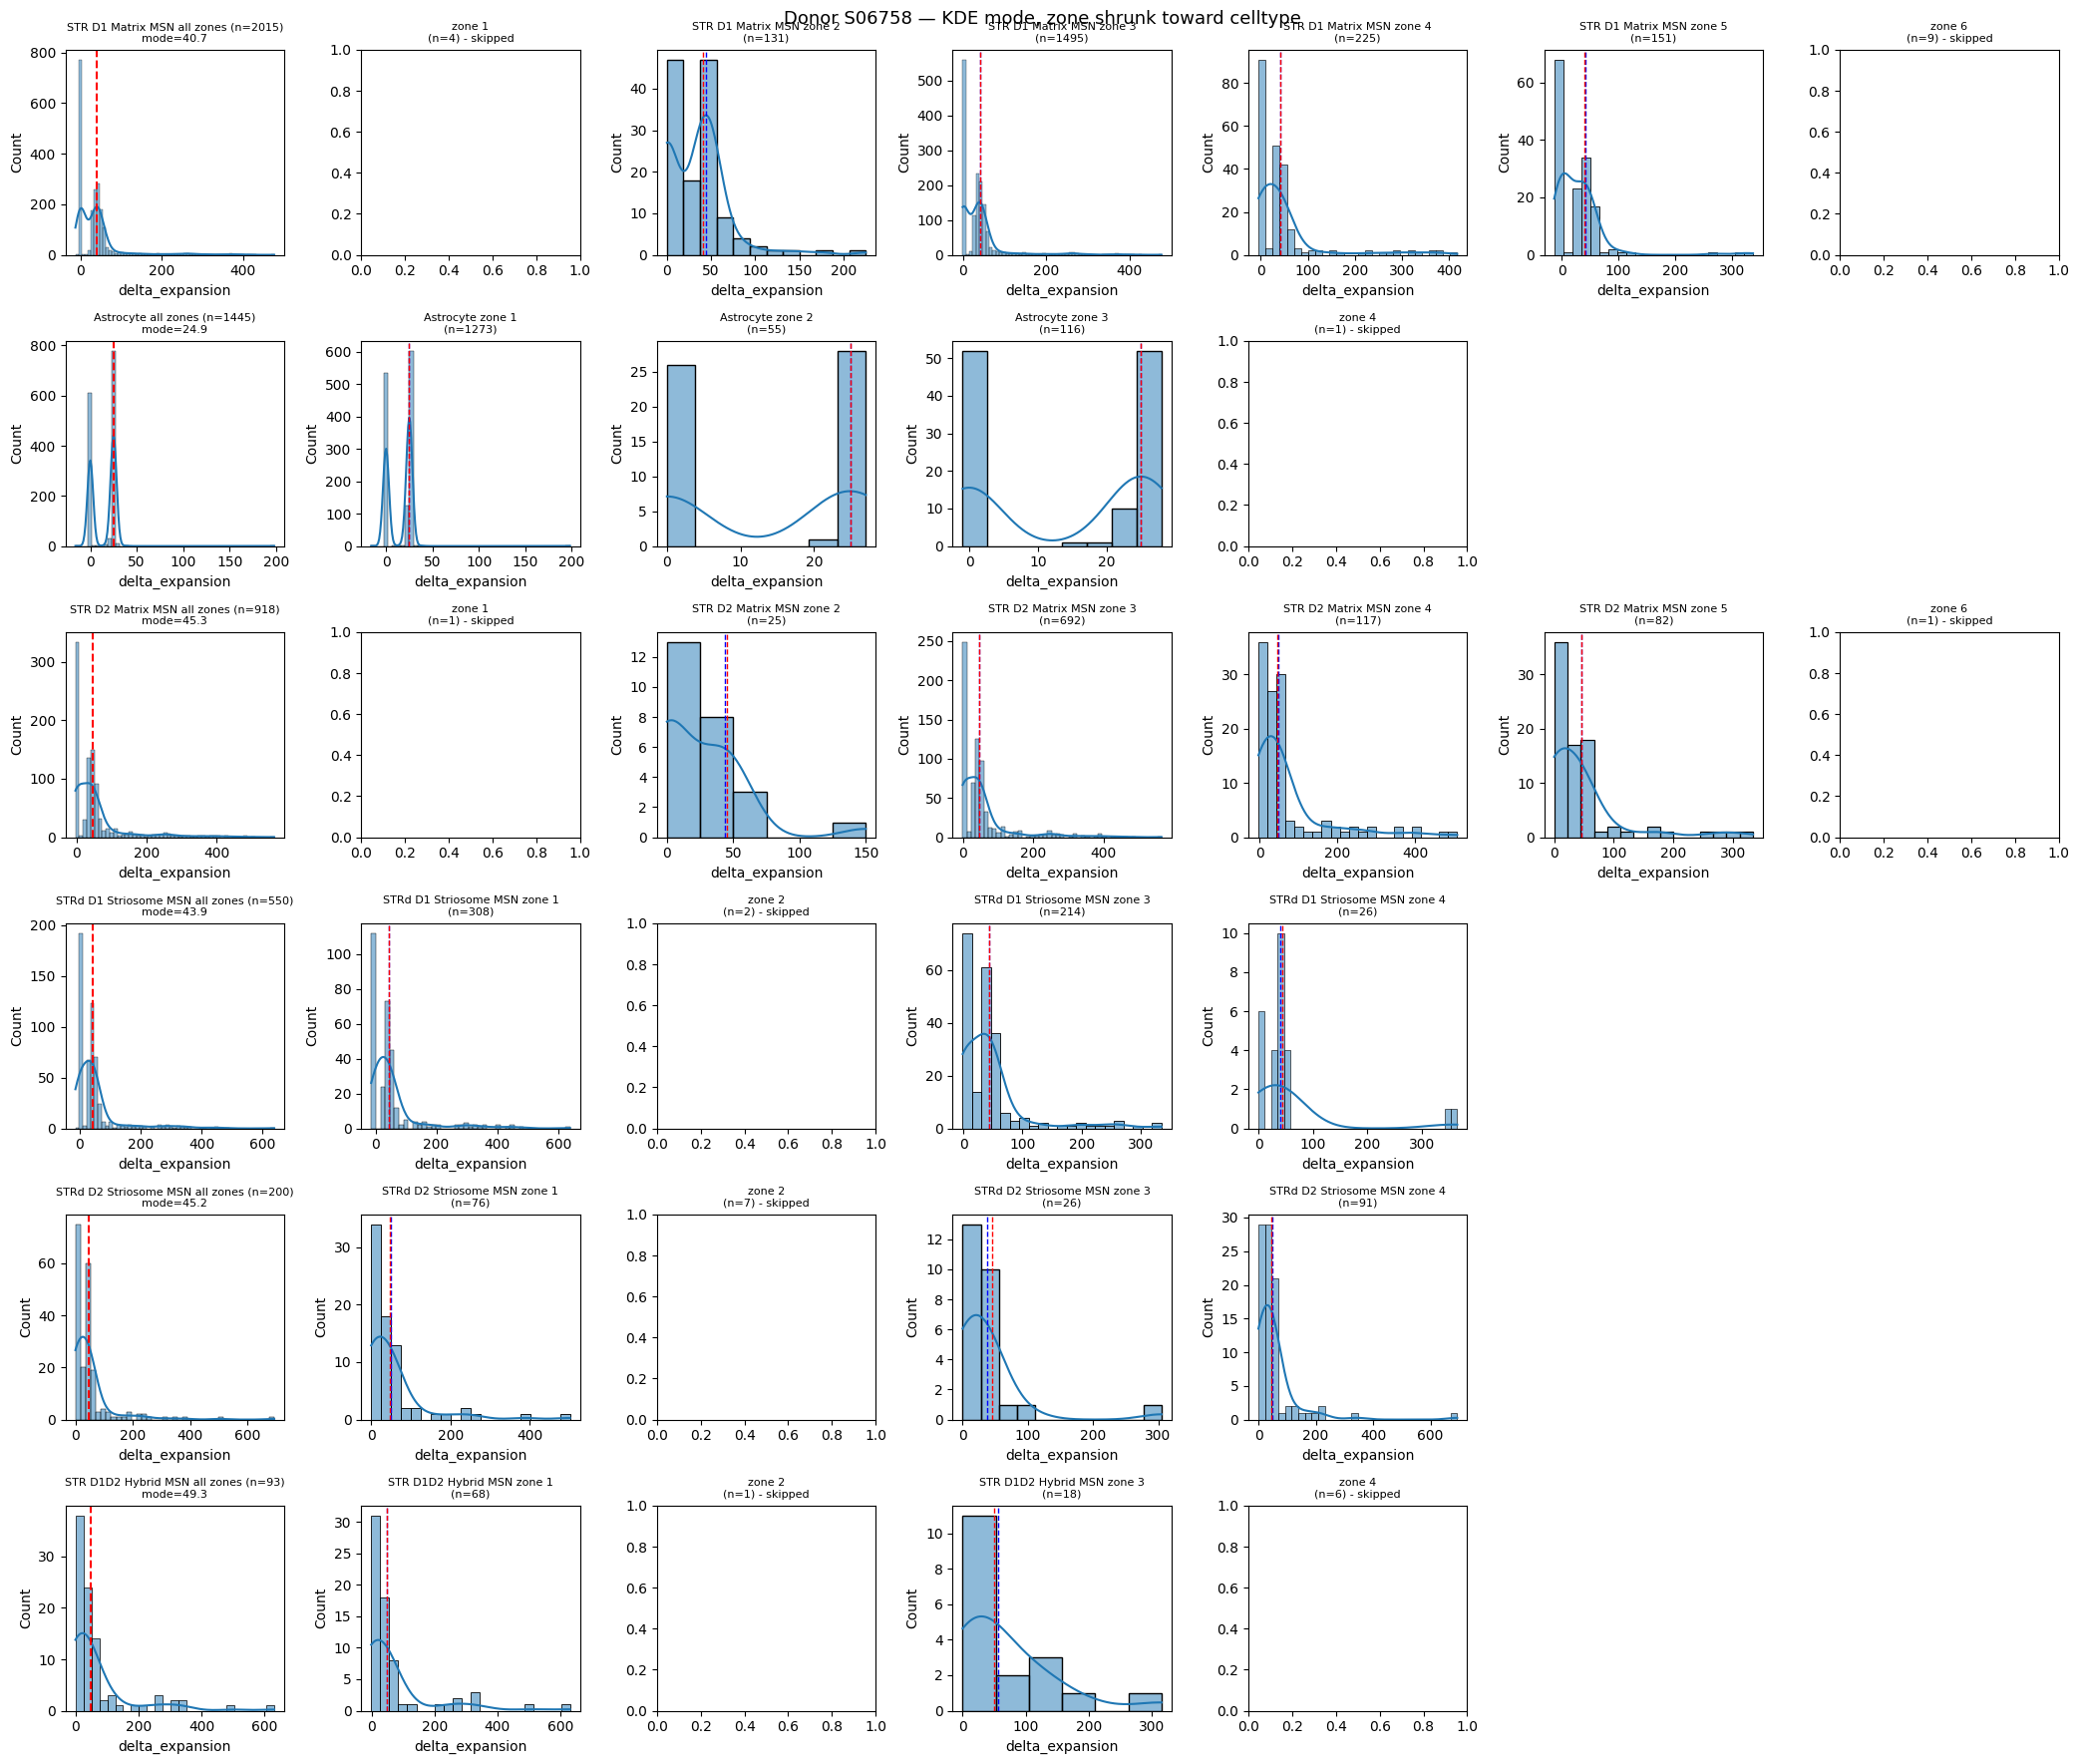

S07681


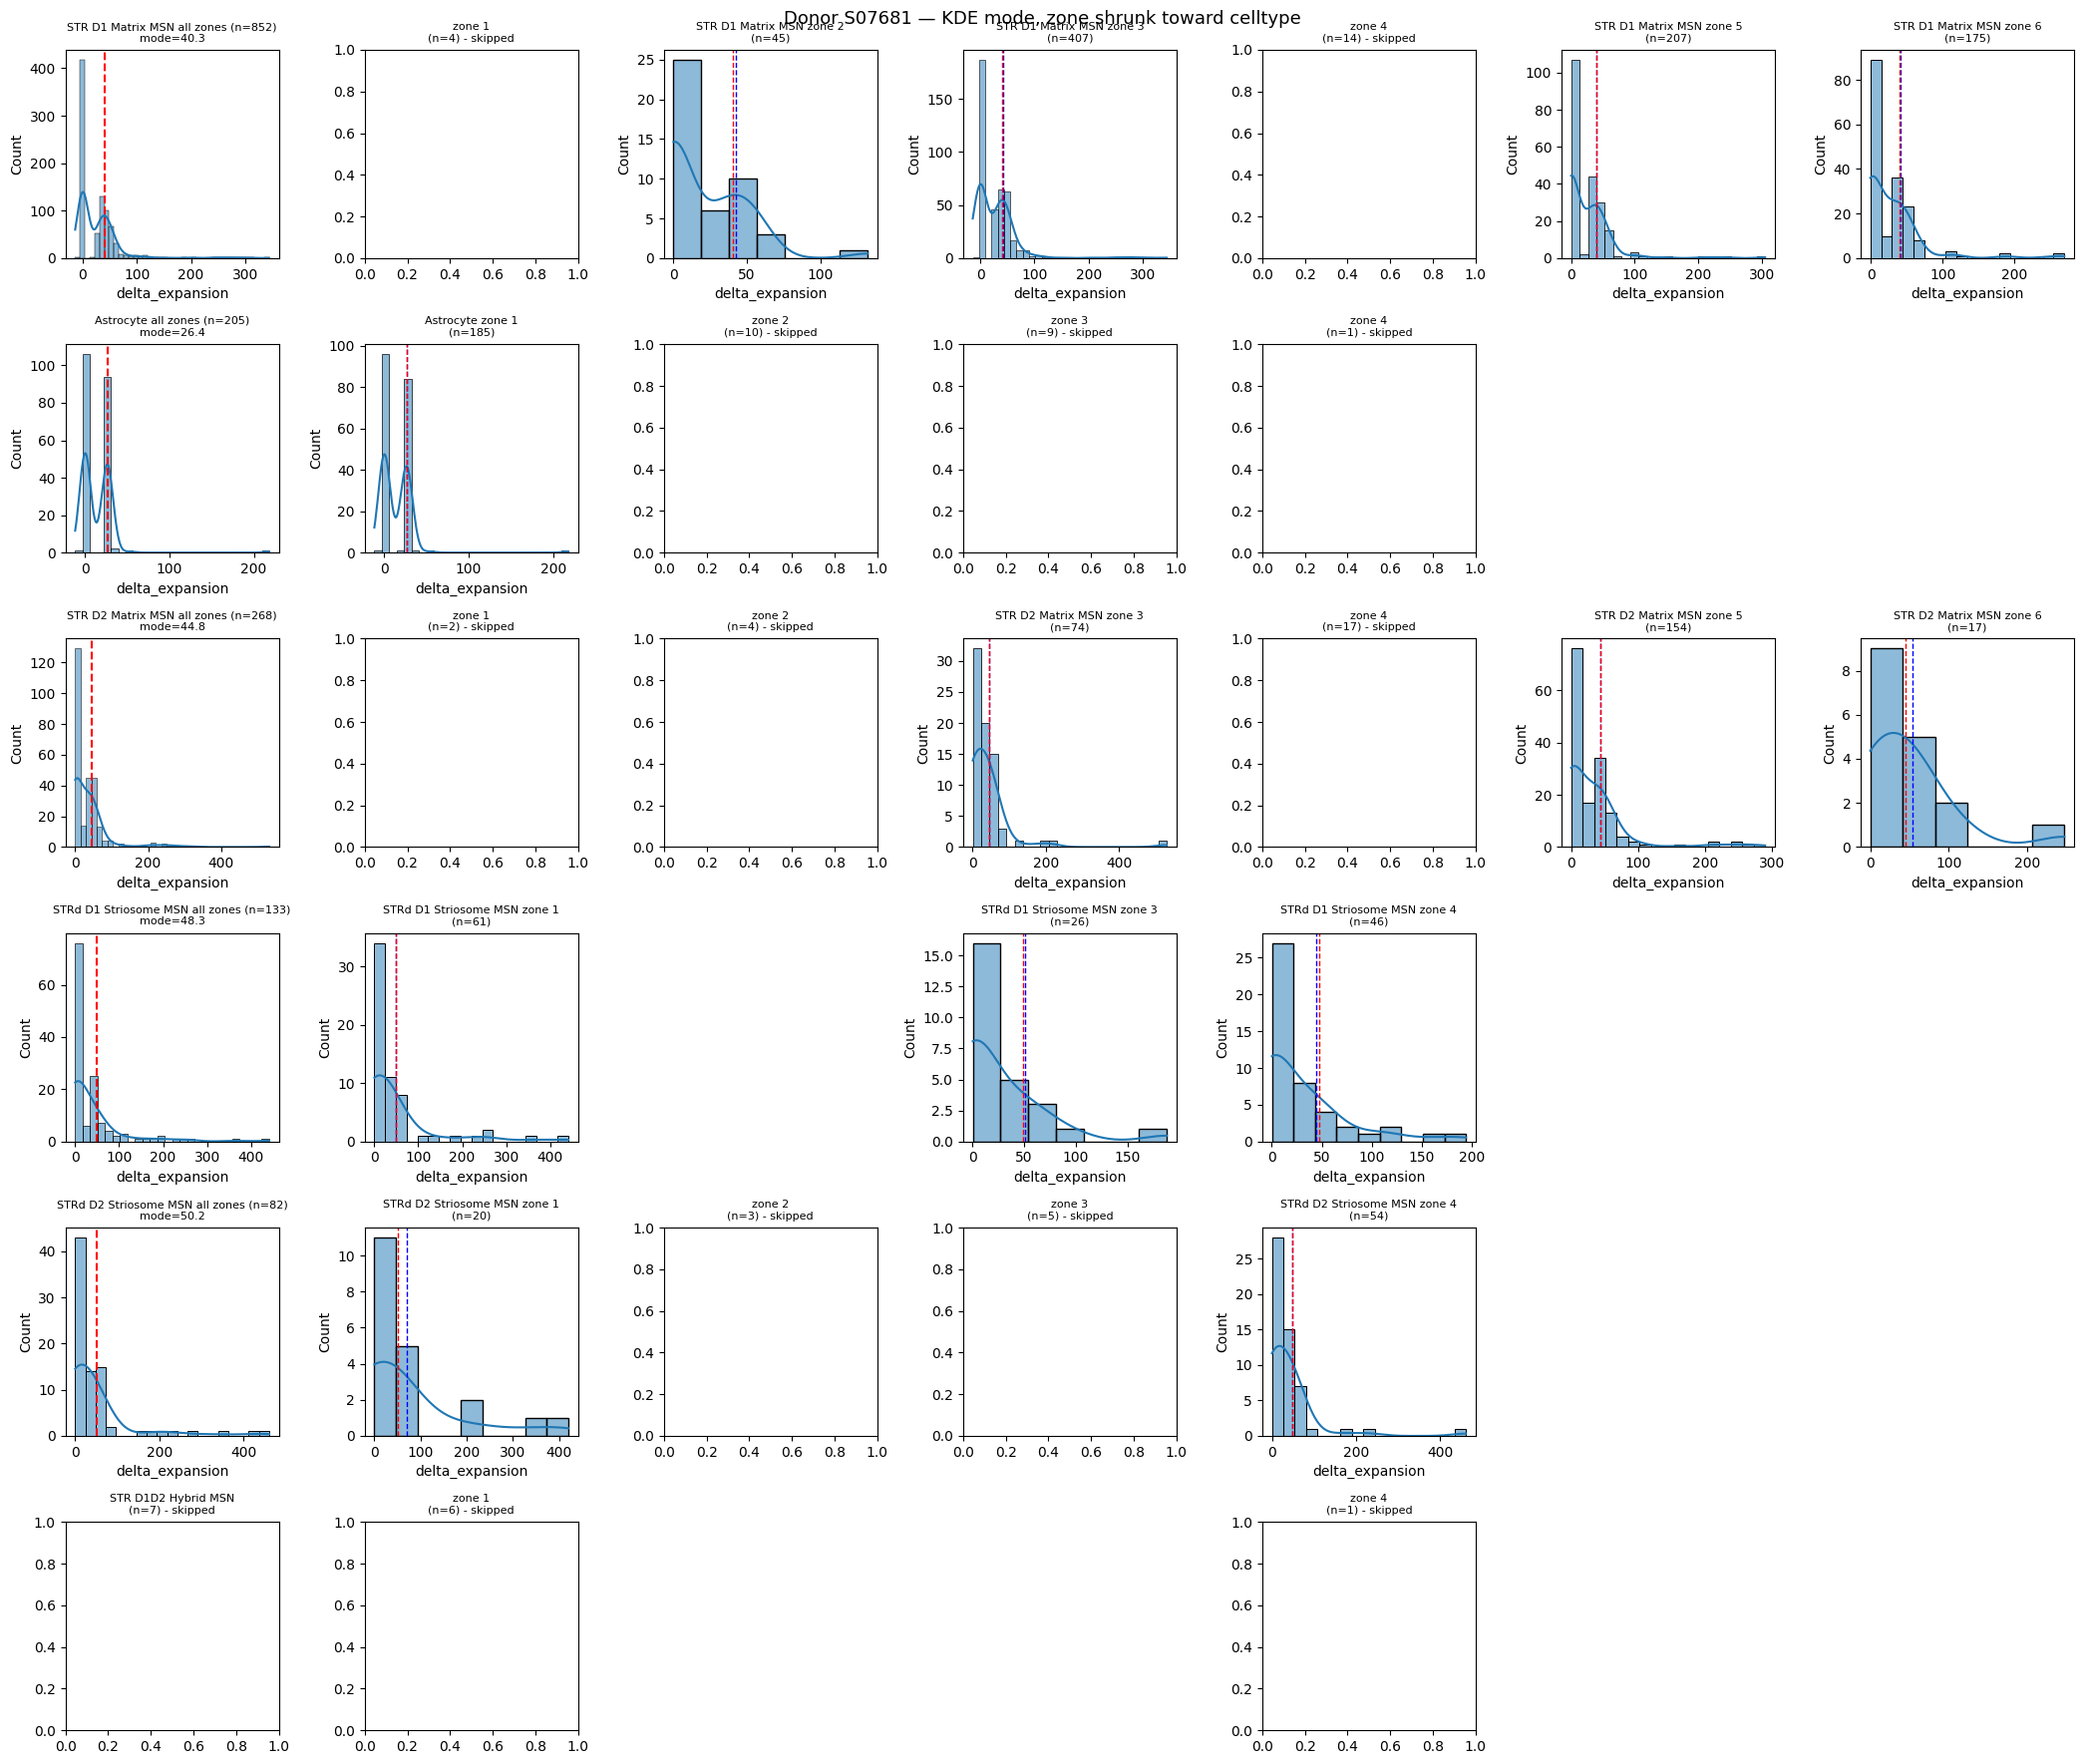

S09619


/tmp/ipykernel_192204/1757179691.py:86: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[donor, f"{ct}_{zone}_mode_raw"] = zone_mode
/tmp/ipykernel_192204/1757179691.py:87: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[donor, f"{ct}_{zone}_mode_shrunk"] = shrunk_mode


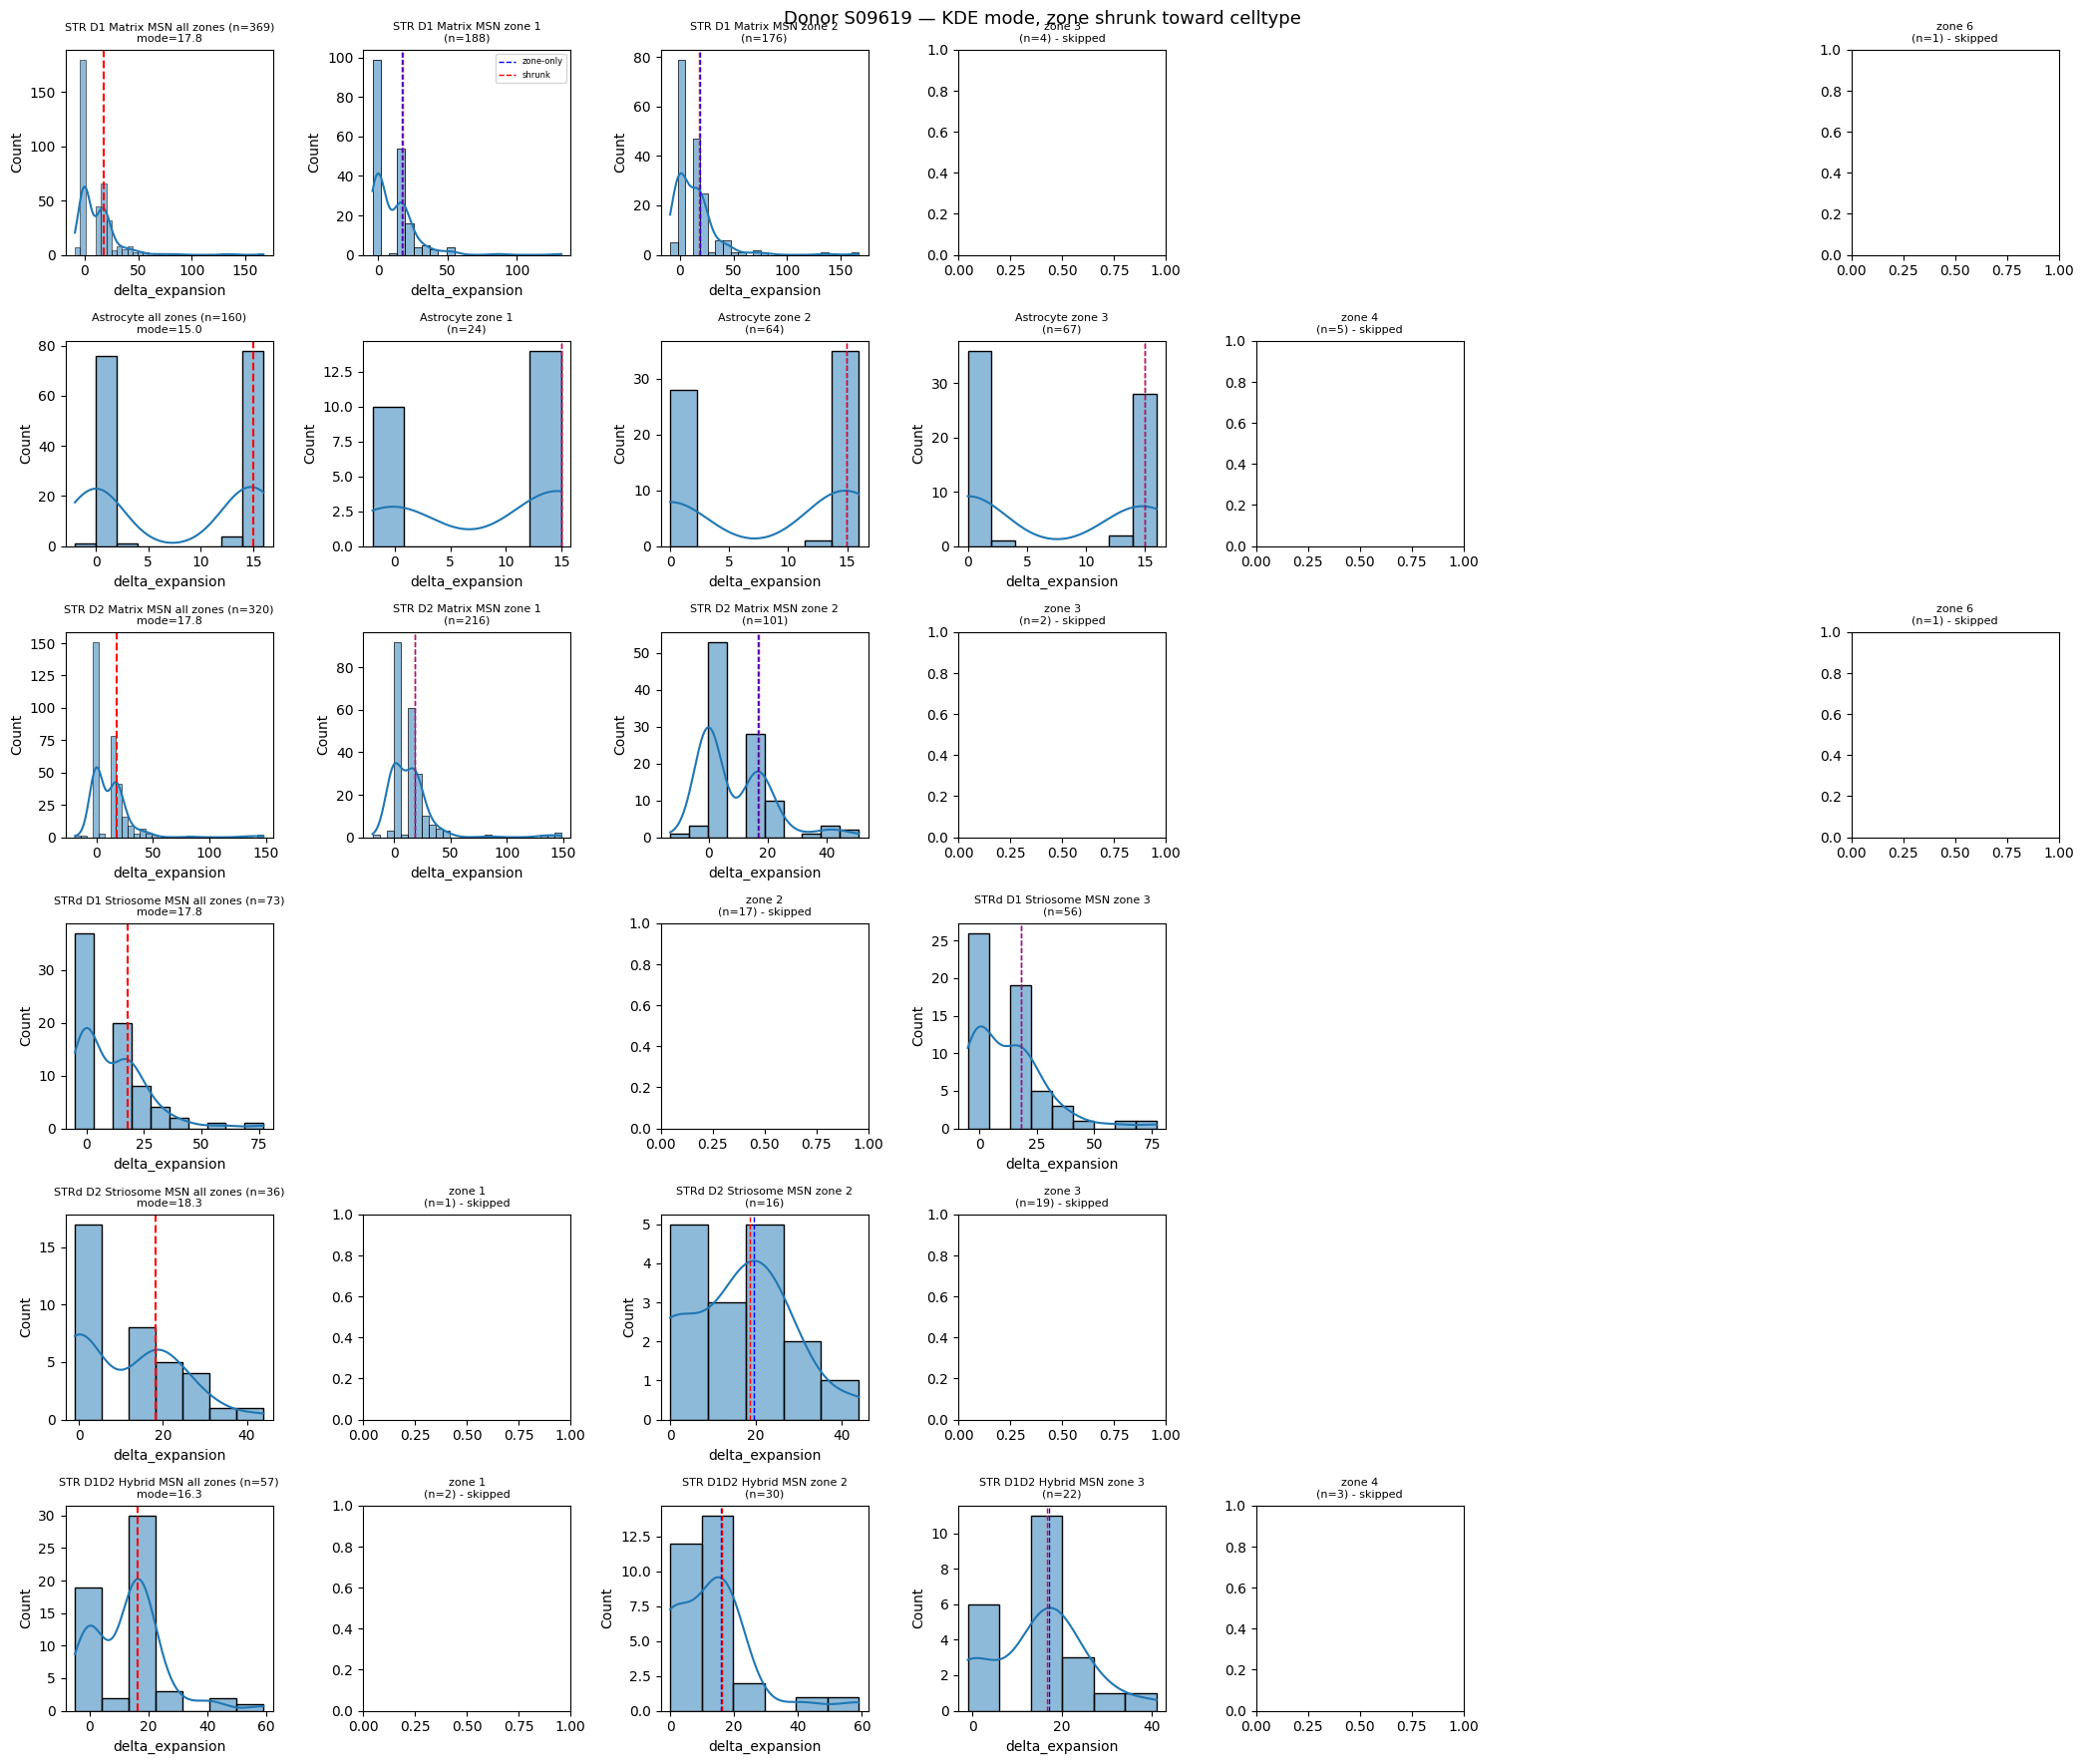

S12365


/tmp/ipykernel_192204/1757179691.py:86: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[donor, f"{ct}_{zone}_mode_raw"] = zone_mode
/tmp/ipykernel_192204/1757179691.py:87: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[donor, f"{ct}_{zone}_mode_shrunk"] = shrunk_mode
/tmp/ipykernel_192204/1757179691.py:86: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead

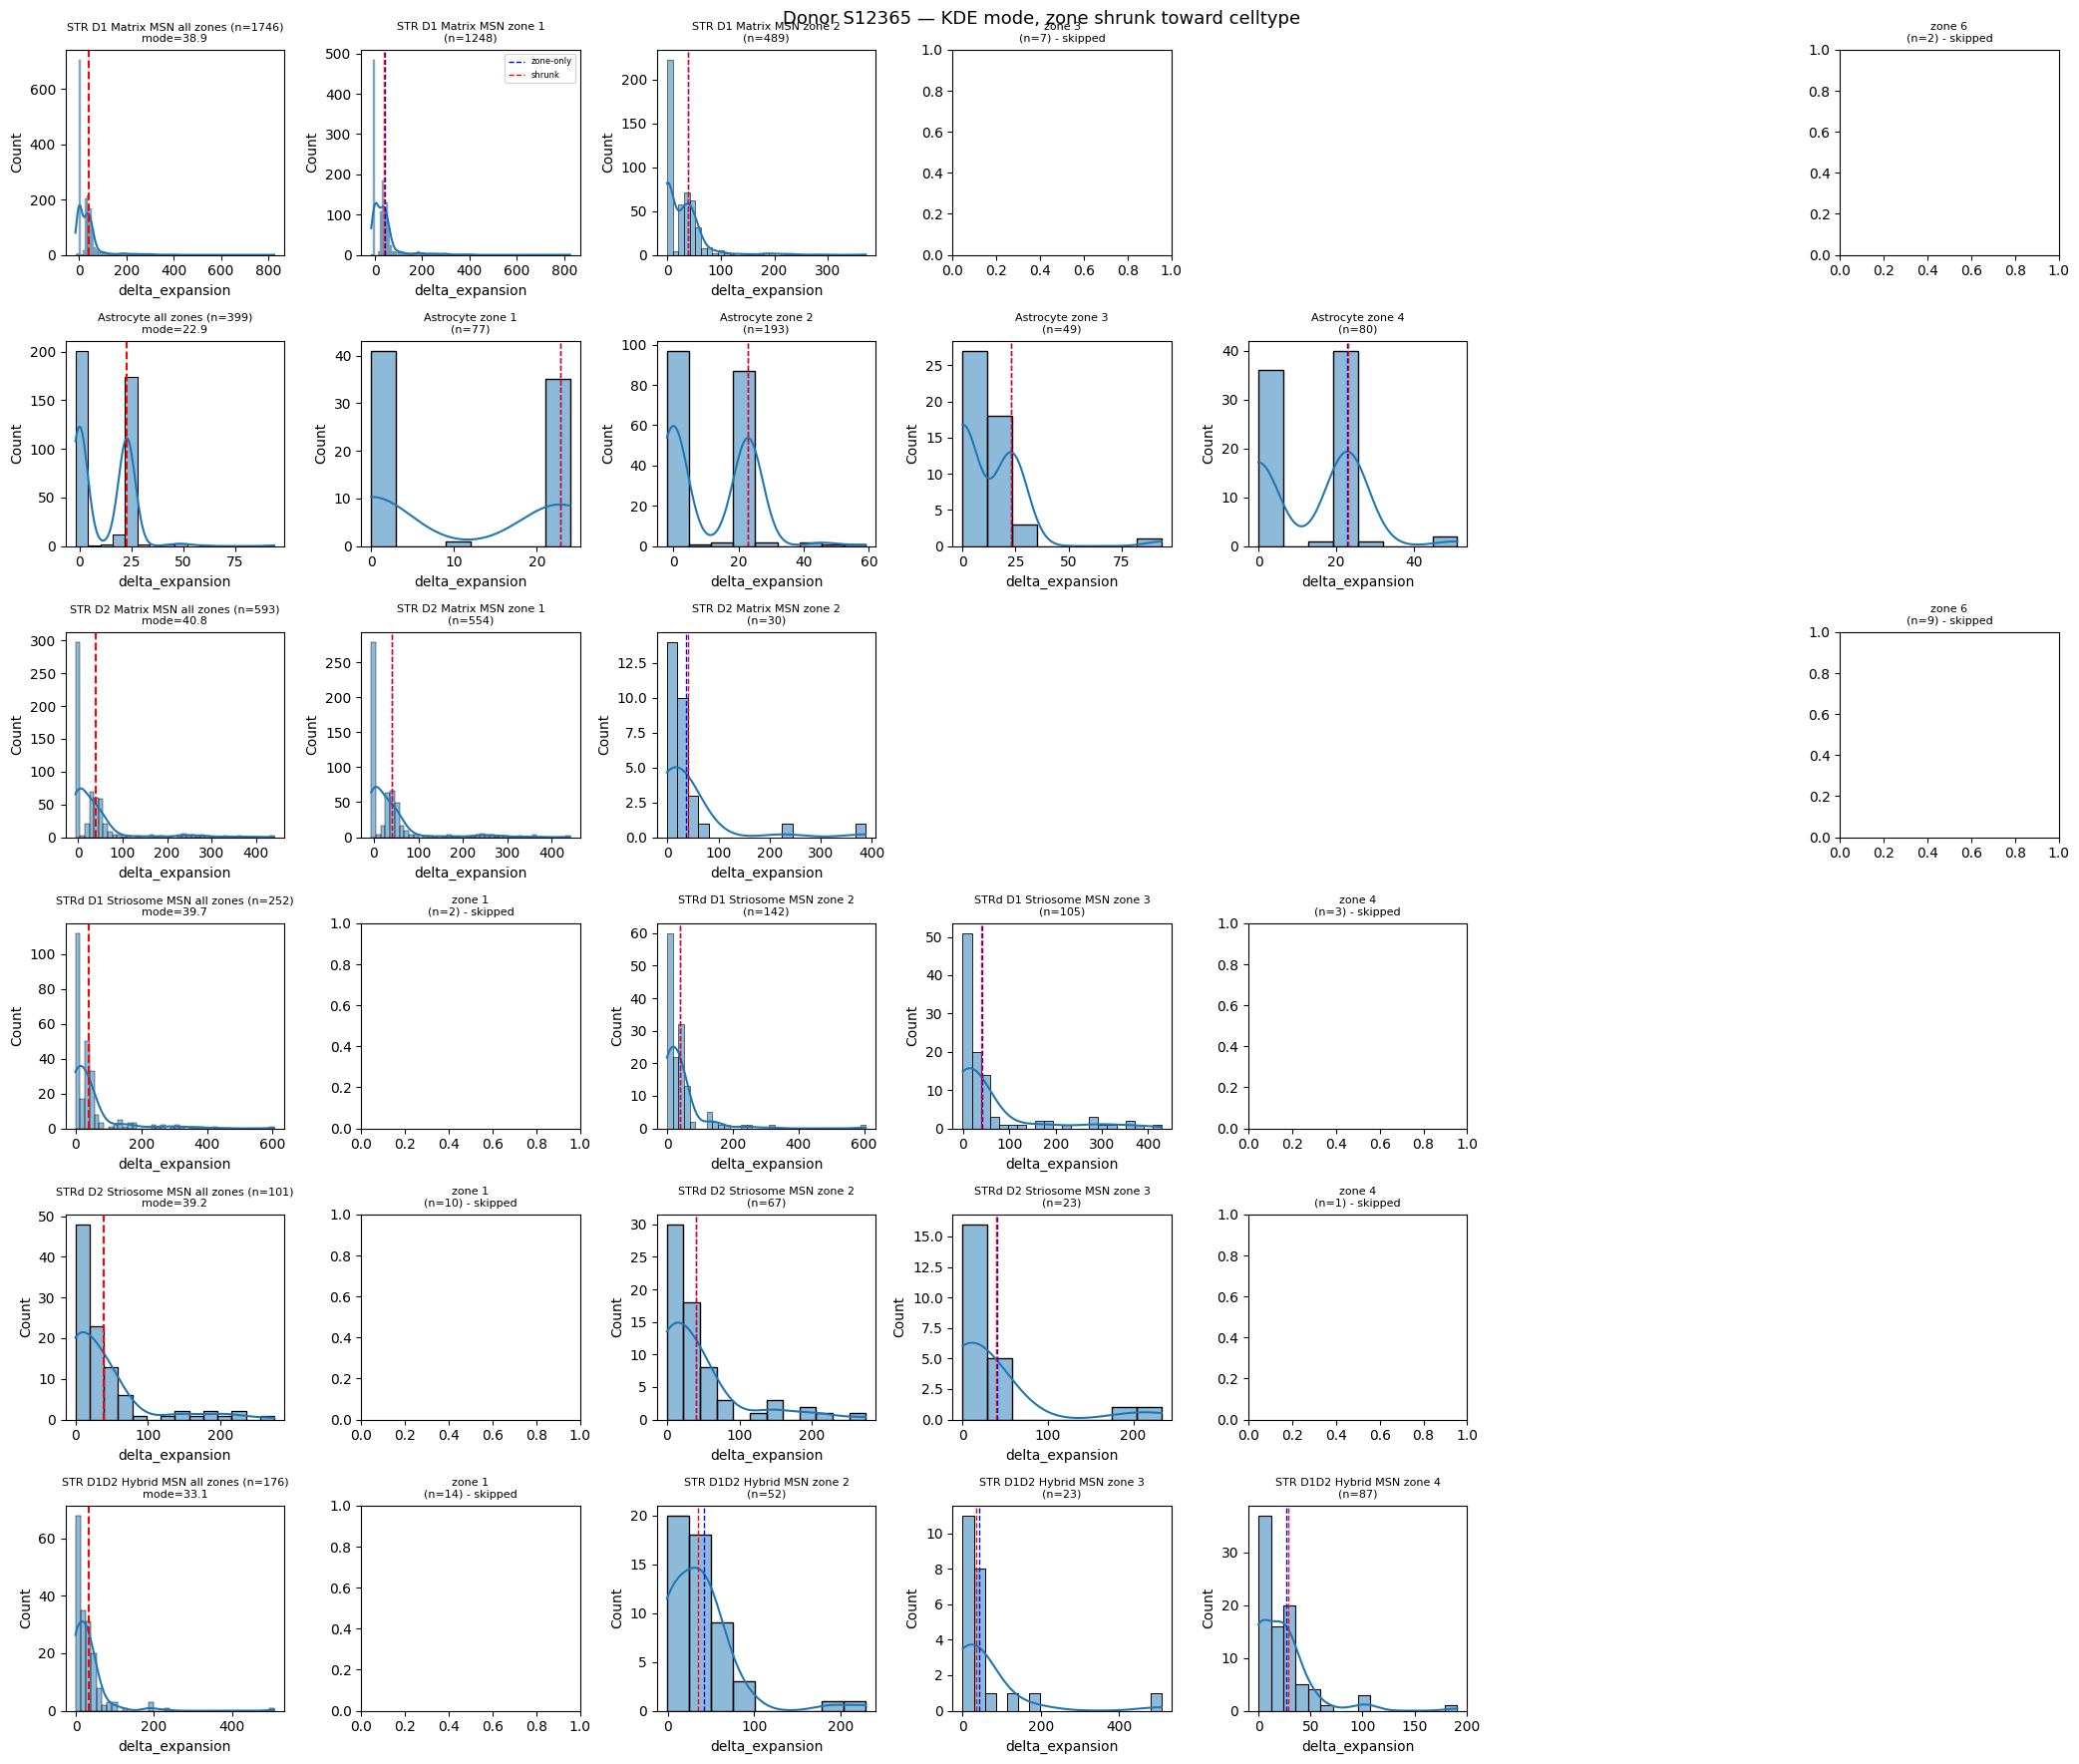

In [24]:
from scipy.stats import gaussian_kde


def _kde_mode(x, n_grid=300):
    kde = gaussian_kde(x)
    grid = np.linspace(x.min(), x.max(), n_grid)
    density = kde(grid)
    return grid[np.argmax(density)]


def find_mode_positive(x, noise_threshold=5, min_samples=10, n_grid=300, n_boot=100, random_state=0):
    """Most frequent (modal) delta_expansion value, excluding zero/near-zero noise.
    Returns (mode, mode_var, n); mode_var is a bootstrap estimate, used for shrinkage."""
    x = np.asarray(x)
    x_exp = x[x > noise_threshold]
    n = len(x_exp)
    if n < min_samples:
        return None, None, None

    mode = _kde_mode(x_exp, n_grid=n_grid)

    rng = np.random.default_rng(random_state)
    boot_modes = np.array([
        _kde_mode(rng.choice(x_exp, size=n, replace=True), n_grid=n_grid)
        for _ in range(n_boot)
    ])
    mode_var = np.var(boot_modes, ddof=1)

    return mode, mode_var, n


def shrink_toward_prior(estimate, estimate_var, prior_estimate, prior_var):
    """Precision-weighted average of a zone's own estimate and the celltype-level
    ('prior') estimate. Noisy/small-n zones get pulled harder toward the prior;
    precise zones stay close to their own value."""
    w_own, w_prior = 1 / estimate_var, 1 / prior_var
    return (estimate * w_own + prior_estimate * w_prior) / (w_own + w_prior)


all_zones = sorted(adata.obs["zone_mixed"].unique())
n_rows = len(ct_to_check)
n_cols = 1 + len(all_zones)

for donor in adata.obs["DONOR"].unique():
    print(donor)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows), squeeze=False)
    fig.suptitle(f"Donor {donor} — KDE mode, zone shrunk toward celltype", fontsize=13)

    for ax in axes.flat:
        ax.axis("off")

    for row, ct in enumerate(ct_to_check):
        tmp_sub = adata[(adata.obs["DONOR"] == donor) &
                        (adata.obs["mapping_coupling_for_zoning_mixed"] == ct)].copy()

        x = tmp_sub.obs["delta_expansion"].dropna().values
        ct_mode, ct_mode_var, ct_n = find_mode_positive(x)   # step 1: celltype-level "prior"

        ax = axes[row, 0]
        ax.axis("on")
        if ct_mode is None:
            ax.set_title(f"{ct}\n(n={tmp_sub.n_obs}) - skipped", fontsize=8)
        else:
            df.loc[donor, f"{ct}_mode"] = ct_mode
            sns.histplot(tmp_sub.obs["delta_expansion"], kde=True, ax=ax)
            ax.axvline(ct_mode, color="red", linestyle="--")
            ax.set_title(f"{ct} all zones (n={tmp_sub.n_obs})\nmode={ct_mode:.1f}", fontsize=8)

        for col, zone in enumerate(all_zones, start=1):   # step 2: per-zone fit, informed by step 1
            tmp_zone = tmp_sub[tmp_sub.obs["zone_mixed"] == zone].copy()
            if tmp_zone.n_obs == 0:
                continue

            x_zone = tmp_zone.obs["delta_expansion"].dropna().values
            zone_mode, zone_mode_var, zone_n = find_mode_positive(x_zone)

            ax = axes[row, col]
            ax.axis("on")
            if zone_mode is None or ct_mode is None:
                ax.set_title(f"zone {zone}\n(n={tmp_zone.n_obs}) - skipped", fontsize=8)
                continue

            shrunk_mode = shrink_toward_prior(zone_mode, zone_mode_var, ct_mode, ct_mode_var)

            df.loc[donor, f"{ct}_{zone}_mode_raw"] = zone_mode
            df.loc[donor, f"{ct}_{zone}_mode_shrunk"] = shrunk_mode

            sns.histplot(tmp_zone.obs["delta_expansion"], kde=True, ax=ax)
            ax.axvline(zone_mode, color="blue", linestyle="--", linewidth=1, label="zone-only")
            ax.axvline(shrunk_mode, color="red", linestyle="--", linewidth=1, label="shrunk")
            ax.set_title(f"{ct} zone {zone}\n(n={tmp_zone.n_obs})", fontsize=8)
            if row == 0 and col == 1:
                ax.legend(fontsize=6)

    plt.tight_layout()
    plt.show()

    #break


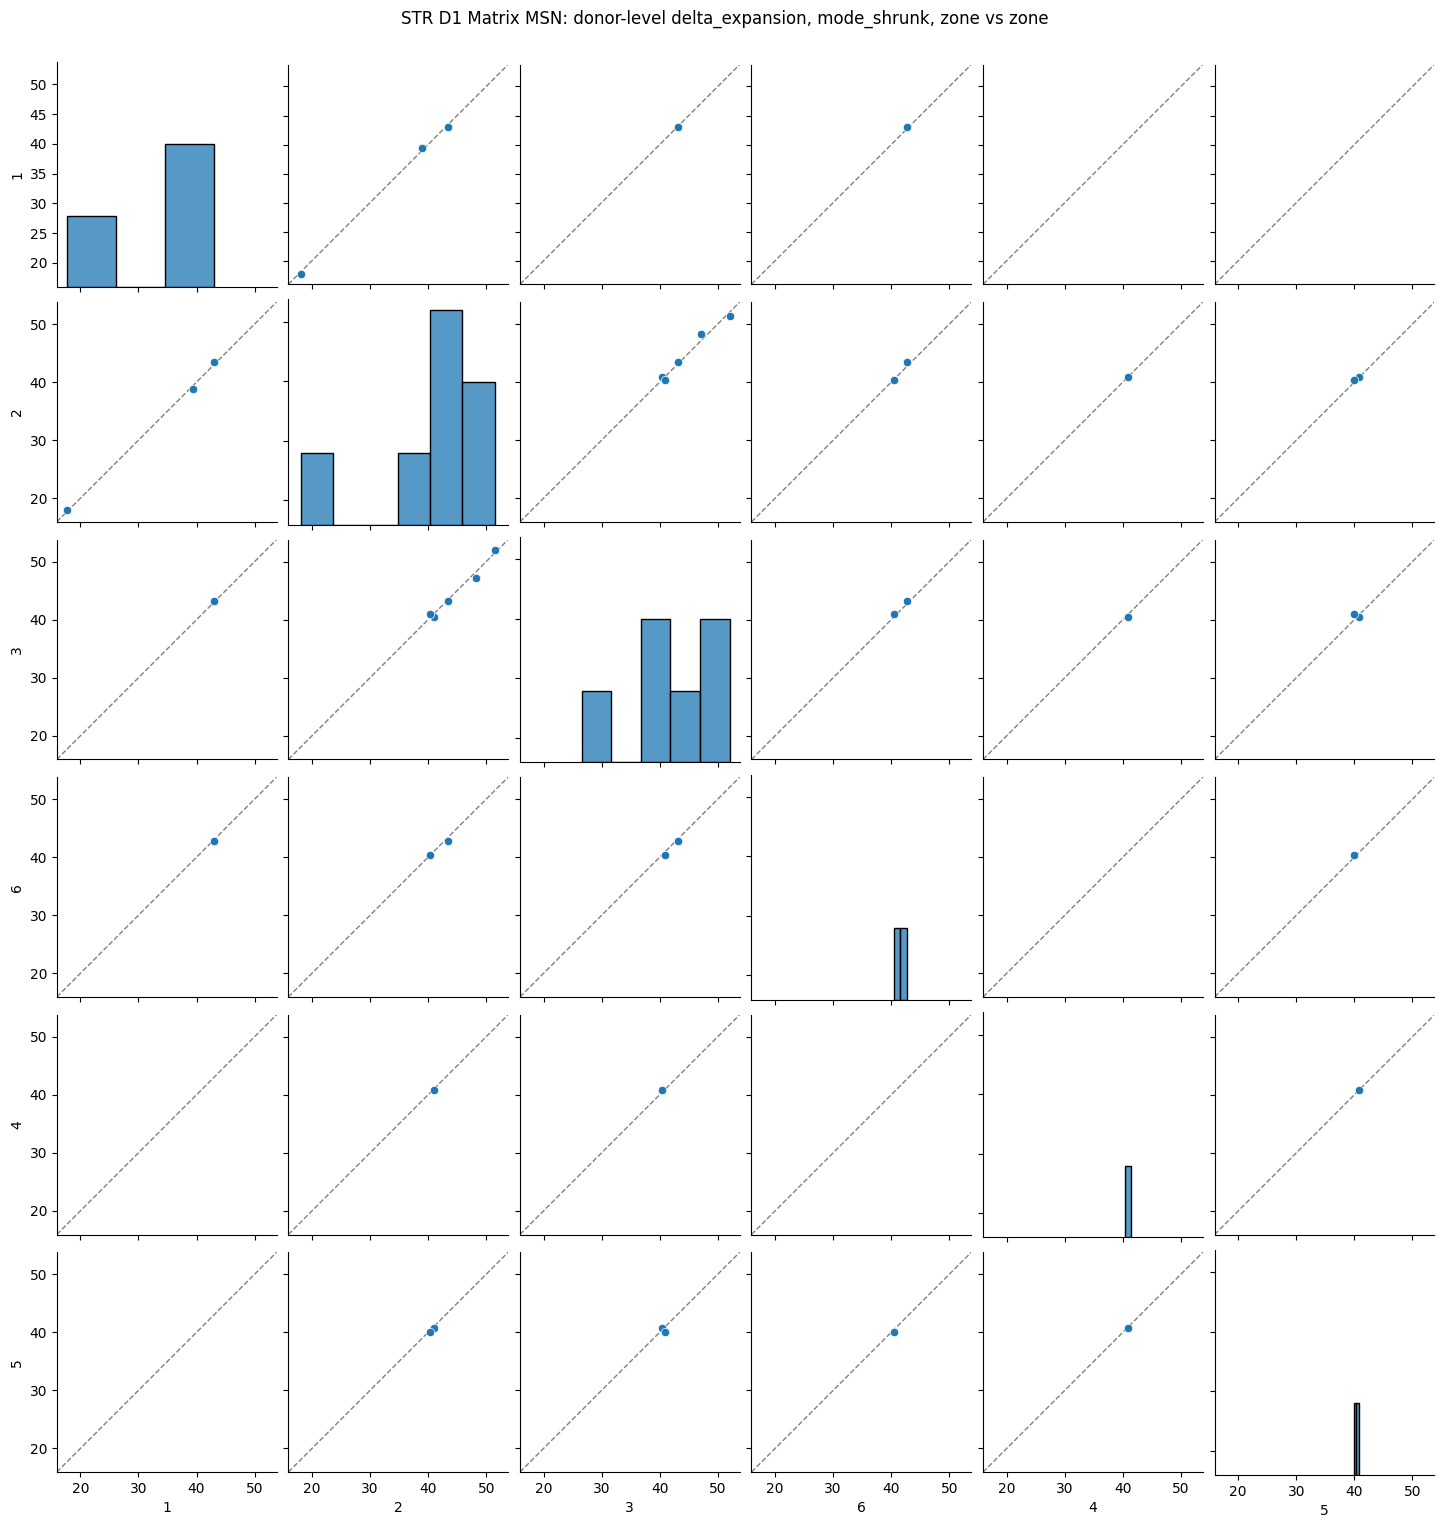

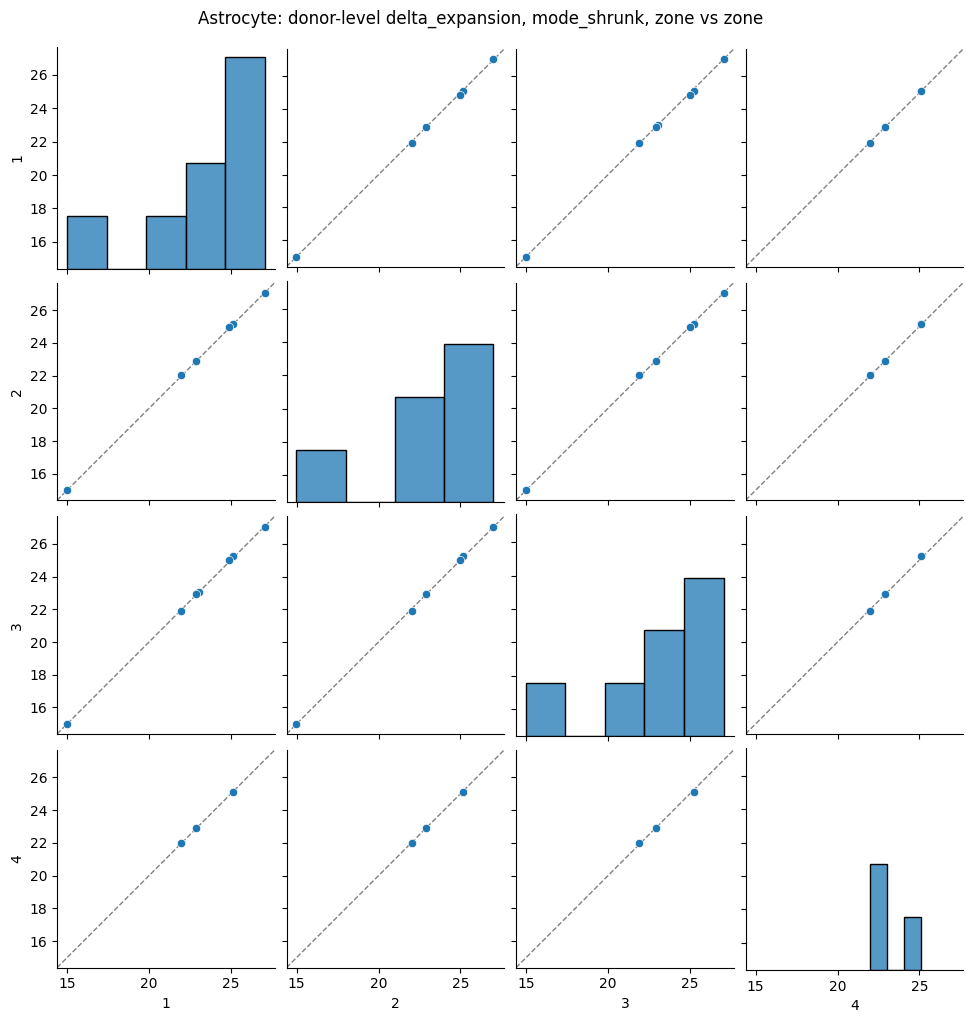

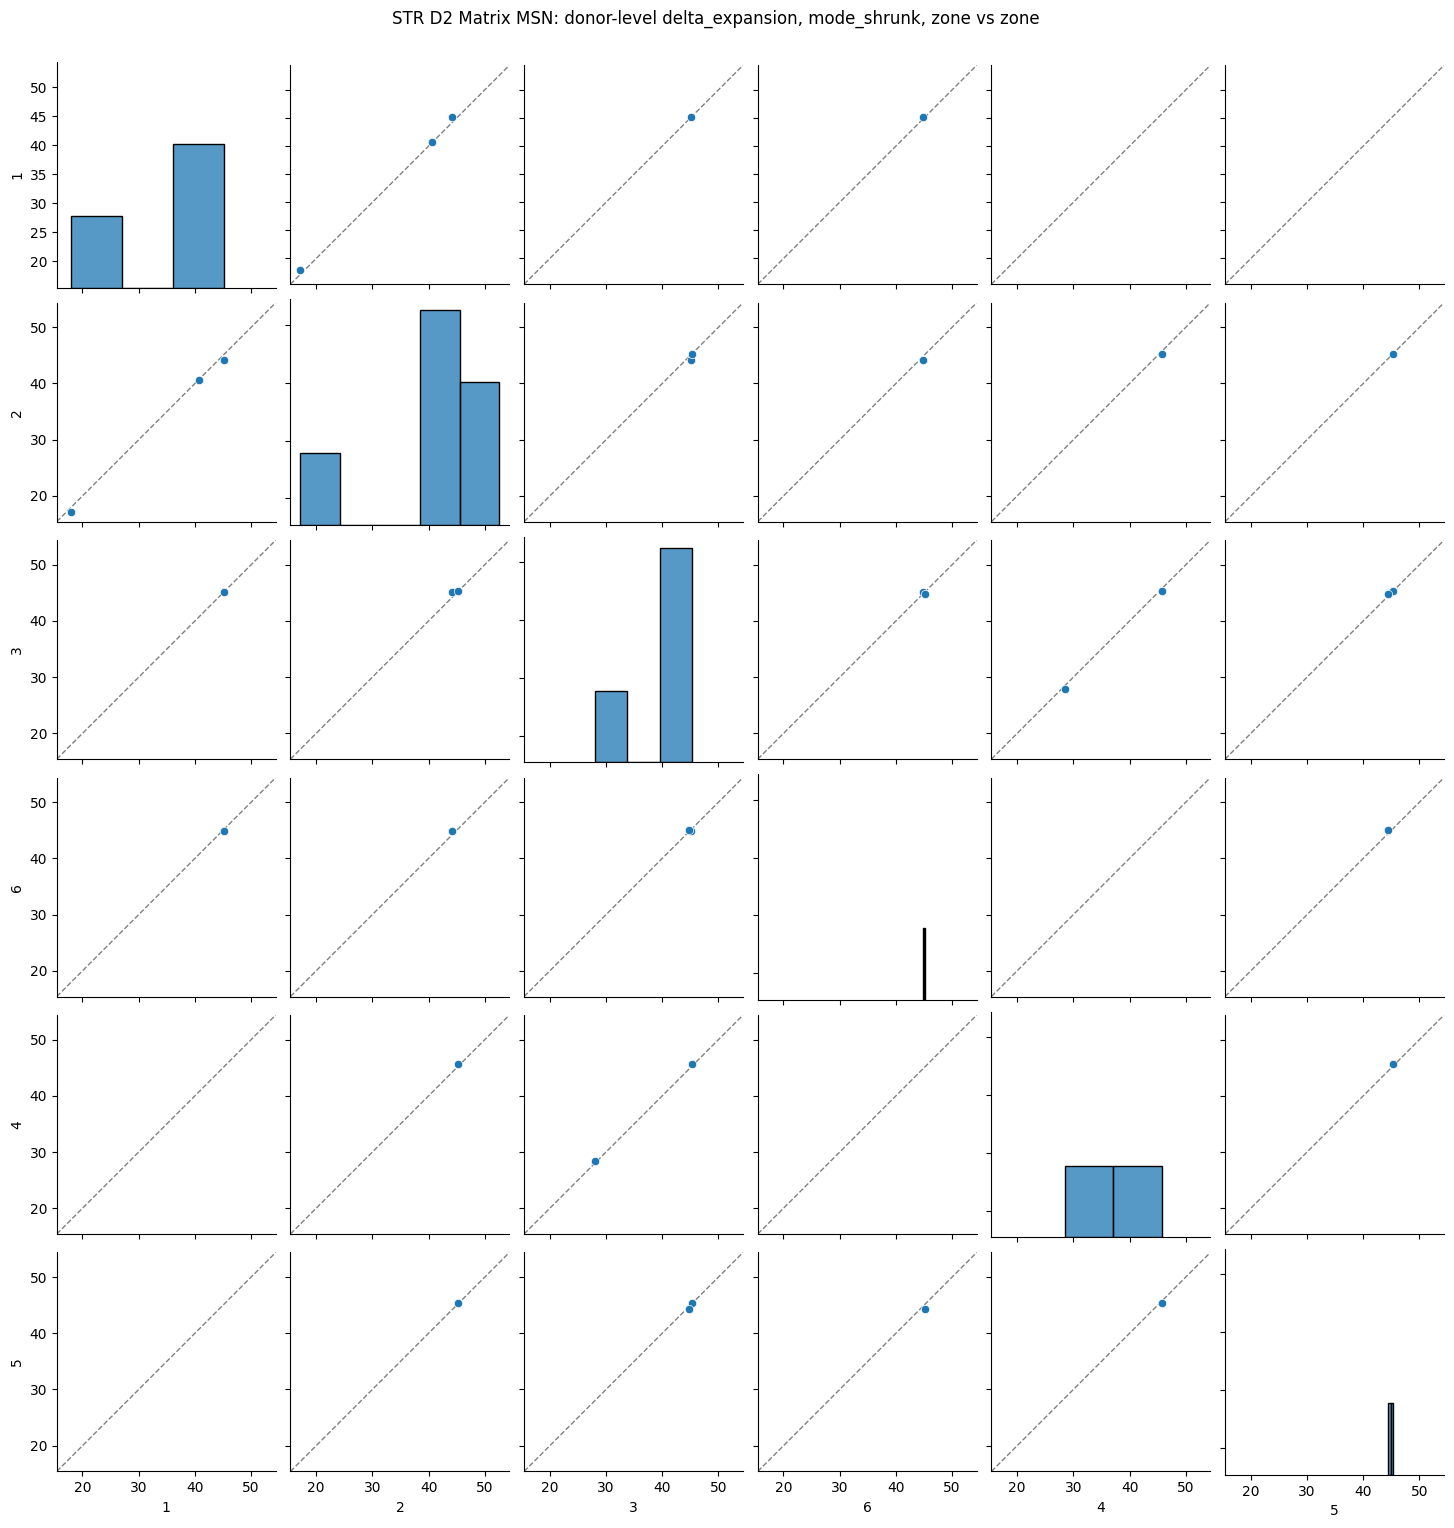

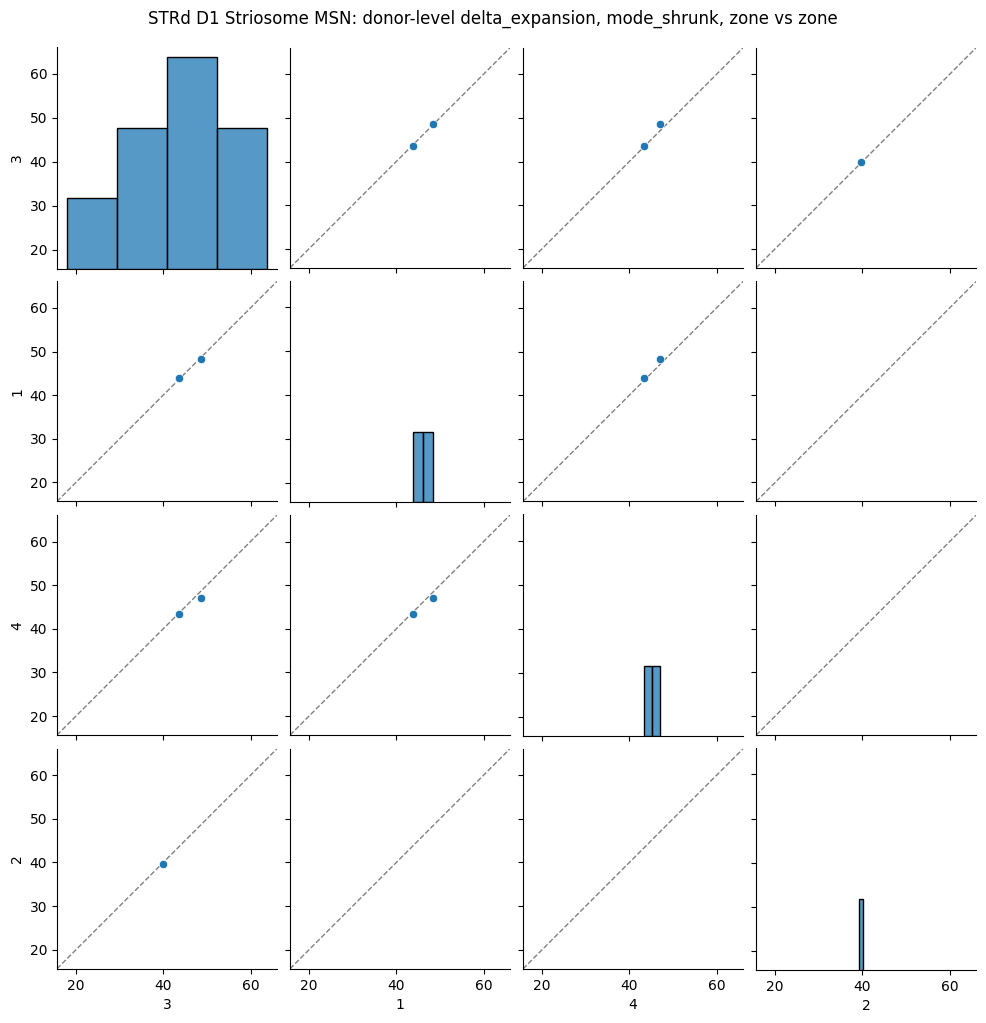

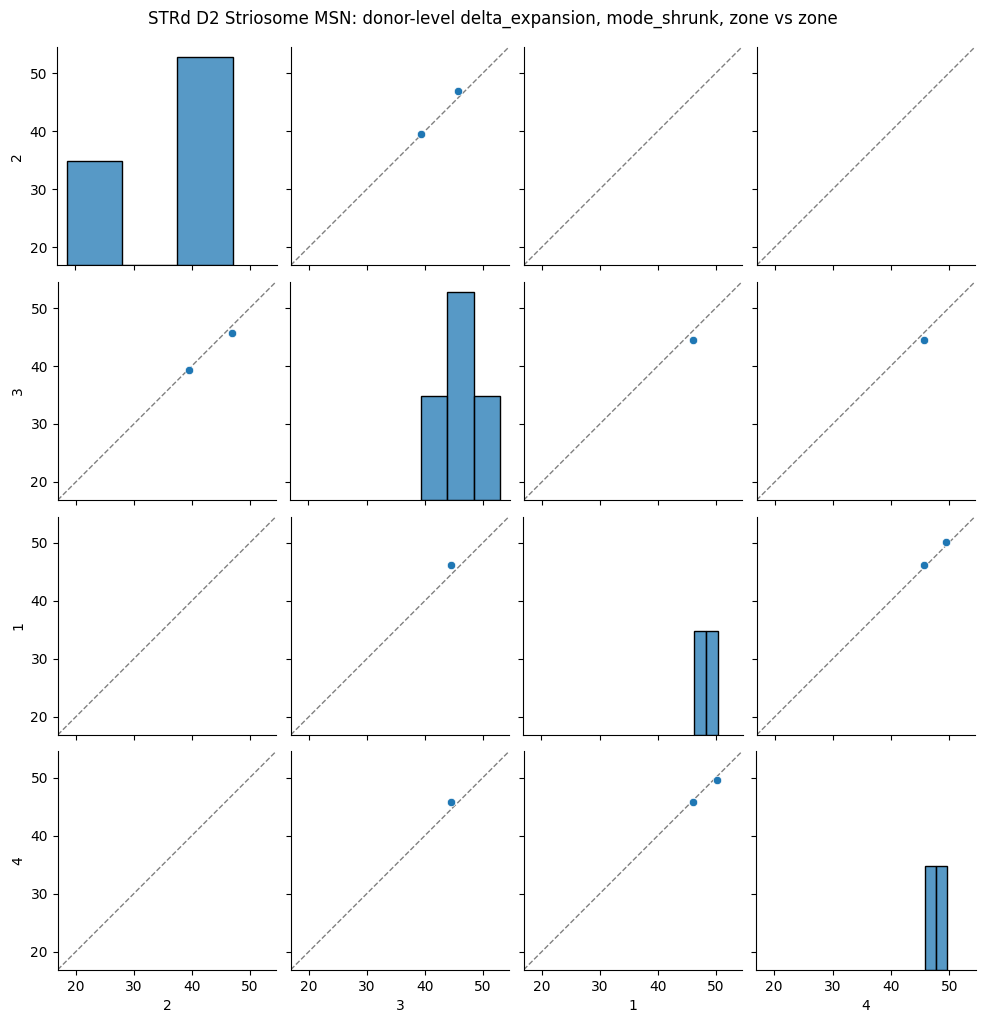

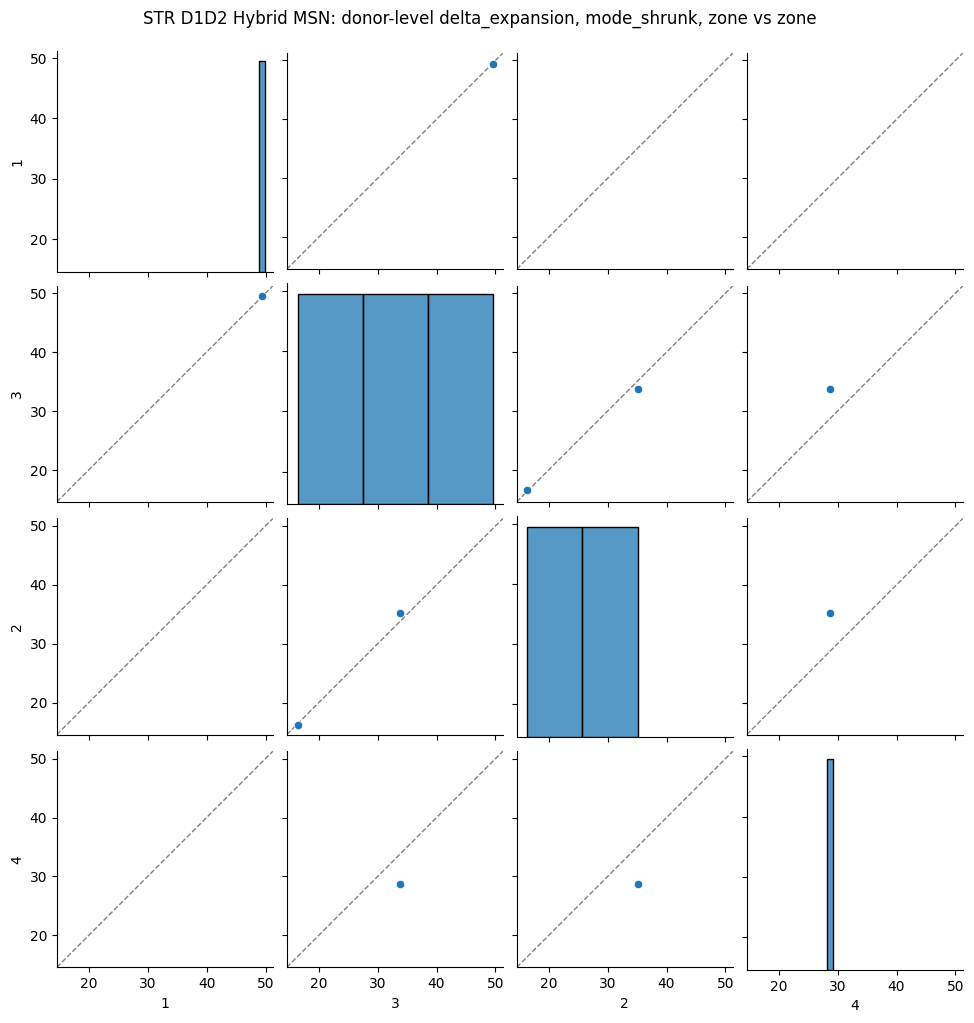

In [25]:
VALUE_SUFFIX = "mode_shrunk"   # or "mode_raw" if you want the un-shrunk, zone-only estimate

for ct in ct_to_check:
    zone_cols = [c for c in df.columns
                 if c.startswith(f"{ct}_") and c.endswith(f"_{VALUE_SUFFIX}")]

    if len(zone_cols) < 2:
        print(f"skipping {ct}: fewer than 2 zones with data")
        continue

    zone_df = df[zone_cols].copy()
    zone_df.columns = [c.replace(f"{ct}_", "").replace(f"_{VALUE_SUFFIX}", "") for c in zone_cols]

    vmin, vmax = zone_df.min().min(), zone_df.max().max()
    pad = 0.05 * (vmax - vmin)
    lims = (vmin - pad, vmax + pad)

    g = sns.pairplot(zone_df)

    for i in range(len(zone_df.columns)):
        for j in range(len(zone_df.columns)):
            ax = g.axes[i, j]
            ax.set_xlim(lims)
            if i != j:
                ax.set_ylim(lims)
                ax.set_aspect("equal", adjustable="box")
                ax.axline((0, 0), slope=1, color="gray", linestyle="--", linewidth=1, zorder=0)

    g.fig.suptitle(f"{ct}: donor-level delta_expansion, {VALUE_SUFFIX}, zone vs zone", y=1.02)
    plt.show()
